# IEEE-CIS Fraud Detection — Combined Baseline Models

**Break Through Tech AI Studio × Mastercard | Banking 1B**
**Builds on:** `BTT_Mastercard_EDA_Combined.ipynb` and `BTT_Mastercard_Feature_Engineering_Final.ipynb` (team feature tables in `fe_final_v1`)

This notebook combines the team's three baseline-modeling notebooks into one place, so every baseline model is trained and judged on **the same train/validation rows with the same metrics**.

### Who did what

| Person | Source notebook | What they contributed here | Where |
|---|---|---|---|
| **Jennifer** | `Jennifer_BTT_Mastercard_Baseline_Modeling.ipynb` | Research plan and hypotheses (H1–H8), data loading and checks, the shared metric functions (`evaluate`, TFPR, KS, top-k capture), Track A LightGBM with feature ablations, Track B logistic regression, Track C XGBoost deep-dive (ablations, settings check, incremental families, imbalance, tuning, SHAP, extra features, robustness, bootstrap, error analysis, blends, leakage test), follow-up experiments, decision log and handoff | Sections 0–14 |
| **Jean** | `Jean_Draft_Logistic_Regression.ipynb` (logistic-regression sections only) | A second logistic-regression pipeline: training-fitted sparse preprocessing layer, `C` grid × feature-set comparison, frozen 2% review threshold, coefficient table, saved model/report | Section B2 (inside Track B) |
| **Eric** (Kyaw Thi Ha) | `BTT_Mastercard_Small_Neural_Nets_Eric.ipynb` | Track D small neural networks: MLP size study, loss weighting, category embeddings, learning curves, seed stability, LightGBM comparison, blend test, calibration, segment and overlap analysis | Sections D0–D19 |

### How credit is marked

- Every **code cell** starts with a comment naming its author: `# [Jennifer]`, `# [Jean]` or `# [Eric]`.
- Every **markdown cell** has a **Work by: …** line (Eric's own "What I see" cells already say **[Eric]**).
- Cells written only to join the notebooks together are marked **[Merged notebook]**. They don't change anyone's results; they connect inputs, avoid name clashes, or collect results into shared tables.

### Notebook map

Section numbers are the authors' own: Jennifer's 0–14, Jean's B2.0–B2.5, Eric's D0–D19.

| Sections | Contents | Author |
|---|---|---|
| 0–3 | Plan, configuration, data loading and checks, evaluation metrics | Jennifer |
| 4 | Track A — LightGBM | Jennifer |
| 5 | Track B — Logistic regression (team baseline) | Jennifer |
| B2.0–B2.5 | Track B, continued — Jean's regularized logistic regression | Jean |
| 6, 6b–6s | Track C — XGBoost, quick run and deep-dive | Jennifer |
| 7–14 | Side-by-side results, findings, follow-up experiments, decision log, handoff | Jennifer |
| D0–D19 | Track D — Small neural networks | Eric |
| 7a–7d at the end | All-team scoreboard, Eric's findings, additions to the decision log, saved records | Merged notebook, Eric |

**Data policy (shared by everyone):** only **train** and **validation** are loaded. The labeled holdout stays untouched until the team freezes its final model. Jean's holdout step is kept but switched off (B2.5).

**Run order:** Sections 0–14 and B2 run top to bottom in one kernel. Eric's Sections D0–D19 is **self-contained**: it reloads its own data. On macOS, **restart the kernel before Section D0** (Eric found that PyTorch and LightGBM can deadlock when loaded in one process). The all-team scoreboard at the end reads the result files each part saved, so it works after the restart.

---
# Setup — Sections 0–3: plan, configuration, data and metrics

**Work by: Jennifer.** Everything in Sections 0–14 comes from Jennifer's baseline-modeling notebook. Its section numbers (0–14) are kept as they were. Jean's Section B2 and Eric's Sections D0–D19 reuse the configuration, the loaded tables and the `evaluate()` function defined here.

## Baseline Models, Feature Experiments, and Findings — introduction

**Work by: Jennifer**

**Break Through Tech AI Studio × Mastercard | Banking 1B**  
**Companion to:** `BTT_Mastercard_EDA_Combined.ipynb` and `BTT_Mastercard_Feature_Engineering_Final.ipynb`

## About this notebook

This notebook continues the team's shared workflow: **EDA → feature engineering → baseline models → evaluation → evidence-based decisions**. We follow the prior notebooks' style of numbered sections, a concrete question or hypothesis, code that tests it, checks of the result, and a decision log.

**Learning objective:** understand *why* every step exists before trying to improve metrics. Read the markdown before running each code cell; the point is not to generate a leaderboard number without knowing what it means.

### Three independent model tracks

| Track | Model | Mathematical idea | Input data | Why include it? |
|---|---|---|---|---|
| A | **LightGBM** | Ensemble of boosted decision trees | `X_tree_*` | Strong tabular baseline and feature ablations |
| B | **Logistic regression** | Weighted linear score passed through sigmoid | `X_nn_*` | Equally important simple, explainable baseline |
| C | **XGBoost** (team focus) | Another implementation of boosted decision trees | `X_nn_*` for the first quick run (6), then `X_tree_*` with native categoricals (6b-6m) | Main model: ablations, incremental families, imbalance, tuning, SHAP, extra features |

**Important:** the original modeling script trained **LightGBM and logistic regression**; it did *not* train XGBoost. This notebook offers XGBoost as an **additional independent model**. The `nn` file is a numeric/normalized feature table, *not a neural-network model*. No neural network is trained here.

**Data policy:** We only load **train** and **validation**. The labeled holdout remains untouched until the model-selection process is finished.

**Reading guide (for beginners):** Each experiment follows the same pattern as the team's exploratory analysis: **question → hypothesis → method → observed result → limits → next decision**. The existing outputs in this saved copy are from the team's real validation run. The XGBoost section (6+) and NEXT EXPERIMENTS 1-3 have been run on the validation split and their outputs are saved below; experiments switched off in the `RUN` flags (see 6b) show a 'skipped' message instead. No final holdout results are presented.

**All work lives here:** data loading, metric calculations, training of all three separate model types, feature experiments, findings, charts and final decision log. There is no need to consult a separate modeling script.


> **[Merged notebook] note on the introduction above:** Jennifer's notebook covered three tracks and said that no neural network is trained there. In this combined notebook, **Track B** also includes Jean's regularized logistic regression (Section B2), and **Track D** (Sections D0–D19) adds Eric's small neural networks.

## 0a. Big-picture map: what are we actually testing?

**Work by: Jennifer**

A machine-learning model learns a pattern from *training* examples in which we already know whether a payment was fraudulent (`isFraud = 1`) or legitimate (`isFraud = 0`). It then assigns a **fraud-risk score** to new transactions. Higher scores should ideally correspond to more suspicious transactions.

**Think of the workflow as four independent questions:**

1. **Can we trust the data?** Training transactions must happen earlier than validation transactions, and no future fraud answers may enter training features.
2. **Can a simple model find patterns?** Logistic regression gives us a transparent linear starting point. It is an essential baseline, not a throwaway model.
3. **Do more flexible models help?** LightGBM and XGBoost build many decision trees, learning interactions such as *high amount + unusual card pattern + missing identity*.
4. **Which features actually help on later transactions?** Compare a model with and without one feature family while keeping its algorithm and evaluation data fixed. This is called an **ablation**.

### Terminology used throughout

| Word | Beginner explanation |
|---|---|
| **Model** | A learned rule that maps input columns to a fraud-risk score |
| **Feature** | One input column, such as the transaction amount or a historical count |
| **Label** | The known answer: fraud (1) or legitimate (0) |
| **Train / fit** | Use labeled earlier transactions to learn model parameters |
| **Validation** | A later set used to compare models and choose settings; *not* the final unbiased test |
| **Holdout** | Last labeled time period reserved for the final evaluation, after decisions are fixed |
| **Seed** | A number controlling random choices; changing it can change fitted trees |
| **Ablation** | Remove a specific group of columns, retrain, and measure how results change |
| **Early stopping** | Stop adding trees once a chosen validation metric stops improving |

**Important:** the three models are trained in separate sections. Running one section does not secretly start the others.


## 0. Research question and experimental plan

**Work by: Jennifer**

**Situation.** IEEE-CIS has hundreds of predictors and relatively few fraudulent payments. The team created many engineered columns: target encodings, account histories, velocity statistics, and missingness indicators. More columns do *not* automatically make a better model.

**Main question.** Does feature engineering allow us to catch more fraud at a useful level of false alarms **on later transactions**?

**Plan (same hypothesis → test → check format as the EDA)**

- **H1 — Model family:** a boosted-tree model will rank fraud better than an ordinary linear baseline. Test with the same chronological validation period, while stating that their input tables differ.
- **H2 — Feature engineering:** the full feature set improves on raw inputs. Compare named feature sets using LightGBM.
- **H3 — Target encoding:** removing `te_` features lowers performance. Test a targeted ablation.
- **H4 — Behavioral history:** removing `beh_` and `vel_` changes performance, particularly when `addr1` is missing.
- **H5 — Operational usefulness:** results must remain meaningful at review-rate / false-positive constraints—not just ROC-AUC.

A **baseline** is a reproducible reference model, *not* a model assumed to be weak. An **ablation** removes a chosen feature family while holding the modeling procedure as constant as practical. Never infer a feature's *incremental* benefit from its importance ranking alone.

**Notebook flow:** setup → data validation → worked metrics → Track A LightGBM → Track B logistic regression → Track C XGBoost → cross-model interpretation → limitations and decisions.

## 1. Configuration and libraries

**Work by: Jennifer**

**Why configure first?** A model result is useful only if another teammate can reproduce it. We keep the input location, seed, hyperparameters, selected feature sets, and output directory together rather than scattering magic numbers throughout the notebook.

**Dependency setup (run once in the active Python environment if needed):**

```bash
python -m pip install pandas numpy pyarrow matplotlib scikit-learn lightgbm xgboost ipykernel
```

`xgboost` is used only in Track C. If you are starting with Tracks A and B, you do not need to import or install it yet.

**Fair comparison reminder:** do not change both the model configuration and feature list when testing a feature hypothesis, or you cannot attribute the difference to one change.

In [1]:
# [Jennifer]
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

FE_DIR = Path("outputs/feature_engineering/fe_final_v1")
OUTPUT_DIR = FE_DIR / "baselines" / "student_explained_v2"
SEEDS = [0]     # Change to [0, 1, 2] when you want repeatability checks.
N_JOBS = 4      # Shared thread setting for reproducible experiments; adjustable for available hardware.
LIGHTGBM_SETS_TO_RUN = ["raw", "all", "all_minus_target_encoding", "all_minus_behavior"]

FPR_TARGETS = [0.001, 0.005, 0.01]
DETECTION_TARGETS = [0.50, 0.60, 0.70, 0.80, 0.90]
REVIEW_RATES = [0.01, 0.05, 0.10, 0.20]
FORBIDDEN = {"isFraud", "TransactionID", "TransactionDT"}

LGBM_PARAMS = dict(objective="binary", metric="average_precision",
                   n_estimators=6000, learning_rate=0.05, num_leaves=63,
                   min_child_samples=100, subsample=0.8, subsample_freq=1,
                   colsample_bytree=0.5, reg_lambda=1.0)

print("Data directory:", FE_DIR.resolve())
assert (FE_DIR / "manifest.json").exists(), "No manifest.json found. Run from the repo root or adjust FE_DIR."
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

Data directory: /Users/Jennifer/Developer/BTT Fall AI Studio/Banking-1B-online-payment-fraud-detection-using-high-dimensional-transaction-data/notebooks/outputs/feature_engineering/fe_final_v1


### 1a. What are these settings doing?

**Work by: Jennifer**

- **Random seed:** controls randomness in algorithms such as feature/row subsampling. The same seed supports a reproducible comparison; trying three seeds checks sensitivity to this randomness, **not** full statistical uncertainty.
- **`learning_rate=0.05`:** each new tree makes a relatively small correction; a smaller step often requires more trees.
- **`n_estimators=6000`:** *maximum* trees; early stopping can select far fewer. A run at the cap may need additional tuning.
- **`num_leaves=63`:** upper bound on tree complexity. More leaves can fit complex patterns and overfit.
- **`min_child_samples=100`:** discourages splits supported by only a few rows.
- **`subsample` and `colsample_bytree`:** intentionally vary the training examples/features seen by trees; can reduce overfitting and introduce seed variation.
- **`reg_lambda`:** penalizes overly complex predictions.

**Check:** changing hyperparameters while doing an ablation would confound the feature comparison. For now keep them fixed.

## 2. Load the team's saved feature-engineering outputs

**Work by: Jennifer**

**Why not rerun preprocessing here?** The feature-engineering notebook has already fitted transformations using the training period. Loading its saved outputs keeps *all* baseline models aligned to the same input rules and avoids accidentally fitting target encodings or scalers on validation data.

The manifest tells us which columns belong to `raw`, `all`, `all_no_history`, and other feature sets.

**Data leakage example:** if a category's target-encoding value is computed using validation fraud labels, it gives the model information that would not exist when predicting future fraud. No validation or holdout labels may be used to **fit** the encoders.

We also verify that predictors do not include `isFraud` (the answer), `TransactionID` (a row identifier), or `TransactionDT` (used to order the split and excluded by this experiment's design). These checks **cannot on their own prove every derived feature is leakage-free**.

In [2]:
# [Jennifer]
manifest = json.loads((FE_DIR / "manifest.json").read_text())

def load_features(split, kind):
    X = pd.read_parquet(FE_DIR / f"X_{kind}_{split}.parquet")
    y = pd.read_parquet(FE_DIR / f"y_{split}.parquet")["isFraud"]
    if not X.index.equals(y.index):
        raise ValueError(f"Misaligned features and labels for {kind}/{split}")
    if not FORBIDDEN.isdisjoint(X.columns):
        raise ValueError(f"Forbidden predictor found in {kind}/{split}")
    if X.columns.duplicated().any():
        raise ValueError(f"Duplicate predictor columns for {kind}/{split}")
    return X, y

X_train, y_train = load_features("train", "tree")
X_val, y_val = load_features("validation", "tree")
assert list(X_train.columns) == list(X_val.columns), "Train/validation schema differs."
assert y_train.isin([0, 1]).all() and y_val.isin([0, 1]).all()
assert X_train.index.intersection(X_val.index).empty, "Index overlap across splits."
assert "TransactionAmt" in X_val.columns, "Dollar-capture metrics need TransactionAmt."
amount_val = X_val["TransactionAmt"].to_numpy(dtype=float)

print(f"Train: {len(X_train):,} rows | fraud rate {y_train.mean():.2%}")
print(f"Validation: {len(X_val):,} rows | fraud rate {y_val.mean():.2%}")
print("Tree table:", X_train.shape[1], "columns")
print("Manifest sets:", {k: len(v) for k, v in manifest["feature_sets"].items()})
print("Holdout was NOT loaded.")

Train: 472,432 rows | fraud rate 3.51%
Validation: 59,054 rows | fraud rate 3.13%
Tree table: 537 columns
Manifest sets: {'raw': 430, 'all_no_history': 489, 'all': 537, 'all_reduced_v': 408, 'all_no_jennifer': 502}
Holdout was NOT loaded.


### 2a. Data sanity checks — what would fail and why?

**Work by: Jennifer**

**Question:** Are we actually comparing the same transactions?

- **Same feature schema** in train and validation: avoids accidental differences in learned categories.
- **Row-label index alignment:** otherwise a transaction could be assigned somebody else's fraud label—a silent, catastrophic modeling error.
- **Disjoint row indices:** protects against obvious overlap, but this is **not** a substitute for verifying the chronological boundary in the FE notebook.
- **Both classes present:** metrics such as ROC-AUC require examples of both fraud and legitimate transactions.

**Expected output:** approximately 472,432 train and 59,054 validation transactions. The measured validation fraud rate is the no-skill reference for average precision.

**Do not** interpret `0.60` PR-AUC against a `0.50` no-skill line; with rare fraud the no-skill AP is close to the actual fraud prevalence.

## 3. Understand the evaluation metrics *before* training

**Work by: Jennifer**

### 3a. Confusion matrix and the cost of mistakes

We call a transaction **positive** when we flag it as fraud:

| | Actually fraud | Actually legitimate |
|---|---|---|
| Flagged as fraud | **TP**: caught fraud | **FP**: legitimate customer flagged |
| Not flagged | **FN**: missed fraud | **TN**: legitimate transaction left alone |

- **Recall / detection rate** = `TP / (TP + FN)`. Of all fraud cases, how many did we catch?
- **Precision** = `TP / (TP + FP)`. Among the flagged cases, how many were really fraud?
- **Conventional FPR** = `FP / (FP + TN)`. Of all legitimate payments, what fraction did we inconvenience?
- **TFPR (advisor's operational ratio)** = `FP / TP`. How many legitimate payments are flagged *per fraud caught*? **TFPR and FPR are not the same.**

**Worked example:** suppose 1,000 payments contain 30 fraud cases. A threshold catches 18 frauds and flags 9 legitimate payments: recall `18/30 = 60%`; precision `18/(18+9) = 66.7%`; FPR `9/970 ≈ 0.93%`; TFPR `9/18 = 0.5:1`. It is possible to have low FPR yet still review many legitimate payments because fraud is uncommon.

### 3b. Ranking metrics versus threshold metrics

A model produces a **score**, not a binary decision until we choose a **threshold**.

- **Average precision (`pr_auc` in output):** summarizes precision as recall increases; baseline is roughly fraud prevalence. We report `average_precision_score`, which is not exactly trapezoidal area-under-PR-curve.
- **ROC-AUC:** how often a random fraudulent transaction ranks above a random legitimate one (with half-credit for ties).
- **KS:** maximum across thresholds of `TPR − FPR`, measuring separation between fraud and legitimate score distributions.
- **Recall at fixed FPR:** how much fraud we can catch **without exceeding** a chosen false-alarm budget.
- **TFPR at 50%, 60%, ... detection:** for the first achievable threshold meeting recall, how many false alerts do we create per caught fraud?
- **Top 1/5/10/20% review capture:** pretend analysts examine only the highest-scoring fraction of transactions. Report the fraud cases and **transaction dollars associated with fraud**, not verified financial losses, in that fraction.

**Why actual thresholds?** Scores have ties and transactions cannot be split into fractional people. The helper below groups tied scores for threshold metrics instead of linearly interpolating between confusion matrices.

In [3]:
# [Jennifer]
def ranked_operating_points(y, score):
    """Threshold operating points, sorted from highest to lowest score; include ties together."""
    y = np.asarray(y, dtype=int)
    s = np.asarray(score, dtype=float)
    if len(y) != len(s) or not np.isfinite(s).all():
        raise ValueError("Scores must be finite and aligned to labels")
    order = np.argsort(-s, kind="stable")
    y_sort, s_sort = y[order], s[order]
    n_fraud = int(y.sum())
    n_legit = len(y) - n_fraud
    if n_fraud == 0 or n_legit == 0:
        raise ValueError("Need fraud and legitimate examples to calculate the metrics")
    # Include the entire group of transactions at each unique score threshold.
    group_end = np.r_[np.flatnonzero(np.diff(s_sort) != 0), len(s_sort) - 1]
    tp = np.cumsum(y_sort)[group_end]
    flagged = group_end + 1
    fp = flagged - tp
    return pd.DataFrame({
        "threshold": s_sort[group_end], "tp": tp, "fp": fp,
        "recall": tp / n_fraud, "fpr": fp / n_legit,
        "tfpr": np.divide(fp, tp, out=np.full(len(tp), np.nan, dtype=float), where=tp > 0),
        "review_rate": flagged / len(y),
    })


def evaluate(y, score, amount):
    """Return practical, threshold-based fraud evaluation metrics."""
    y = np.asarray(y, dtype=int)
    s = np.asarray(score, dtype=float)
    amt = np.asarray(amount, dtype=float)
    if not (len(y) == len(s) == len(amt)):
        raise ValueError("Label, score, and amount vectors do not align")
    op = ranked_operating_points(y, s)
    roc_fpr, roc_tpr, _ = roc_curve(y, s)
    out = {
        "fraud_rate": y.mean(), "pr_auc": average_precision_score(y, s),
        "roc_auc": roc_auc_score(y, s), "ks": float(np.max(roc_tpr - roc_fpr)),
    }
    for budget in FPR_TARGETS:
        allowed = op.loc[op.fpr <= budget, "recall"]
        out[f"recall_at_{budget * 100:g}pct_fpr"] = float(allowed.max()) if len(allowed) else 0.0
    for target in DETECTION_TARGETS:
        eligible = op.loc[op.recall >= target]
        first = eligible.iloc[0] if len(eligible) else None
        suffix = f"{int(target * 100)}pct_detection"
        out[f"tfpr_at_{suffix}"] = float(first.tfpr) if first is not None else np.nan
        out[f"achieved_recall_at_{suffix}"] = float(first.recall) if first is not None else np.nan
        out[f"review_rate_at_{suffix}"] = float(first.review_rate) if first is not None else np.nan
    order = np.argsort(-s, kind="stable")
    ys, amts = y[order], amt[order]
    n_fraud = int(y.sum())
    total_fraud_amt = float(np.sum(amt * y))
    for k in REVIEW_RATES:
        top_n = max(1, int(round(len(y) * k)))
        out[f"fraud_cases_top{k * 100:g}pct"] = float(ys[:top_n].sum() / n_fraud)
        out[f"fraud_dollars_top{k * 100:g}pct"] = (float((ys[:top_n] * amts[:top_n]).sum()) / total_fraud_amt
                                                 if total_fraud_amt > 0 else np.nan)
    return out


def ks_table(y, score, buckets=20):
    """Equal-sized score-rank buckets with running detection and false alert totals."""
    d = pd.DataFrame({"y": np.asarray(y), "score": np.asarray(score, dtype=float)})
    d = d.sort_values("score", ascending=False, kind="stable").reset_index(drop=True)
    d["bucket"] = np.minimum(np.floor(np.arange(len(d)) * buckets / len(d)).astype(int) + 1, buckets)
    t = d.groupby("bucket", observed=True).agg(n=("y", "size"), fraud=("y", "sum"))
    t["legit"] = t["n"] - t["fraud"]
    t["flagged_share"] = t["n"].cumsum() / t["n"].sum()
    t["detection_rate"] = t["fraud"].cumsum() / t["fraud"].sum()
    t["share_of_legit_flagged"] = t["legit"].cumsum() / t["legit"].sum()
    t["tfpr"] = t["legit"].cumsum() / t["fraud"].cumsum().replace(0, np.nan)
    t["ks"] = t["detection_rate"] - t["share_of_legit_flagged"]
    return t

# Smoke test with four synthetic transactions (no model training).
example = evaluate([1, 0, 1, 0], [0.9, 0.8, 0.4, 0.1], [100, 20, 40, 50])
assert np.isclose(example["fraud_rate"], 0.5)
assert np.isclose(example["tfpr_at_50pct_detection"], 0.0)
print("Metric functions passed a small smoke test.")

Metric functions passed a small smoke test.


### 3c. Practice on a four-transaction example

**Work by: Jennifer**

Consider predicted fraud scores `[0.90, 0.80, 0.40, 0.10]` with real labels `[fraud, legitimate, fraud, legitimate]`.

At threshold `0.90` we flag **one fraud and zero legitimate** payments: recall is `1/2 = 50%`; TFPR is `0/1 = 0:1`. At threshold `0.40` we flag **two fraud and one legitimate**: recall `100%`; precision `2/3`; TFPR `1/2 = 0.5:1`.

Try changing the second score from `0.80` to `0.95`. **Before running the cell, predict:** does top-1 review capture improve or worsen? Why?

**Check:** the metric helpers run on this tiny synthetic dataset before we trust them on real transactions. Smoke tests can catch arithmetic mistakes but cannot detect all pipeline bugs.

In [4]:
# [Jennifer]
demo_y = np.array([1, 0, 1, 0])
demo_score = np.array([0.90, 0.80, 0.40, 0.10])
demo_amount = np.array([100, 20, 40, 50])
display(ranked_operating_points(demo_y, demo_score).round(3))
print("Worked-example metrics:")
display(pd.Series(evaluate(demo_y, demo_score, demo_amount)).round(3))

,threshold,tp,fp,recall,fpr,tfpr,review_rate
0,0.9,1,0,0.5,0.0,0.0,0.25
1,0.8,1,1,0.5,0.5,1.0,0.50
2,0.4,2,1,1.0,0.5,0.5,0.75
3,0.1,2,2,1.0,1.0,1.0,1.00


Worked-example metrics:


fraud_rate                            0.500
pr_auc                                0.833
roc_auc                               0.750
ks                                    0.500
recall_at_0.1pct_fpr                  0.500
recall_at_0.5pct_fpr                  0.500
recall_at_1pct_fpr                    0.500
tfpr_at_50pct_detection               0.000
achieved_recall_at_50pct_detection    0.500
review_rate_at_50pct_detection        0.250
tfpr_at_60pct_detection               0.500
achieved_recall_at_60pct_detection    1.000
review_rate_at_60pct_detection        0.750
tfpr_at_70pct_detection               0.500
achieved_recall_at_70pct_detection    1.000
review_rate_at_70pct_detection        0.750
tfpr_at_80pct_detection               0.500
achieved_recall_at_80pct_detection    1.000
review_rate_at_80pct_detection        0.750
tfpr_at_90pct_detection               0.500
achieved_recall_at_90pct_detection    1.000
review_rate_at_90pct_detection        0.750
fraud_cases_top1pct             

---
# Section 4 — Track A: LightGBM

**Work by: Jennifer**

## 4. Track A — LightGBM: nonlinear tree-based baseline

**Work by: Jennifer**

**Research question:** do the engineered features allow LightGBM to distinguish fraud from legitimate transactions better than the raw inputs?

**Intuition:** A single tree asks yes/no questions such as *Is the amount unusually high?* and *Is this device uncommon?* LightGBM builds many trees sequentially. Later trees focus on correcting mistakes from earlier ones. This can represent nonlinear cutoffs and interactions without manually specifying every combination.

**Why use the tree table?** LightGBM handles missing numeric values and can work with categorical pandas columns; the saved `X_tree_*` outputs were constructed for this type of model.

**Why this is not XGBoost:** both are gradient-boosted-tree libraries, but their implementations, categorical handling and training behavior are different. We run XGBoost separately in Track C.

### 4a. Feature-set ablation hypotheses

| Set | What it tests |
|---|---|
| `raw` | What happens with original features alone? |
| `all` | What happens with all features the team engineered? |
| `all_minus_target_encoding` | Do `te_` features add predictive value? |
| `all_minus_behavior` | Do `beh_` and `vel_` add predictive value? |
| `all_no_history` (optional) | Do history-related features help overall? |
| `all_reduced_v` (optional) | Can we remove redundant V columns without losing meaningful performance? |

**Important:** when comparing `all` to `all_minus_target_encoding`, keep LightGBM settings and split identical. If full does better, that is *evidence* for the feature family; tiny differences may be unstable.

In [5]:
# [Jennifer]
feature_sets = {name: list(cols) for name, cols in manifest["feature_sets"].items()}
all_cols = feature_sets["all"]
target_cols = [c for c in all_cols if c.startswith("te_")]
behavior_cols = [c for c in all_cols if c.startswith(("beh_", "vel_"))]
feature_sets["all_minus_target_encoding"] = [c for c in all_cols if c not in set(target_cols)]
feature_sets["all_minus_behavior"] = [c for c in all_cols if c not in set(behavior_cols)]
feature_sets["all_minus_target_and_behavior"] = [
    c for c in all_cols if c not in set(target_cols + behavior_cols)
]

print("Target encoding removed:", target_cols)
print("Behavior/velocity columns removed:", len(behavior_cols))
if "all_no_jennifer" in feature_sets:
    upstream_removed = set(all_cols) - set(feature_sets["all_no_jennifer"])
    derived_removed = set(target_cols + behavior_cols)
    if upstream_removed != derived_removed:
        print("NOTE: existing all_no_jennifer removes different columns than the derived set.")
        print("Only upstream:", sorted(upstream_removed - derived_removed))
        print("Only derived:", sorted(derived_removed - upstream_removed))
    else:
        print("Derived no-target-and-behavior matches the upstream no-Jennifer ablation.")

for name in LIGHTGBM_SETS_TO_RUN:
    if name not in feature_sets:
        raise KeyError(f"Unknown feature set: {name}. Choices: {list(feature_sets)}")
    missing = set(feature_sets[name]) - set(X_train.columns)
    if missing:
        raise ValueError(f"{name}: missing columns: {sorted(missing)[:10]}")

display(pd.DataFrame({"feature_set": LIGHTGBM_SETS_TO_RUN,
                      "n_features": [len(feature_sets[s]) for s in LIGHTGBM_SETS_TO_RUN]}))

Target encoding removed: ['te_card2', 'te_P_emaildomain', 'te_R_emaildomain']
Behavior/velocity columns removed: 32
Derived no-target-and-behavior matches the upstream no-Jennifer ablation.


,feature_set,n_features
0,raw,430
1,all,537
2,all_minus_target_encoding,534
3,all_minus_behavior,505


### 4b. Fit LightGBM and use validation for early stopping

**Work by: Jennifer**

**What the next cell does:** for each chosen feature set and each seed, fit a new LightGBM model on **training data**; use validation AP to decide when to stop adding trees; predict validation fraud scores; calculate operational metrics; save predictions and feature importance.

**Why early stopping?** If validation performance stops improving over 100 rounds, adding more trees may just fit training idiosyncrasies. Early stopping saves the best iteration. However, because validation is used to stop training **and** to compare models, its results are slightly optimistic. The untouched holdout will provide the final estimate.

**What are `gain` and `splits`?** `gain` sums improvements in the training objective when a feature is used for a tree split; `splits` counts split appearances. High gain means the fitted model relied on that feature—not that deleting it necessarily hurts validation performance.

**Output:** one metrics row per model/seed, KS tables and validation predictions so later checks can avoid refitting.

In [6]:
# [Jennifer]
import lightgbm as lgb

def fit_lightgbm(X_tr, y_tr, X_va, y_va, seed):
    model = lgb.LGBMClassifier(
        **LGBM_PARAMS, random_state=int(seed), n_jobs=N_JOBS, verbosity=-1
    )
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=100, first_metric_only=True, verbose=False)],
    )
    return model


def run_lightgbm_experiments(names, seeds):
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    rows, prediction_rows = [], []
    importance_frames = []
    for name in names:
        cols = feature_sets[name]
        for seed in seeds:
            start = time.perf_counter()
            model = fit_lightgbm(X_train[cols], y_train, X_val[cols], y_val, seed)
            scores = model.predict_proba(X_val[cols])[:, 1]
            metrics = evaluate(y_val, scores, amount_val)
            metrics.update(model="lightgbm", feature_set=name, seed=seed,
                           n_features=len(cols), best_iteration=model.best_iteration_,
                           elapsed_seconds=time.perf_counter() - start)
            rows.append(metrics)
            prediction_rows.append(pd.DataFrame({"feature_set": name, "seed": seed,
                                                  "row_index": X_val.index,
                                                  "y": y_val.to_numpy(), "score": scores}))
            imp = pd.DataFrame({"feature": cols,
                                "gain": model.booster_.feature_importance("gain"),
                                "splits": model.booster_.feature_importance("split"),
                                "feature_set": name, "seed": seed})
            importance_frames.append(imp)
            ks_table(y_val, scores).round(6).to_csv(
                OUTPUT_DIR / f"ks_lightgbm_{name}_seed{seed}.csv"
            )
            capped = model.best_iteration_ >= LGBM_PARAMS["n_estimators"]
            print(f"{name:31s} seed={seed} AP={metrics['pr_auc']:.4f} "
                  f"ROC={metrics['roc_auc']:.4f} "
                  f"TFPR@50%={metrics['tfpr_at_50pct_detection']:.3f}:1 "
                  f"trees={model.best_iteration_} elapsed={metrics['elapsed_seconds']:.0f}s"
                  + (" [TREE CAP REACHED]" if capped else ""))
    results = pd.DataFrame(rows)
    predictions = pd.concat(prediction_rows, ignore_index=True)
    importances = pd.concat(importance_frames, ignore_index=True)
    results.to_csv(OUTPUT_DIR / "lightgbm_results_by_run.csv", index=False)
    importances.to_csv(OUTPUT_DIR / "lightgbm_feature_importances.csv", index=False)
    predictions.to_parquet(OUTPUT_DIR / "lightgbm_validation_predictions.parquet", index=False)
    config = {"fe_dir": str(FE_DIR), "feature_sets": names,
              "seeds": seeds, "lgbm_params": LGBM_PARAMS, "n_jobs": N_JOBS,
              "target_columns": target_cols, "behavior_columns": behavior_cols,
              "evaluation_split": "validation_only", "holdout_loaded": False}
    (OUTPUT_DIR / "experiment_config.json").write_text(json.dumps(config, indent=2))
    return results, predictions, importances

# RUNS ONLY LIGHTGBM. Track B is not executed here.
lgbm_results, lgbm_predictions, lgbm_importances = run_lightgbm_experiments(
    LIGHTGBM_SETS_TO_RUN, SEEDS
)

/Users/Jennifer/Developer/BTT Fall AI Studio/Banking-1B-online-payment-fraud-detection-using-high-dimensional-transaction-data/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


raw                             seed=0 AP=0.6204 ROC=0.9262 TFPR@50%=0.350:1 trees=1635 elapsed=93s


/Users/Jennifer/Developer/BTT Fall AI Studio/Banking-1B-online-payment-fraud-detection-using-high-dimensional-transaction-data/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


all                             seed=0 AP=0.6315 ROC=0.9308 TFPR@50%=0.343:1 trees=1351 elapsed=108s


/Users/Jennifer/Developer/BTT Fall AI Studio/Banking-1B-online-payment-fraud-detection-using-high-dimensional-transaction-data/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


all_minus_target_encoding       seed=0 AP=0.6369 ROC=0.9311 TFPR@50%=0.284:1 trees=2196 elapsed=170s


/Users/Jennifer/Developer/BTT Fall AI Studio/Banking-1B-online-payment-fraud-detection-using-high-dimensional-transaction-data/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


all_minus_behavior              seed=0 AP=0.6406 ROC=0.9303 TFPR@50%=0.306:1 trees=2438 elapsed=169s


### 4c. Interpret Track A: do not choose a winner from one number

**Work by: Jennifer**

**Read the following results in this order:**

1. Compare PR-AUC with the validation fraud rate. Ask whether the model is meaningfully better than random ranking.
2. Compare `raw` versus `all` to test whether *engineering as a whole* helps.
3. Compare `all` against **each targeted ablation**. A positive `AP(all) − AP(ablated)` favors keeping the feature family.
4. Compare operational constraints (recall at 1% FPR and TFPR at 50–90% detection): different models can have similar AP but differ at the threshold a fraud team actually uses.
5. If running multiple seeds, inspect the **paired** differences. Three seeds characterize model-randomness sensitivity; they do not prove significance or capture sampling uncertainty.
6. Watch for `TREE CAP REACHED`: early stopping did not finish naturally, so the comparison may depend on the iteration limit.

**Prior results (from earlier run, not recomputed by this notebook):** `raw` mean AP ≈ 0.6283, `all` ≈ 0.6378, and `all_no_history` ≈ 0.6398 over three seeds. These motivate targeted tests; they are *not* substituted for the output of this new run.

In [7]:
# [Jennifer]
headline = ["pr_auc", "roc_auc", "ks", "recall_at_1pct_fpr",
            "tfpr_at_50pct_detection", "tfpr_at_70pct_detection",
            "tfpr_at_80pct_detection", "tfpr_at_90pct_detection",
            "fraud_cases_top5pct", "fraud_dollars_top5pct"]
summary = lgbm_results.groupby("feature_set", sort=False)[headline].agg(["mean", "std"])
summary.to_csv(OUTPUT_DIR / "lightgbm_results_summary.csv")
display(lgbm_results[["feature_set", "seed", "n_features", "best_iteration"] + headline].round(4))
print("Mean metrics (validation only):")
display(lgbm_results.groupby("feature_set", sort=False)[headline].mean().round(4))

if "all" in set(lgbm_results.feature_set):
    baseline = lgbm_results.loc[lgbm_results.feature_set == "all", ["seed", "pr_auc"]]
    for candidate in ["all_minus_target_encoding", "all_minus_behavior", "all_minus_target_and_behavior"]:
        ablation = lgbm_results.loc[lgbm_results.feature_set == candidate, ["seed", "pr_auc"]]
        if len(ablation):
            paired = baseline.merge(ablation, on="seed", suffixes=("_all", "_ablated"))
            paired["delta_all_minus_ablated"] = paired.pr_auc_all - paired.pr_auc_ablated
            print(f"Paired PR-AUC differences for {candidate} (positive favors full features):")
            display(paired.round(5))

,feature_set,seed,n_features,best_iteration,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_70pct_detection,tfpr_at_80pct_detection,tfpr_at_90pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
0,raw,0,430,1635,0.6204,0.9262,0.7165,0.5543,0.3499,1.5046,3.3153,8.7605,0.6807,0.6337
1,all,0,537,1351,0.6315,0.9308,0.7282,0.5640,0.3434,1.4776,2.9838,7.8109,0.6840,0.6402
2,all_minus_target_encoding,0,534,2196,0.6369,0.9311,0.7207,0.5732,0.2840,1.4282,3.1425,8.3157,0.6845,0.6371
3,all_minus_behavior,0,505,2438,0.6406,0.9303,0.7267,0.5802,0.3056,1.3735,2.9696,7.9442,0.6910,0.6456


Mean metrics (validation only):


,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_70pct_detection,tfpr_at_80pct_detection,tfpr_at_90pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
feature_set,,,,,,,,,,
raw,0.6204,0.9262,0.7165,0.5543,0.3499,1.5046,3.3153,8.7605,0.6807,0.6337
all,0.6315,0.9308,0.7282,0.5640,0.3434,1.4776,2.9838,7.8109,0.6840,0.6402
all_minus_target_encoding,0.6369,0.9311,0.7207,0.5732,0.2840,1.4282,3.1425,8.3157,0.6845,0.6371
all_minus_behavior,0.6406,0.9303,0.7267,0.5802,0.3056,1.3735,2.9696,7.9442,0.6910,0.6456


Paired PR-AUC differences for all_minus_target_encoding (positive favors full features):


,seed,pr_auc_all,pr_auc_ablated,delta_all_minus_ablated
0,0,0.63151,0.63689,-0.00538


Paired PR-AUC differences for all_minus_behavior (positive favors full features):


,seed,pr_auc_all,pr_auc_ablated,delta_all_minus_ablated
0,0,0.63151,0.64064,-0.00913


### 4d. Check what LightGBM learned (feature importance)

**Work by: Jennifer**

**Hypothesis:** target encoding and behavioral features are actually used by the model.

**What to look for:** `te_card2`, `te_R_emaildomain`, `beh_*`, `vel_*` in the gain ranking. The previous run ranked `te_card2` third by gain. But high ranking is a descriptive observation, not proof that the feature helps generalization: other predictors may stand in for it when removed.

**Next step if importance and ablation disagree:** use permutation importance on held-out validation data (with care for correlated features), subgroup analysis, and repeated runs. Do not drop a feature merely because its SHAP value or gain is small in one model.

,feature,gain,splits
220,V258,61491.76,49.0
158,V201,43042.47,15.0
517,te_card2,31491.37,2192.0
4,C13,30904.64,1102.0
5,C14,25258.49,517.0
422,freq_card1,23980.69,2728.0
406,card1,21211.15,2574.0
464,id_31,20847.58,1613.0
407,card2,19864.90,2236.0
2,C11,19858.17,497.0


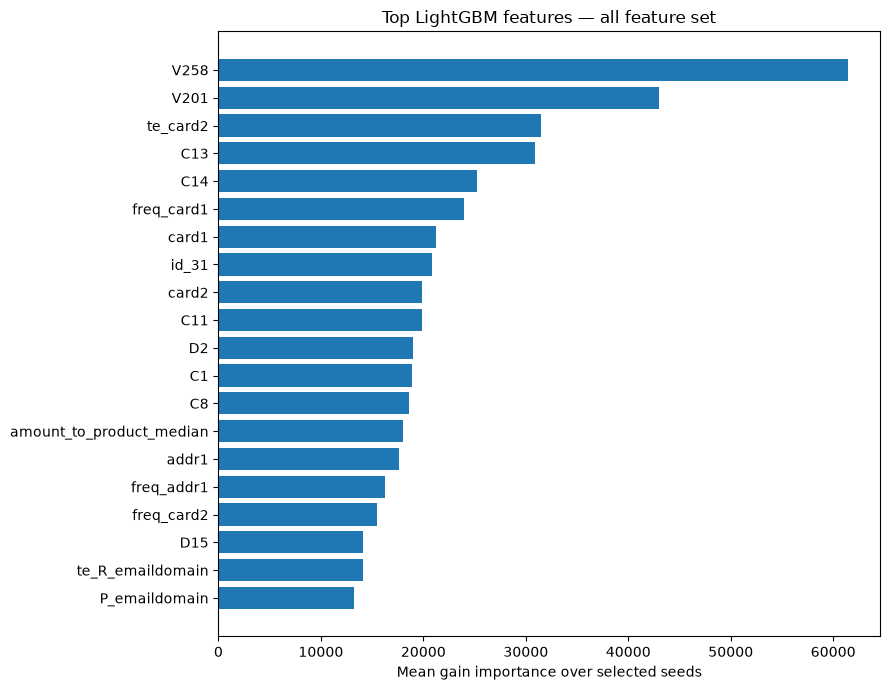

In [8]:
# [Jennifer]
available = lgbm_importances[lgbm_importances.feature_set == "all"]
if available.empty:
    print("No 'all' model in this run. Add 'all' to LIGHTGBM_SETS_TO_RUN to inspect full-model gain.")
else:
    imp = available.groupby("feature", as_index=False)[["gain", "splits"]].mean()
    imp = imp.sort_values("gain", ascending=False)
    display(imp.head(25).round(2))
    top = imp.head(20).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.barh(top.feature, top.gain)
    ax.set_xlabel("Mean gain importance over selected seeds")
    ax.set_title("Top LightGBM features — all feature set")
    fig.tight_layout()
    plt.show()

### 4e. Analyze the segment the history features were designed for

**Work by: Jennifer**

**Context from EDA/feature engineering:** missing billing address (`addr1`) occurs in a smaller segment with a disproportionate share of fraud. Key 2 was specifically engineered to provide history there when Key 1 cannot.

**Hypothesis:** a model can improve materially on the address-missing segment even if full-validation PR-AUC barely changes.

We reuse existing validation predictions and calculate metrics separately for transactions with and without `addr1`. **This is diagnostic, not a new training step.** A segment's AP must be interpreted against *that segment's* fraud prevalence; comparing AP across segments without accounting for base rates is misleading.

**Decision:** keep Key 2 history only if it provides reliable and useful improvement under operational constraints. Account keys are approximate and may merge unrelated customers.

In [9]:
# [Jennifer]
segment_missing = X_val["addr1"].isna().to_numpy() if "addr1" in X_val else None
if segment_missing is None:
    print("Cannot evaluate address segment: addr1 missing from saved tree table.")
else:
    rows = []
    for (name, seed), df in lgbm_predictions.groupby(["feature_set", "seed"], sort=False):
        # Prediction frames are written in original validation row order.
        for segment_name, mask in [("addr1_missing", segment_missing),
                                   ("addr1_present", ~segment_missing)]:
            labels = df.y.to_numpy()[mask]
            if len(np.unique(labels)) < 2:
                print(f"Skipping {name}, {segment_name}: segment has only one label.")
                continue
            metrics = evaluate(labels, df.score.to_numpy()[mask], amount_val[mask])
            rows.append({"feature_set": name, "seed": seed, "segment": segment_name,
                         "rows": int(mask.sum()), "fraud_cases": int(labels.sum()), **metrics})
    segment_results = pd.DataFrame(rows)
    segment_results.to_csv(OUTPUT_DIR / "lightgbm_segment_results.csv", index=False)
    display(segment_results[["feature_set", "seed", "segment", "rows", "fraud_cases",
                             "pr_auc", "recall_at_1pct_fpr", "tfpr_at_50pct_detection"]].round(4))

,feature_set,seed,segment,rows,fraud_cases,pr_auc,recall_at_1pct_fpr,tfpr_at_50pct_detection
0,raw,0,addr1_missing,5486,664,0.7992,0.5723,0.0904
1,raw,0,addr1_present,53568,1187,0.5199,0.4743,1.0673
2,all,0,addr1_missing,5486,664,0.8061,0.5753,0.0934
3,all,0,addr1_present,53568,1187,0.5291,0.4903,1.0067
4,all_minus_target_encoding,0,addr1_missing,5486,664,0.8161,0.5934,0.0813
5,all_minus_target_encoding,0,addr1_present,53568,1187,0.5324,0.4819,1.0892
6,all_minus_behavior,0,addr1_missing,5486,664,0.8018,0.5708,0.0873
7,all_minus_behavior,0,addr1_present,53568,1187,0.5495,0.5072,0.7828


---
# Section 5 + B2 — Track B: Logistic regression

Two logistic-regression baselines, built independently:

- **Section 5 — Jennifer:** logistic regression on the team's numeric `X_nn_*` table (`C=0.1`, `class_weight="balanced"`).
- **Section B2 — Jean:** her own sparse preprocessing layer on the team's tree table, an L2 `C` grid across three feature sets, and a frozen 2% review threshold.

Both use the same training and validation rows, so the two linear baselines can be compared directly.

---
# 5. Track B — Logistic regression: an equally important baseline

**Work by: Jennifer**

**This section is independent of LightGBM. Running its cells does not retrain Track A.**

### 5a. Why do we need a linear baseline?

A common mistake is to train only a sophisticated model and assume it is better. Logistic regression is a valuable **control**: if it performs nearly as well, the extra complexity of boosted trees may not be justified. If it performs much worse, that suggests the data may benefit from nonlinear rules or interactions, though **preprocessing differences also matter**.

Logistic regression forms a linear score:

\[z = b + w_1 x_1 + w_2 x_2 + \cdots + w_p x_p\]

It converts that score into a value between 0 and 1 via the sigmoid:

\[P(\mathrm{fraud}\mid x) = \frac{1}{1+e^{-z}}\]

**Worked example:** if `z = 0`, predicted probability is `0.50`. If `z = 2`, it is about `0.88`. If `z = -2`, it is about `0.12`. A positive coefficient increases the log-odds *holding other input features fixed*; this does **not** establish a causal relationship.

### 5b. Why the `nn` feature table?

Logistic regression expects a fully numeric matrix. Large differences in feature scales can make regularized optimization harder. The team's `X_nn_*` inputs are already encoded, imputed and standardized for numeric models. **Using them does not mean we train a neural network.**

### 5c. Why class weighting and regularization?

- **`class_weight='balanced'`:** assigns more weight to the rare fraudulent class when fitting; it helps prevent the optimizer from simply prioritizing the majority class. It does *not* guarantee better AP, and raw predicted probabilities may need calibration.
- **`C=0.1`:** inverse regularization strength; smaller `C` penalizes large coefficients more and may reduce overfitting.
- **`max_iter=1500`:** gives the solver more steps to converge than the previous 300. A `ConvergenceWarning` means the fit may be unfinished. Never conceal it or automatically treat its metrics as final.

**Hypothesis:** a linear model provides a reasonable fraud-ranking baseline but may underperform boosted trees, which discover conditional splits automatically.

In [10]:
# [Jennifer]
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning

# Load and validate the numeric features for THIS model only.
if not manifest.get("nn_track"):
    raise ValueError("Manifest does not provide the numeric nn_track outputs")
Xn_train, yn_train = load_features("train", "nn")
Xn_val, yn_val = load_features("validation", "nn")
assert yn_train.index.equals(y_train.index) and yn_val.index.equals(y_val.index)
assert Xn_train.columns.equals(Xn_val.columns)
assert np.isfinite(Xn_train.to_numpy(dtype=float)).all()
assert np.isfinite(Xn_val.to_numpy(dtype=float)).all()
print("Logistic regression inputs:", Xn_train.shape, Xn_val.shape)

# Fitting happens only when this cell is executed.
t0 = time.perf_counter()
logreg = LogisticRegression(C=0.1, max_iter=1500, class_weight="balanced", solver="lbfgs")
with warnings.catch_warnings(record=True) as logreg_warnings:
    warnings.simplefilter("always", ConvergenceWarning)
    logreg.fit(Xn_train, yn_train)
for warning in logreg_warnings:
    print("Convergence notice:", warning.message)
logreg_scores = logreg.predict_proba(Xn_val)[:, 1]
logreg_metrics = evaluate(y_val, logreg_scores, amount_val)
logreg_metrics.update(model="logistic_regression", feature_set="nn_table", seed=0,
                      n_features=Xn_train.shape[1], elapsed_seconds=time.perf_counter()-t0)
display(pd.DataFrame([logreg_metrics]).round(4))
pd.DataFrame([logreg_metrics]).to_csv(OUTPUT_DIR / "logreg_results.csv", index=False)
ks_table(y_val, logreg_scores).round(6).to_csv(OUTPUT_DIR / "ks_logreg.csv")
print("Only logistic regression was trained in this cell.")

Logistic regression inputs: (472432, 515) (59054, 515)


,fraud_rate,pr_auc,roc_auc,ks,recall_at_0.1pct_fpr,recall_at_0.5pct_fpr,recall_at_1pct_fpr,tfpr_at_50pct_detection,achieved_recall_at_50pct_detection,review_rate_at_50pct_detection,...,fraud_dollars_top5pct,fraud_cases_top10pct,fraud_dollars_top10pct,fraud_cases_top20pct,fraud_dollars_top20pct,model,feature_set,seed,n_features,elapsed_seconds
0,0.0313,0.4276,0.8667,0.5684,0.1729,0.3042,0.376,1.9806,0.5003,0.0467,...,0.4654,0.6143,0.5992,0.7488,0.7586,logistic_regression,nn_table,0,515,10.5361


Only logistic regression was trained in this cell.


### 5d. Interpret logistic regression thoughtfully

**Work by: Jennifer**

**Check 1 — Convergence:** did the fit warn that it reached the iteration limit? If so, investigate scaling and increase `max_iter` or adjust regularization before drawing strong conclusions.

**Check 2 — AP:** compare `pr_auc` to the fraud prevalence and to LightGBM's AP; remember that LightGBM and logistic regression use **different team-prepared feature tables**, which complicates attribution of the performance difference solely to algorithm family.

**Check 3 — Operating point:** a model with good ROC-AUC can still create an unacceptable number of review alerts. Use TFPR and recall at fixed FPR alongside AP.

**Check 4 — Coefficients:** a large coefficient is not always a stronger real-world risk signal, especially when features correlate. The coefficients refer to the *scaled* input representation.

**Question for your team:** Is a simpler model preferable if it detects almost as many fraud cases with fewer false alarms and clearer explanations? What if it performs significantly worse at the chosen review rate?

,feature,coefficient,absolute_coefficient
16,C14,-1.641,1.641
3,C1,1.305,1.305
383,na_D13,0.956,0.956
349,na_block_06,0.930,0.930
395,ProductCD_R,-0.809,0.809
463,id_23_IP_PROXY:HIDDEN,-0.784,0.784
133,V150,-0.778,0.778
514,na_cluster_2,0.736,0.736
453,id_15_Found,-0.726,0.726
275,identity_missing_count,-0.632,0.632


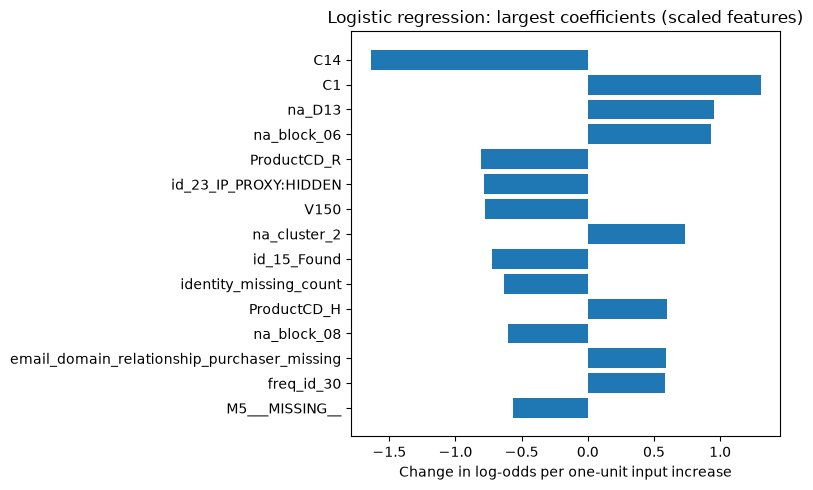

In [11]:
# [Jennifer]
# Optional interpretation: inspect the largest absolute linear coefficients.
logreg_coefficients = pd.DataFrame({"feature": Xn_train.columns, "coefficient": logreg.coef_[0]})
logreg_coefficients["absolute_coefficient"] = logreg_coefficients["coefficient"].abs()
display(logreg_coefficients.sort_values("absolute_coefficient", ascending=False).head(20).round(3))

fig, ax = plt.subplots(figsize=(8, 5))
coeff_top = logreg_coefficients.nlargest(15, "absolute_coefficient").iloc[::-1]
ax.barh(coeff_top.feature, coeff_top.coefficient)
ax.set_title("Logistic regression: largest coefficients (scaled features)")
ax.set_xlabel("Change in log-odds per one-unit input increase")
plt.tight_layout()
plt.show()

---
## B2. Track B, continued — Jean's regularized logistic regression

**Work by: Jean** (from `Jean_Draft_Logistic_Regression.ipynb`, her Sections 13–17)

Jennifer's Track B (Section 5) fits one logistic regression on the team's numeric `X_nn_*` table. Jean built a **second, independent logistic-regression pipeline**: her own training-fitted preprocessing layer (arcsinh compression, clipping, missing indicators, one-hot encoding with pooled rare categories, a correlation filter for the `V` columns), then a small grid of regularization strengths `C` across three feature sets, chosen on validation PR-AUC with a fixed review threshold.

**What changed in the merge:** Jean's draft also contained her own feature-engineering steps (her Sections 1–12). Only her logistic-regression work is kept here. The adapter cell below (B2.0) gives her code the **same train/validation rows as Tracks A and C** (the team's `X_tree_*` table), so her results line up with everyone else's. Variable names that would overwrite Jennifer's (for example `evaluate`, `REVIEW_RATES`, `feature_sets`, `y_train`) are prefixed with `jean_`. The modeling logic is unchanged.

| Jean's original feature set | Team feature set used here |
|---|---|
| `raw_baseline` | `raw` |
| `engineered_without_history` | `all_minus_behavior` (no `beh_`/`vel_` history columns) |
| `engineered_with_history` | `all` |

### B2.0 Adapter: give Jean's pipeline the team tables

**Added in the merge (not part of Jean's draft).** Jean's code expects categoricals with explicit missing and unseen labels, numerics as `float32`, and a category vocabulary learned from training only. This mirrors her Section 9 rules, applied to the team's tree table. Nothing here looks at validation labels, and the vocabulary comes from training rows only.

In [12]:
# [Merged notebook] Adapter: feed Jean's logistic-regression layer the team's tree table (same rows as Tracks A-C).
import gc
import re

MISSING_CATEGORY = "__MISSING__"
UNKNOWN_CATEGORY = "__UNSEEN__"
SAVE_ARTIFACTS = True

# Jean's three comparison sets, mapped onto the team's named feature sets (see table above)
JEAN_SET_MAP = {"raw": "raw_baseline",
                "all_minus_behavior": "engineered_without_history",
                "all": "engineered_with_history"}
jean_feature_sets = {team_name: list(feature_sets[team_name]) for team_name in JEAN_SET_MAP}
jean_columns = list(dict.fromkeys(c for cols in jean_feature_sets.values() for c in cols))

manifest_categoricals = set(manifest.get("categorical_columns", []))
categorical_columns = [c for c in jean_columns
                       if c in manifest_categoricals or not pd.api.types.is_numeric_dtype(X_train[c])]
numeric_columns = [c for c in jean_columns if c not in set(categorical_columns)]
v_columns = [c for c in numeric_columns if re.fullmatch(r"V\d+", c)]


def _jean_text_and_float(frame):
    cats = pd.DataFrame({c: frame[c].astype("object").where(frame[c].notna(), MISSING_CATEGORY).astype(str)
                         for c in categorical_columns}, index=frame.index)
    nums = frame[numeric_columns].astype("float32").replace([np.inf, -np.inf], np.nan)
    return pd.concat([cats, nums], axis=1)[categorical_columns + numeric_columns]


# Category vocabularies are learned from TRAINING rows only (Jean's Section 9 rule).
_jean_train = _jean_text_and_float(X_train)
category_vocabularies = {
    c: [MISSING_CATEGORY, UNKNOWN_CATEGORY]
       + sorted(set(_jean_train[c]) - {MISSING_CATEGORY, UNKNOWN_CATEGORY})
    for c in categorical_columns
}


def jean_prepare_split(frame):
    # Apply the frozen training vocabulary: values never seen in training become __UNSEEN__.
    out = _jean_text_and_float(frame)
    for c in categorical_columns:
        out[c] = out[c].where(out[c].isin(category_vocabularies[c]), UNKNOWN_CATEGORY)
    return out


jean_features = {"train": jean_prepare_split(X_train), "validation": jean_prepare_split(X_val)}
jean_labels = {"train": y_train, "validation": y_val}
del _jean_train
gc.collect()

for name, frame in jean_features.items():
    assert frame.index.equals(jean_labels[name].index), f"{name}: rows and labels misaligned"
print(f"Jean's inputs: {len(categorical_columns)} categorical, {len(numeric_columns)} numeric "
      f"({len(v_columns)} V columns)")
print({name: frame.shape for name, frame in jean_features.items()})
print("Feature sets:", {k: f"{len(v)} columns (Jean: {JEAN_SET_MAP[k]})" for k, v in jean_feature_sets.items()})

Jean's inputs: 34 categorical, 503 numeric (339 V columns)
{'train': (472432, 537), 'validation': (59054, 537)}
Feature sets: {'raw': '430 columns (Jean: raw_baseline)', 'all_minus_behavior': '505 columns (Jean: engineered_without_history)', 'all': '537 columns (Jean: engineered_with_history)'}


### B2.1 Add a logistic-regression layer (fitted on training only)

**Work by: Jean**

The team's tree table is built for tree models: it keeps `NaN`, uses categories, and leaves skewed numbers and redundant `V` columns alone. Logistic regression cannot take that input directly. This section fits one scikit-learn `ColumnTransformer` on the **training** table and applies it unchanged to validation. The tree table itself is not modified.

| Problem for a linear model | What we do (all learned from training only) |
|---|---|
| `NaN` values | Median imputation, plus a missing indicator for numeric columns with meaningful missingness. Indicators with identical missing patterns (the `V` blocks) are kept once. |
| Heavy-tailed numbers (`C*`, `D*`, amounts, counts, ratios, gaps) | `arcsinh` compression for columns whose training skewness is large, which behaves like a signed log and keeps zeros and negatives. Then standardize and clip at ±10 standard deviations so a later outlier cannot dominate. |
| Categories are codes, not magnitudes | One-hot encoding. Columns with up to 50 training categories are encoded in full. Larger ones pool categories seen in fewer than 200 training rows into one bucket. |
| New or pooled categories later | `__UNSEEN__` and rare values fall into the pooled bucket when there is one, or into all-zeros otherwise, so they never get a coefficient they were not trained for. |
| Hundreds of correlated `V` columns | A greedy correlation filter (\|r\| > 0.95) keeps the first column of each redundant group. Constant `V` columns are dropped. |

A linear model cannot learn interactions such as product × missing identity × amount on its own, so treat it as a transparent baseline rather than a like-for-like competitor to the tree models. Nothing here claims improved performance. The matrix is **sparse**: the full run needs several extra GB of RAM and scikit-learn 1.2 or newer.

In [13]:
# [Jean] Section 13 — training-fitted preprocessing layer for logistic regression
import hashlib

import joblib
import sklearn
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

assert tuple(int(p) for p in sklearn.__version__.split(".")[:2]) >= (1, 2), (
    "This section needs scikit-learn 1.2+ (OneHotEncoder sparse_output and infrequent categories)."
)

LOW_CARDINALITY_MAX = 50            # categories (incl. __MISSING__/__UNSEEN__) encoded in full up to this size
MIN_CATEGORY_COUNT = 200            # larger vocabularies pool categories seen in fewer training rows than this
SKEW_THRESHOLD = 2.0                # |training skewness| above this gets arcsinh compression
V_CORRELATION_THRESHOLD = 0.95      # training-only redundancy filter for the anonymous V columns
INDICATOR_MISSING_RANGE = (0.005, 0.995)  # training missing share that earns a missing indicator
CLIP_SD = 10.0                      # standardized values are clipped to +/- this many training SDs
LR_DIR = OUTPUT_DIR / "jean_logistic_regression"   # [Merged notebook] saved next to Jennifer's baseline outputs

train_X = jean_features["train"]

def redundant_columns(frame, columns, threshold):
    # Training-only greedy filter: keep the first column of each highly correlated group.
    data = frame[columns].astype("float32")
    data = data.fillna(data.median())
    spread = data.std(ddof=0)
    constant = [c for c in columns if not spread[c] > 0]
    usable = [c for c in columns if c not in constant]
    z = ((data[usable] - data[usable].mean()) / spread[usable]).to_numpy("float32")
    correlation = np.abs(z.T @ z) / len(z)
    kept_positions, dropped = [], []
    for position, column in enumerate(usable):
        if kept_positions and correlation[position, kept_positions].max() > threshold:
            dropped.append(column)
        else:
            kept_positions.append(position)
    return constant, dropped

# 1. Redundant anonymous columns (decided on training rows only).
v_numeric = [c for c in v_columns if c in numeric_columns]
constant_v_columns, redundant_v_columns = redundant_columns(train_X, v_numeric, V_CORRELATION_THRESHOLD)
lr_numeric = [c for c in numeric_columns if c not in set(constant_v_columns) | set(redundant_v_columns)]

# 2. Which numeric columns are binary, skewed, or plain (training statistics only).
distinct_values = train_X[lr_numeric].nunique(dropna=True)
binary_columns = distinct_values[distinct_values <= 2].index.tolist()
continuous_columns = [c for c in lr_numeric if c not in binary_columns]
skewness = train_X[continuous_columns].skew()
skewed_columns = skewness[skewness.abs() > SKEW_THRESHOLD].index.tolist()
plain_columns = [c for c in lr_numeric if c not in set(skewed_columns)]

# 3. Missing indicators, one per distinct training missing pattern.
missing_share = train_X[lr_numeric].isna().mean()
low, high = INDICATOR_MISSING_RANGE
indicator_candidates = [
    c for c in lr_numeric
    if low <= missing_share[c] <= high and f"{c}_missing" not in lr_numeric  # skip columns that already have a flag
]
indicator_columns, seen_patterns = [], set()
for column in indicator_candidates:
    pattern = hashlib.md5(train_X[column].isna().to_numpy().tobytes()).hexdigest()
    if pattern not in seen_patterns:
        seen_patterns.add(pattern)
        indicator_columns.append(column)

# 4. Categorical columns: full one-hot for small vocabularies, pooled rare categories for large ones.
categorical_low = [c for c in categorical_columns if len(category_vocabularies[c]) <= LOW_CARDINALITY_MAX]
categorical_high = [c for c in categorical_columns if c not in set(categorical_low)]
lr_input_columns = categorical_columns + lr_numeric

def numeric_branch(compress):
    steps = []
    if compress:
        steps.append(("compress", FunctionTransformer(np.arcsinh, feature_names_out="one-to-one")))
    steps += [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("clip", FunctionTransformer(
            np.clip, kw_args={"a_min": -CLIP_SD, "a_max": CLIP_SD}, feature_names_out="one-to-one",
        )),
    ]
    return Pipeline(steps)

lr_preprocessor = ColumnTransformer(
    [
        ("skewed_numeric", numeric_branch(compress=True), skewed_columns),
        ("plain_numeric", numeric_branch(compress=False), plain_columns),
        ("missing_indicator", MissingIndicator(features="all"), indicator_columns),
        ("low_cardinality", OneHotEncoder(
            handle_unknown="ignore", sparse_output=True, dtype=np.float32), categorical_low),
        ("high_cardinality", OneHotEncoder(
            handle_unknown="infrequent_if_exist", min_frequency=MIN_CATEGORY_COUNT,
            sparse_output=True, dtype=np.float32), categorical_high),
    ],
    remainder="drop", sparse_threshold=1.0, verbose_feature_names_out=False,
)

def lr_frame(frame):
    # OneHotEncoder expects plain strings; the categories keep their training vocabulary.
    return frame[lr_input_columns].astype({c: "object" for c in categorical_columns})

lr_preprocessor.fit(lr_frame(train_X))          # the only fit: training period
lr_matrices = {
    name: sparse.csr_matrix(lr_preprocessor.transform(lr_frame(frame)), dtype=np.float32)
    for name, frame in jean_features.items()
}
lr_feature_names = lr_preprocessor.get_feature_names_out().tolist()

# Trace every output column back to its source column so feature families can be compared later.
lr_feature_source, lr_feature_kind, block_rows, block_names_in_order = [], [], [], []
for block_name, transformer, columns in lr_preprocessor.transformers_:
    if block_name == "remainder" or len(columns) == 0:
        continue
    names = transformer.get_feature_names_out(columns).tolist()
    if block_name.endswith("numeric"):
        sources, kind = names, "numeric"
    elif block_name == "missing_indicator":
        sources, kind = [n[len("missingindicator_"):] for n in names], "indicator"
    else:
        by_length = sorted(columns, key=len, reverse=True)
        sources = [next(c for c in by_length if n.startswith(c + "_")) for n in names]
        kind = "onehot"
    block_names_in_order += names
    lr_feature_source += sources
    lr_feature_kind += [kind] * len(names)
    block_rows.append({"block": block_name, "input_columns": len(columns), "output_columns": len(names)})
assert block_names_in_order == lr_feature_names, "Feature-name tracing is out of order."

lr_feature_set_columns = {
    set_name: [
        i for i, (source, kind) in enumerate(zip(lr_feature_source, lr_feature_kind))
        if source in set(columns) and not (set_name == "raw" and kind == "indicator")
    ]
    for set_name, columns in jean_feature_sets.items()
}

display(pd.DataFrame(block_rows).set_index("block"))
print(f"V columns dropped: {len(redundant_v_columns)} redundant, {len(constant_v_columns)} constant (of {len(v_numeric)})")
print(f"Numeric: {len(skewed_columns)} compressed, {len(plain_columns)} plain, {len(binary_columns)} of them binary")
print(f"Missing indicators kept: {len(indicator_columns)} of {len(indicator_candidates)} candidates")
print("Matrix shapes:", {name: m.shape for name, m in lr_matrices.items()})
print("Columns per feature set:", {k: len(v) for k, v in lr_feature_set_columns.items()})

,input_columns,output_columns
block,,
skewed_numeric,332,332
plain_numeric,113,113
missing_indicator,60,60
low_cardinality,29,156
high_cardinality,5,169


V columns dropped: 58 redundant, 0 constant (of 339)
Numeric: 332 compressed, 113 plain, 41 of them binary
Missing indicators kept: 60 of 282 candidates
Matrix shapes: {'train': (472432, 830), 'validation': (59054, 830)}
Columns per feature set: {'raw': 597, 'all_minus_behavior': 786, 'all': 830}


### B2.2 Check and save the logistic-regression matrix

**Work by: Jean.** We confirm that every split has the same width, that nothing is missing, infinite, or beyond the clip range, that statistics came from training rows only, and that a never-seen category cannot produce an out-of-range value. Then we save the sparse matrices, row IDs, fitted preprocessor, a feature map, and a manifest, and check that they reload correctly.

A matrix that fits in memory can still be misaligned or accidentally fitted on future rows. These checks cover the two ways this layer could quietly break the experiment.

The saved `.npz` files follow the row order of the team's `X_tree_<split>.parquet`, and `lr_feature_map.csv` records the source column and kind of every output column. The preprocessor is pickled with joblib, so load it with the same scikit-learn version recorded in the manifest.

In [14]:
# [Jean] Section 14 — checks and saved artifacts for the logistic-regression matrix
expected_width = len(lr_feature_names)
for name, matrix in lr_matrices.items():
    assert matrix.shape == (len(jean_features[name]), expected_width)
    assert matrix.dtype == np.float32
    assert np.isfinite(matrix.data).all(), f"{name}: NaN or infinity in the matrix."
    assert np.abs(matrix.data).max() <= CLIP_SD + 1e-4, f"{name}: values beyond the clip range."
    if name in jean_labels:
        assert jean_features[name].index.equals(jean_labels[name].index)

# Fitted on the training rows only: the imputer medians and the scaler's sample count match training.
if plain_columns:
    plain_branch = lr_preprocessor.named_transformers_["plain_numeric"]
    np.testing.assert_allclose(
        plain_branch.named_steps["impute"].statistics_,
        train_X[plain_columns].median().to_numpy(dtype="float64"), rtol=1e-5, equal_nan=True,
    )
    assert int(np.max(plain_branch.named_steps["scale"].n_samples_seen_)) == len(train_X)

# A category never seen in training must activate at most one pooled/bucket column per source.
probe_frame = lr_frame(train_X.iloc[:5])
for column in categorical_columns:
    probe_frame[column] = UNKNOWN_CATEGORY
probe_matrix = sparse.csr_matrix(lr_preprocessor.transform(probe_frame))
assert np.isfinite(probe_matrix.data).all()
for column in categorical_columns:
    positions = [i for i, (s, k) in enumerate(zip(lr_feature_source, lr_feature_kind))
                 if s == column and k == "onehot"]
    if positions:
        assert probe_matrix[:, positions].sum(axis=1).max() <= 1

lr_manifest = {
    "purpose": "Training-fitted preprocessing for logistic regression on the team tree table; tree tables are unchanged.",
    "settings": {
        "low_cardinality_max": LOW_CARDINALITY_MAX, "min_category_count": MIN_CATEGORY_COUNT,
        "skew_threshold": SKEW_THRESHOLD, "v_correlation_threshold": V_CORRELATION_THRESHOLD,
        "indicator_missing_range": list(INDICATOR_MISSING_RANGE), "clip_sd": CLIP_SD,
    },
    "fit_rows": int(len(train_X)),
    "output_width": expected_width,
    "dropped_constant_v_columns": constant_v_columns,
    "dropped_redundant_v_columns": redundant_v_columns,
    "skewed_columns_arcsinh": skewed_columns,
    "plain_columns": plain_columns,
    "binary_columns": binary_columns,
    "missing_indicator_columns": indicator_columns,
    "categorical_low_cardinality": categorical_low,
    "categorical_high_cardinality": categorical_high,
    "feature_set_output_columns": lr_feature_set_columns,
    "feature_set_names_in_jean_draft": JEAN_SET_MAP,
    "versions": {"scikit_learn": sklearn.__version__, "scipy": __import__("scipy").__version__,
                 "joblib": joblib.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}

if SAVE_ARTIFACTS:
    LR_DIR.mkdir(parents=True, exist_ok=True)
    for name, matrix in lr_matrices.items():
        sparse.save_npz(LR_DIR / f"X_lr_{name}.npz", matrix, compressed=False)
        np.save(LR_DIR / f"row_index_{name}.npy", jean_features[name].index.to_numpy())
    joblib.dump(lr_preprocessor, LR_DIR / "lr_preprocessor.joblib")
    pd.DataFrame({
        "feature": lr_feature_names, "source_column": lr_feature_source, "kind": lr_feature_kind,
    }).to_csv(LR_DIR / "lr_feature_map.csv", index=False)
    (LR_DIR / "lr_manifest.json").write_text(json.dumps(lr_manifest, indent=2, allow_nan=False) + "\n")

    # Verify a real round trip: the saved matrix and the reloaded preprocessor reproduce the same values.
    restored = sparse.load_npz(LR_DIR / "X_lr_validation.npz")
    assert (restored != lr_matrices["validation"]).nnz == 0
    reloaded = joblib.load(LR_DIR / "lr_preprocessor.joblib")
    sample = lr_frame(jean_features["validation"].iloc[:1_000])
    again = sparse.csr_matrix(reloaded.transform(sample), dtype=np.float32)
    assert (again != lr_matrices["validation"][:1_000]).nnz == 0
    print("Saved the logistic-regression matrices and verified the round trip:", LR_DIR)
else:
    print("Artifacts not written. Set SAVE_ARTIFACTS=True for the logistic-regression handoff.")
print(f"Checks passed: {expected_width} aligned linear-model columns across {len(lr_matrices)} splits.")

Saved the logistic-regression matrices and verified the round trip: outputs/feature_engineering/fe_final_v1/baselines/student_explained_v2/jean_logistic_regression
Checks passed: 830 aligned linear-model columns across 2 splits.


### B2.3 Train logistic regression and compare feature sets on validation

**Work by: Jean.** We fit an L2-regularized logistic regression on the training matrix for each feature set (`raw`, `all_minus_behavior`, `all`) and for each value in a small grid of regularization strengths `C`. Every model is scored on the validation period only.

Fraud is rare, so accuracy and ROC-AUC can look strong while many frauds are missed. The main measure is **PR-AUC** (average precision); a random scorer's PR-AUC equals the fraud share, which we print for reference. We also report recall and precision when only the highest-scoring 0.5%, 1%, 2%, or 5% of payments are reviewed, because the goal is to catch fraud at a manageable review volume. Those review budgets use only the *ranking* of scores, so we do not reweight classes; that also keeps the predicted probabilities calibrated (unlike Jennifer's Track B, which uses `class_weight="balanced"`). L-BFGS handles the sparse matrix efficiently, and a fit that stops at the iteration limit is flagged rather than silently trusted.

The model sees training labels only. One chronological split and a small grid mean that small differences between rows are not strong evidence. The full run fits nine models on roughly 470,000 rows and can take tens of minutes; shorten `JEAN_FEATURE_SETS_TO_FIT` or `JEAN_C_GRID` for a quick pass.

*Merge note:* Jean's metric helpers are named `jean_evaluate` / `jean_review_metrics` so they don't replace the team's `evaluate()` from Section 3.

In [15]:
# [Jean] Section 15 — L2 logistic regression over feature sets x C grid (validation only)
import time
import warnings

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

JEAN_C_GRID = (0.01, 0.1, 1.0)                 # inverse L2 strength: smaller values regularize more
JEAN_MAX_ITER = 500
JEAN_CLASS_WEIGHT = None                       # review budgets rank scores, so no reweighting is needed
JEAN_REVIEW_RATES = (0.005, 0.01, 0.02, 0.05)  # shares of payments an analyst team could review
JEAN_FEATURE_SETS_TO_FIT = list(jean_feature_sets)  # e.g. ["all"] for a quicker run

jean_y_train = jean_labels["train"].to_numpy()
y_validation = jean_labels["validation"].to_numpy()
assert lr_matrices["train"].shape[0] == len(jean_y_train)
assert lr_matrices["validation"].shape[0] == len(y_validation)
assert jean_y_train.sum() > 0 and y_validation.sum() > 0

def take_columns(matrix, columns):
    return matrix if len(columns) == matrix.shape[1] else matrix[:, columns]

def jean_review_metrics(y_true, scores, rates=JEAN_REVIEW_RATES):
    # Recall and precision when only the highest-scoring share of payments is reviewed.
    order = np.argsort(-scores, kind="stable")
    caught = np.cumsum(np.asarray(y_true)[order])
    metrics = {}
    for rate in rates:
        reviewed = max(1, int(round(rate * len(scores))))
        metrics[f"recall@{rate:.1%}"] = caught[reviewed - 1] / caught[-1]
        metrics[f"precision@{rate:.1%}"] = caught[reviewed - 1] / reviewed
    return metrics

def jean_evaluate(y_true, scores):
    return {
        "pr_auc": average_precision_score(y_true, scores),
        "roc_auc": roc_auc_score(y_true, scores),
        **jean_review_metrics(y_true, scores),
    }

fitted_models, validation_scores, jean_rows = {}, {}, []
for set_name in JEAN_FEATURE_SETS_TO_FIT:
    columns = lr_feature_set_columns[set_name]
    X_fit = take_columns(lr_matrices["train"], columns)
    X_check = take_columns(lr_matrices["validation"], columns)
    for C in JEAN_C_GRID:
        jean_model = LogisticRegression(C=C, solver="lbfgs", max_iter=JEAN_MAX_ITER, class_weight=JEAN_CLASS_WEIGHT)
        started = time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            jean_model.fit(X_fit, jean_y_train)
        seconds = time.perf_counter() - started
        s = jean_model.predict_proba(X_check)[:, 1]
        converged = not any(issubclass(w.category, ConvergenceWarning) for w in caught)
        jean_rows.append({
            "feature_set": set_name, "C": C, "n_features": len(columns),
            "n_iter": int(jean_model.n_iter_[0]), "converged": converged, "seconds": round(seconds, 1),
            **jean_evaluate(y_validation, s),
        })
        fitted_models[(set_name, C)] = jean_model
        validation_scores[(set_name, C)] = s.astype("float32")
        print(f"{set_name:<20} ({JEAN_SET_MAP[set_name]:<27}) C={C:<5} PR-AUC {jean_rows[-1]['pr_auc']:.4f}  "
              f"({seconds:.0f}s, {'converged' if converged else 'NOT converged'})")
    del X_fit, X_check
    gc.collect()

validation_results = pd.DataFrame(jean_rows)
print(f"\nValidation fraud share (PR-AUC of random scoring): {y_validation.mean():.2%}")
display(validation_results.set_index(["feature_set", "C"]).round(4))
if not validation_results["converged"].all():
    print("Some fits reached JEAN_MAX_ITER. Raise it or lower C before trusting those rows.")

raw                  (raw_baseline               ) C=0.01  PR-AUC 0.4149  (21s, converged)
raw                  (raw_baseline               ) C=0.1   PR-AUC 0.4066  (30s, converged)
raw                  (raw_baseline               ) C=1.0   PR-AUC 0.4081  (42s, converged)
all_minus_behavior   (engineered_without_history ) C=0.01  PR-AUC 0.4259  (29s, converged)
all_minus_behavior   (engineered_without_history ) C=0.1   PR-AUC 0.4187  (50s, converged)
all_minus_behavior   (engineered_without_history ) C=1.0   PR-AUC 0.4158  (73s, converged)
all                  (engineered_with_history    ) C=0.01  PR-AUC 0.4276  (36s, converged)
all                  (engineered_with_history    ) C=0.1   PR-AUC 0.4212  (52s, converged)
all                  (engineered_with_history    ) C=1.0   PR-AUC 0.4185  (75s, converged)

Validation fraud share (PR-AUC of random scoring): 3.13%


n_features  n_iter  converged  seconds  pr_auc  \
feature_set        C                                                      
raw                0.01         597     113       True     21.3  0.4149   
                   0.10         597     163       True     30.2  0.4066   
                   1.00         597     225       True     42.1  0.4081   
all_minus_behavior 0.01         786     113       True     29.3  0.4259   
                   0.10         786     199       True     49.9  0.4187   
                   1.00         786     287       True     72.6  0.4158   
all                0.01         830     129       True     35.6  0.4276   
                   0.10         830     192       True     51.8  0.4212   
                   1.00         830     268       True     74.6  0.4185   

                         roc_auc  recall@0.5%  precision@0.5%  recall@1.0%  \
feature_set        C                                                         
raw                0.01   0.8488       0.1415          0.8881       0.2469   
                   0.10   0.8481       0.1394          0.8746       0.2464   
                   1.00   0.8484       0.1394          0.8746       0.2480   
all_minus_behavior 0.01   0.8558       0.1459          0.9153       0.2480   
                   0.10   0.8554       0.1415          0.8881       0.2480   
                   1.00   0.8549       0.1394          0.8746       0.2474   
all                0.01   0.8560       0.1464          0.9186       0.2480   
                   0.10   0.8560       0.1421          0.8915       0.2491   
                   1.00   0.8556       0.1399          0.8780       0.2474   

                         precision@1.0%  recall@2.0%  precision@2.0%  \
feature_set        C                                                   
raw                0.01          0.7733       0.3528          0.5529   
                   0.10          0.7716       0.3490          0.5470   
                   1.00          0.7766       0.3522          0.5521   
all_minus_behavior 0.01          0.7766       0.3555          0.5572   
                   0.10          0.7766       0.3549          0.5563   
                   1.00          0.7750       0.3544          0.5555   
all                0.01          0.7766       0.3549          0.5563   
                   0.10          0.7800       0.3533          0.5538   
                   1.00          0.7750       0.3560          0.5580   

                         recall@5.0%  precision@5.0%  
feature_set        C                                  
raw                0.01       0.4976          0.3119  
                   0.10       0.4954          0.3105  
                   1.00       0.4992          0.3129  
all_minus_behavior 0.01       0.5116          0.3207  
                   0.10       0.5062          0.3173  
                   1.00       0.5068          0.3176  
all                0.01       0.5132          0.3217  
                   0.10       0.5100          0.3197  
                   1.00       0.5062          0.3173

### B2.4 Choose the configuration and review threshold using validation only

**Work by: Jean.** We pick the feature set and `C` with the highest validation PR-AUC among fits that converged. We then fix an alert threshold: the score at which exactly 2% of validation payments would be reviewed. Two plots show the precision-recall curve and recall versus review volume for each feature set at its best `C`, and a table lists the largest weights of the chosen model.

The threshold is set once from validation scores and then frozen. That mirrors a team that decides its alert level before seeing the future, so later shifts in fraud rate appear as a different review share instead of being hidden by re-ranking. Numeric inputs are standardized and one-hot columns are 0/1, so larger weights mean a stronger linear association with the score, not a cause of fraud. Correlated features share credit, and the table describes this model rather than explaining fraud.

*Merge note:* the last lines of the next cell also score Jean's chosen model with the team's `evaluate()` (Jennifer's Section 3). That way it appears in the side-by-side tables in Sections 6r and 7, and in the all-team scoreboard at the end.

Chosen on validation: all (engineered_with_history), C=0.01 (pr_auc = 0.4276)
Review threshold (top 2% of validation scores): 0.3509
{'review_share': 0.02, 'precision': 0.5558, 'recall': 0.3549}


,C,pr_auc,roc_auc,recall@2.0%,precision@2.0%
feature_set,,,,,
all,0.01,0.4276,0.8560,0.3549,0.5563
all_minus_behavior,0.01,0.4259,0.8558,0.3555,0.5572
raw,0.01,0.4149,0.8488,0.3528,0.5529


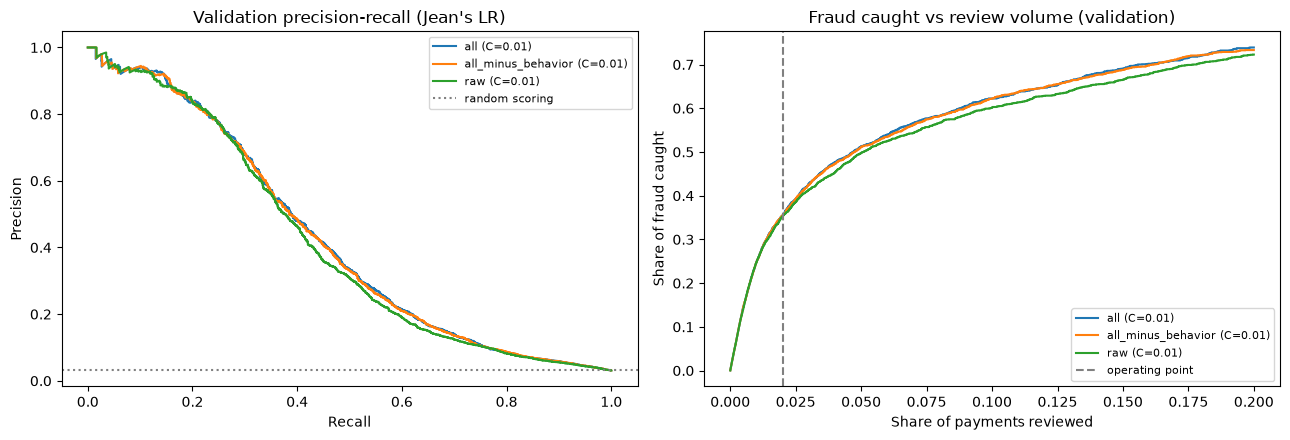

Largest weights raising the fraud score:


,feature,source_column,kind,coefficient
4,C1,C1,numeric,0.965
445,missingindicator_card2,card2,indicator,0.449
641,device_family_huawei,device_family,onehot,0.404
5,C2,C2,numeric,0.353
779,id_31_chrome generic,id_31,onehot,0.351
411,na_block_06,na_block_06,numeric,0.348
460,missingindicator_D13,D13,indicator,0.332
808,id_33_1366x768,id_33,onehot,0.302
512,card4_discover,card4,onehot,0.292
14,C11,C11,numeric,0.279


Largest weights lowering the fraud score:


,feature,source_column,kind,coefficient
17,C14,C14,numeric,-1.286
16,C13,C13,numeric,-0.522
518,card6_debit,card6,onehot,-0.410
285,freq_addr2,freq_addr2,numeric,-0.383
507,ProductCD_R,ProductCD,onehot,-0.382
535,M5___MISSING__,M5,onehot,-0.361
789,id_31_ie 11.0 for desktop,id_31,onehot,-0.345
6,C3,C3,numeric,-0.325
112,V139,V139,numeric,-0.321
123,V157,V157,numeric,-0.294


Jean's chosen model on the team's metrics:


,model,feature_set,C,pr_auc,roc_auc,recall_at_1pct_fpr,tfpr_at_50pct_detection,fraud_cases_top5pct
0,logistic_regression_jean,all,0.01,0.4276,0.856,0.3663,1.9914,0.5132


In [16]:
# [Jean] Section 16 — pick the model and a frozen 2% review threshold on validation
JEAN_SELECTION_METRIC = "pr_auc"
JEAN_OPERATING_REVIEW_RATE = 0.02     # review the top 2% of payments by score
assert JEAN_OPERATING_REVIEW_RATE in JEAN_REVIEW_RATES

jean_eligible = validation_results[validation_results["converged"]]
if jean_eligible.empty:
    jean_eligible = validation_results
best_key = list(fitted_models)[jean_eligible[JEAN_SELECTION_METRIC].idxmax()]
chosen_set, chosen_C = best_key
chosen_model = fitted_models[best_key]
chosen_scores = validation_scores[best_key]
chosen_columns = lr_feature_set_columns[chosen_set]

review_threshold = float(np.quantile(chosen_scores, 1 - JEAN_OPERATING_REVIEW_RATE))
flagged = chosen_scores >= review_threshold
validation_operating_point = {
    "review_share": float(flagged.mean()),
    "precision": float(y_validation[flagged].mean()),
    "recall": float(y_validation[flagged].sum() / y_validation.sum()),
}
print(f"Chosen on validation: {chosen_set} ({JEAN_SET_MAP[chosen_set]}), C={chosen_C} ({JEAN_SELECTION_METRIC} = "
      f"{validation_results.loc[list(fitted_models).index(best_key), JEAN_SELECTION_METRIC]:.4f})")
print(f"Review threshold (top {JEAN_OPERATING_REVIEW_RATE:.0%} of validation scores): {review_threshold:.4f}")
print({k: round(v, 4) for k, v in validation_operating_point.items()})

best_per_set = validation_results.loc[
    validation_results.groupby("feature_set")[JEAN_SELECTION_METRIC].idxmax()
].set_index("feature_set")
rate_label = f"{JEAN_OPERATING_REVIEW_RATE:.1%}"
display(best_per_set[["C", "pr_auc", "roc_auc", f"recall@{rate_label}", f"precision@{rate_label}"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for set_name, row in best_per_set.iterrows():
    s = validation_scores[(set_name, float(row["C"]))]
    precision, recall, _ = precision_recall_curve(y_validation, s)
    label = f"{set_name} (C={row['C']:g})"
    axes[0].plot(recall, precision, label=label)
    order = np.argsort(-s, kind="stable")
    caught = np.cumsum(y_validation[order]) / y_validation.sum()
    share = np.arange(1, len(s) + 1) / len(s)
    keep = share <= 0.20
    axes[1].plot(share[keep], caught[keep], label=label)
axes[0].axhline(y_validation.mean(), color="grey", linestyle=":", label="random scoring")
axes[0].set(title="Validation precision-recall (Jean's LR)", xlabel="Recall", ylabel="Precision")
axes[1].axvline(JEAN_OPERATING_REVIEW_RATE, color="grey", linestyle="--", label="operating point")
axes[1].set(title="Fraud caught vs review volume (validation)",
            xlabel="Share of payments reviewed", ylabel="Share of fraud caught")
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

jean_coefficients = pd.DataFrame({
    "feature": np.array(lr_feature_names)[chosen_columns],
    "source_column": np.array(lr_feature_source)[chosen_columns],
    "kind": np.array(lr_feature_kind)[chosen_columns],
    "coefficient": chosen_model.coef_[0],
})
print("Largest weights raising the fraud score:")
display(jean_coefficients.nlargest(12, "coefficient").round(3))
print("Largest weights lowering the fraud score:")
display(jean_coefficients.nsmallest(12, "coefficient").round(3))

# [Merged notebook] Score Jean's chosen model with the team's evaluate() so it fits in the shared tables.
jean_logreg_metrics = evaluate(y_val, chosen_scores, amount_val)
jean_logreg_metrics.update(model="logistic_regression_jean", feature_set=chosen_set, seed=0,
                           n_features=len(chosen_columns), C=chosen_C)
print("Jean's chosen model on the team's metrics:")
display(pd.DataFrame([jean_logreg_metrics])[["model", "feature_set", "C", "pr_auc", "roc_auc", "recall_at_1pct_fpr",
                                             "tfpr_at_50pct_detection", "fraud_cases_top5pct"]].round(4))
pd.DataFrame([jean_logreg_metrics]).to_csv(OUTPUT_DIR / "jean_logreg_results.csv", index=False)

### B2.5 Save Jean's model (holdout step switched off for now)

**Work by: Jean.** Jean's draft ended by scoring the final holdout **once** with her chosen model and the frozen validation threshold, and reporting PR-AUC, ROC-AUC, recall/precision at each review rate, and the review share the threshold produces on later payments.

*Merge note:* The rest of this notebook follows the team rule that the holdout stays untouched until the team freezes its final model. So the holdout step is kept but switched off (`RUN_JEAN_HOLDOUT = False`). When the team is ready, set it to `True` once. It assumes the feature-engineering notebook saved `X_tree_holdout.parquet` / `y_holdout.parquet`; adjust the split name if needed. The cell refuses to run the holdout twice in one session so it cannot become a second validation set. With the flag off, the cell still saves the model, validation scores, the validation grid, coefficients, and a report.

**Limits Jean noted:** the model was not refit on training plus validation (that would need the preprocessing layer refit too). There is no calibration study or confidence interval yet.

In [17]:
# [Jean] Section 17 — final holdout (gated) and saved model/report
RUN_JEAN_HOLDOUT = False   # [Merged notebook] team policy: leave False until the final model is frozen

def jean_score_matrix(matrix):
    return chosen_model.predict_proba(take_columns(matrix, chosen_columns))[:, 1]

holdout_scores, jean_holdout_metrics, holdout_operating_point, y_holdout = None, None, None, None
if RUN_JEAN_HOLDOUT:
    assert "jean_holdout_done" not in globals(), (
        "The holdout was already evaluated in this session. Restart and run all cells; do not tune on it."
    )
    X_hold, y_hold = load_features("holdout", "tree")
    hold_matrix = sparse.csr_matrix(lr_preprocessor.transform(lr_frame(jean_prepare_split(X_hold))), dtype=np.float32)
    y_holdout = y_hold.to_numpy()
    holdout_scores = jean_score_matrix(hold_matrix)
    assert len(holdout_scores) == len(y_holdout) and y_holdout.sum() > 0
    jean_holdout_done = True

    jean_holdout_metrics = jean_evaluate(y_holdout, holdout_scores)
    flagged_holdout = holdout_scores >= review_threshold
    holdout_operating_point = {
        "review_share": float(flagged_holdout.mean()),
        "precision": float(y_holdout[flagged_holdout].mean()) if flagged_holdout.any() else float("nan"),
        "recall": float(y_holdout[flagged_holdout].sum() / y_holdout.sum()),
    }
    print(f"Final holdout for {chosen_set}, C={chosen_C} (fraud share {y_holdout.mean():.2%}; "
          f"validation {y_validation.mean():.2%})")
    display(pd.DataFrame({"validation": jean_evaluate(y_validation, chosen_scores),
                          "holdout": jean_holdout_metrics}).T.round(4))
    print(f"Fixed validation threshold ({review_threshold:.4f}) applied to each period:")
    display(pd.DataFrame({"validation": validation_operating_point,
                          "holdout": holdout_operating_point}).T.round(4))
else:
    print("Holdout NOT scored (RUN_JEAN_HOLDOUT = False) — consistent with the rest of the notebook.")

if SAVE_ARTIFACTS:
    LR_DIR.mkdir(parents=True, exist_ok=True)
    joblib.dump(chosen_model, LR_DIR / "lr_model.joblib")
    validation_results.to_csv(LR_DIR / "lr_validation_results.csv", index=False)
    jean_coefficients.to_csv(LR_DIR / "lr_coefficients.csv", index=False)
    split_scores = {"validation": (chosen_scores, jean_features["validation"].index)}
    if holdout_scores is not None:
        split_scores["holdout"] = (holdout_scores, X_hold.index)
    for name, (values, index) in split_scores.items():
        pd.DataFrame({"fraud_score": np.asarray(values, dtype="float32")}, index=index).to_parquet(
            LR_DIR / f"scores_{name}.parquet")
    report = {
        "author": "Jean",
        "model": "LogisticRegression (L2, lbfgs) on Jean's preprocessing layer; fitted on the team training period only",
        "selected": {
            "feature_set": chosen_set, "feature_set_name_in_jean_draft": JEAN_SET_MAP[chosen_set],
            "C": chosen_C, "max_iter": JEAN_MAX_ITER, "class_weight": JEAN_CLASS_WEIGHT,
            "n_features": len(chosen_columns), "selection_metric": JEAN_SELECTION_METRIC, "selected_on": "validation",
        },
        "review_rates": list(JEAN_REVIEW_RATES),
        "operating_review_rate": JEAN_OPERATING_REVIEW_RATE,
        "review_threshold_from_validation": review_threshold,
        "validation_operating_point": validation_operating_point,
        "holdout_operating_point": holdout_operating_point,
        "validation_metrics": jean_evaluate(y_validation, chosen_scores),
        "holdout_metrics": jean_holdout_metrics,
        "holdout_evaluated": bool(RUN_JEAN_HOLDOUT),
        "fraud_share": {"train": float(jean_y_train.mean()), "validation": float(y_validation.mean()),
                        "holdout": None if y_holdout is None else float(y_holdout.mean())},
        "validation_grid": validation_results.to_dict(orient="records"),
        "versions": lr_manifest["versions"],
    }
    (LR_DIR / "lr_model_report.json").write_text(
        json.dumps(report, indent=2, allow_nan=False, default=lambda o: o.item()) + "\n"
    )
    print("Saved Jean's model, scores, coefficients, and report to", LR_DIR)
else:
    print("Artifacts not written. Set SAVE_ARTIFACTS=True to save the model and scores.")

Holdout NOT scored (RUN_JEAN_HOLDOUT = False) — consistent with the rest of the notebook.
Saved Jean's model, scores, coefficients, and report to outputs/feature_engineering/fe_final_v1/baselines/student_explained_v2/jean_logistic_regression


---
# Section 6 — Track C: XGBoost

**Work by: Jennifer**

---
# 6. Track C — XGBoost: a separate boosted-tree baseline

**Work by: Jennifer**

**Why add this track?** The project's overview suggests XGBoost as a candidate model. Although LightGBM and XGBoost both build boosted trees, they can differ in speed, splitting behavior, regularization, and implementation details. We should compare the results rather than assume they are interchangeable.

**To keep this first XGBoost run straightforward**, we use the **numeric `X_nn_*` table**, which requires no pandas categorical support. This is a deliberate modeling choice, not a perfect algorithm-only comparison against LightGBM's tree table. Later, if XGBoost becomes a serious candidate, run **both algorithms on exactly the same numeric matrix** to isolate model-family differences.

The next cell fits **only XGBoost**. If XGBoost is not installed, install it and rerun this section. Logistic regression and LightGBM are not invoked.

**Hypothesis:** XGBoost is competitive with LightGBM on fraud ranking, but the winner may differ by review operating point. Starting hyperparameters are comparable in intent, **not numerically equivalent** across implementations.

**Early stopping:** here we use validation average precision to select a boosting iteration, so validation still has model-selection optimism. Keep the holdout unused.

In [18]:
# [Jennifer]
from xgboost import XGBClassifier

xgb = XGBClassifier(
    objective="binary:logistic", eval_metric="aucpr", n_estimators=3000,
    learning_rate=0.05, max_depth=6, min_child_weight=10,
    subsample=0.8, colsample_bytree=0.5, reg_lambda=1.0,
    tree_method="hist", n_jobs=N_JOBS, random_state=0,
    early_stopping_rounds=100,
)
t0 = time.perf_counter()
xgb.fit(Xn_train, yn_train, eval_set=[(Xn_val, yn_val)], verbose=False)
xgb_scores = xgb.predict_proba(Xn_val)[:, 1]
xgb_metrics = evaluate(y_val, xgb_scores, amount_val)
xgb_metrics.update(model="xgboost", feature_set="nn_table", seed=0,
                   n_features=Xn_train.shape[1], best_iteration=xgb.best_iteration,
                   elapsed_seconds=time.perf_counter()-t0)
display(pd.DataFrame([xgb_metrics]).round(4))
pd.DataFrame([xgb_metrics]).to_csv(OUTPUT_DIR / "xgboost_results.csv", index=False)
ks_table(y_val, xgb_scores).round(6).to_csv(OUTPUT_DIR / "ks_xgboost.csv")
print("Only XGBoost was trained in this cell.")

,fraud_rate,pr_auc,roc_auc,ks,recall_at_0.1pct_fpr,recall_at_0.5pct_fpr,recall_at_1pct_fpr,tfpr_at_50pct_detection,achieved_recall_at_50pct_detection,review_rate_at_50pct_detection,...,fraud_cases_top10pct,fraud_dollars_top10pct,fraud_cases_top20pct,fraud_dollars_top20pct,model,feature_set,seed,n_features,best_iteration,elapsed_seconds
0,0.0313,0.6096,0.9248,0.718,0.3112,0.4608,0.5316,0.4579,0.5003,0.0229,...,0.7877,0.7713,0.8655,0.8687,xgboost,nn_table,0,515,2986,211.4367


Only XGBoost was trained in this cell.


### 6a. XGBoost check: compare with discipline

**Work by: Jennifer**

**Question:** is XGBoost stronger than logistic regression when both see the *same numeric inputs*? That comparison is cleaner than comparing XGBoost on the numeric table against LightGBM on the tree table.

**What to report:** average precision, recall at a fixed FPR, KS, TFPR at the advisor's detection targets, and fraud amount capture in the top 5% of scores. Document the settings, best iteration, and evaluation split.

A single seed is an exploratory result. If two models are very close, use multiple seeds and/or uncertainty estimates on paired validation predictions, while taking care not to tune repeatedly on the final holdout.

---
# 6+. Track C, continued — XGBoost deep-dive (the team's main model)

**Work by: Jennifer**

The team decided to focus on **XGBoost**, so this section upgrades Track C from "one quick run on the numeric table" into a proper set of experiments. Everything here **trains XGBoost only** (LightGBM and logistic regression are not retrained) and uses **train → validation only**; the holdout stays untouched.

| Step | Question it answers | Cell flag |
|---|---|---|
| 6b | Setup: XGBoost-ready tables (native categoricals), fast vs final parameters, reusable fit/evaluate helper | always runs |
| 6c | Does XGBoost on the **tree table** show the same feature-set story as LightGBM (raw / all / −te / −beh)? | `xgb_tree_ablation` |
| 6d | **Fair library comparison:** LightGBM vs XGBoost on the *identical* tree table | uses 6c + Track A |
| 6e | **Incremental families:** existing → +target encoding → +behavioral → +velocity | `xgb_incremental` |
| 6f | Does `scale_pos_weight` help ranking? | `xgb_imbalance` |
| 6g | Optuna hyperparameter search | `xgb_optuna` (slow) |
| 6h | Learning curve & tree-cap check | uses saved model |
| 6i | Gain, **native SHAP**, feature-family permutation importance | uses saved model |
| 6j | Operating points and calibration | uses saved predictions |
| 6k | **New label-free baseline features** (amount, missingness, row stats, frequency, email) | `xgb_extra_features` |
| 6l | **Robustness** by time third and by segment (product, address, identity, history, amount) | needs `metadata_validation.parquet` |
| 6m | **Time-block bootstrap:** is an AP gap real or noise? | uses 6c / Track A |
| 6n | **Error analysis:** which fraud do we miss at a 5% review rate? | uses 6c |
| 6o | **Blend** of XGBoost + LightGBM (+ logistic regression) | uses saved scores |
| 6p | **Leave-one-family-out** over every engineered family in the manifest | `xgb_family_ablation` (slow) |
| 6q | **Shuffled-label leakage test** | `shuffled_label_test` |
| 6r–6s | Scoreboard and decision log | |

**Default run:** only 6c (4 fits) and the leakage check are on, so the first run is short. Turn on `xgb_incremental` and `xgb_extra_features` (5 and 7 fits) once 6c looks sensible.

**Speed:** comparison experiments use `FAST_PARAMS` (learning rate 0.1, early stopping 50), so each fit takes roughly a third of the time of the final `XGB_PARAMS` (learning rate 0.05). Every cell prints seconds per fit. Only compare models trained with the same parameters. If a step is still too slow, turn off the flags you don't need yet: each flag is one experiment.

**Why a separate tree-table run for XGBoost?** In Track C we gave XGBoost the numeric (`nn`) table because it needed no category handling. XGBoost (≥1.6) can now split on pandas `category` columns natively with `enable_categorical=True`, so it can use the same `X_tree_*` table as LightGBM. That makes LightGBM-vs-XGBoost a much cleaner comparison.

## 6b. Setup: config, XGBoost-ready tables, helper functions

**Work by: Jennifer**

**What the settings mean (XGBoost names → LightGBM names you already know):**

| XGBoost | Plain-English meaning | Closest LightGBM setting |
|---|---|---|
| `max_depth=6` | Trees can ask at most 6 questions in a row. XGBoost grows level-by-level, LightGBM leaf-by-leaf. | `num_leaves` |
| `min_child_weight=10` | A split must leave enough "weight" in each child. For `binary:logistic` this is roughly the sum of p(1−p) in the node, so it is *not* a row count. Bigger = more cautious. | `min_child_samples` |
| `subsample`, `colsample_bytree` | Fraction of rows / columns each tree sees. | same names |
| `reg_lambda`, `reg_alpha` | L2 / L1 penalties on leaf values. | same names |
| `gamma` | Minimum loss reduction required to make a split. | `min_split_gain` |
| `tree_method="hist"` | Bucket values into bins first (fast). | LightGBM always does this |
| `enable_categorical=True` | Use pandas `category` columns directly. | automatic for LightGBM |
| `scale_pos_weight` | Extra weight on fraud rows (see 6f). | `scale_pos_weight` |

**Early stopping reminder:** we still use validation AP to pick the number of trees, so validation numbers are slightly optimistic. `best_iteration` in XGBoost is zero-based, so the notebook reports `trees = best_iteration + 1`.

In [19]:
# [Jennifer]
import re
from xgboost import XGBClassifier
import xgboost as xgb_lib
import os
from scipy.stats import rankdata

XGB_DIR = OUTPUT_DIR / "xgboost"
XGB_DIR.mkdir(parents=True, exist_ok=True)

# ---- Turn experiments on/off here (each one trains several models) ----
RUN = dict(
    xgb_tree_ablation=True,     # 6c  raw / all / all-minus-te / all-minus-beh on the tree table
    xgb_incremental=False,      # 6e  existing -> +te -> +beh -> +vel
    xgb_imbalance=False,        # 6f  scale_pos_weight comparison
    xgb_optuna=False,           # 6g  Optuna hyperparameter search (slow)
    xgb_extra_features=False,   # 6k  new label-free baseline features
    xgb_family_ablation=False,  # 6p  leave-one-family-out over the manifest's feature families (slow)
    xgb_settings_check=True,    # 6d2 is the XGBoost-vs-LightGBM gap about settings / categorical handling? (3 fits)
    shuffled_label_test=True,   # 6q  leakage sanity check (3 small fits)
)
FAMILY_SEEDS = [0]
XGB_SEEDS = [0]                 # use [0, 1, 2] once you want repeatability checks
OPTUNA_TRIALS = 15
XGB_N_JOBS = max(N_JOBS, (os.cpu_count() or N_JOBS) - 1)   # XGBoost scales well with cores; raise N_JOBS if you have more

XGB_PARAMS = dict(
    objective="binary:logistic", eval_metric="aucpr",
    n_estimators=4000, learning_rate=0.05, max_depth=6, min_child_weight=10,
    subsample=0.8, colsample_bytree=0.5, reg_lambda=1.0,
    tree_method="hist", max_bin=256, enable_categorical=True,
)
# FAST_PARAMS: used by every *comparison* experiment below (ablations, increments, imbalance, extra features).
# A larger learning rate needs ~half as many trees, so each fit is roughly 2-3x quicker. Only compare models
# trained with the SAME params. XGB_PARAMS (lr 0.05) is for the final model you would report.
FAST_PARAMS = {**XGB_PARAMS, "learning_rate": 0.1, "n_estimators": 2000, "early_stopping_rounds": 50}
USE_FAST_FOR_COMPARISONS = True
XGB_MODELS = {}      # (feature_set_name, seed) -> fitted model, kept for the interpretation cells


def prepare_xgb_tables(X_tr, X_va):
    """Make train/validation frames XGBoost can read.
    * non-numeric columns -> pandas category, with the TRAIN categories applied to validation
      (a validation-only category simply becomes missing, exactly like a brand-new value in production)
    * bool columns -> int8
    """
    X_tr, X_va = X_tr.copy(), X_va.copy()
    for c in X_tr.columns:
        if pd.api.types.is_bool_dtype(X_tr[c]):
            X_tr[c] = X_tr[c].astype("int8")
            X_va[c] = X_va[c].astype("int8")
        elif not pd.api.types.is_numeric_dtype(X_tr[c]):
            cats = pd.Index(pd.Series(X_tr[c]).astype("category").cat.categories)
            X_tr[c] = pd.Categorical(X_tr[c], categories=cats)
            X_va[c] = pd.Categorical(X_va[c], categories=cats)
    return X_tr, X_va


XT_train, XT_val = prepare_xgb_tables(X_train, X_val)
xgb_cat_cols = [c for c in XT_train.columns if isinstance(XT_train[c].dtype, pd.CategoricalDtype)]
print(f"XGBoost tree tables: {XT_train.shape[1]} columns, {len(xgb_cat_cols)} categorical")


def fit_xgboost(X_tr, y_tr, X_va, y_va, seed, params=None):
    p = {**XGB_PARAMS, "early_stopping_rounds": 100, **(params or {})}
    model = XGBClassifier(**p, random_state=int(seed), n_jobs=XGB_N_JOBS, verbosity=0)
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)
    return model


def run_xgb_sets(sets, Xtr, Xva, seeds, tag, params=None, label=None):
    """Train one XGBoost per (feature set, seed). `sets` is {name: [columns]}.
    Returns (results, validation predictions, feature importances) and saves them under outputs/.../xgboost/."""
    base = FAST_PARAMS if USE_FAST_FOR_COMPARISONS else {**XGB_PARAMS, "early_stopping_rounds": 100}
    p = {**base, **(params or {})}
    rows, pred_frames, imp_frames = [], [], []
    for name, cols in sets.items():
        cols = list(cols)
        for seed in seeds:
            t0 = time.perf_counter()
            model = fit_xgboost(Xtr[cols], y_train, Xva[cols], y_val, seed, p)
            scores = model.predict_proba(Xva[cols])[:, 1]
            m = evaluate(y_val, scores, amount_val)
            label_name = name if label is None else f"{name}|{label}"
            trees = int(model.best_iteration) + 1
            m.update(model="xgboost", feature_set=label_name, seed=seed, experiment=tag,
                     n_features=len(cols), best_iteration=trees,
                     elapsed_seconds=time.perf_counter() - t0)
            rows.append(m)
            XGB_MODELS[(label_name, seed)] = model
            pred_frames.append(pd.DataFrame({"feature_set": label_name, "seed": seed,
                                             "row_index": Xva.index.to_numpy(),
                                             "y": y_val.to_numpy(), "score": scores}))
            booster = model.get_booster()
            tg = booster.get_score(importance_type="total_gain")
            wt = booster.get_score(importance_type="weight")
            cv = booster.get_score(importance_type="total_cover")
            imp_frames.append(pd.DataFrame({
                "feature": cols, "total_gain": [tg.get(c, 0.0) for c in cols],
                "splits": [wt.get(c, 0.0) for c in cols], "total_cover": [cv.get(c, 0.0) for c in cols],
                "feature_set": label_name, "seed": seed}))
            safe_name = re.sub(r"[^A-Za-z0-9_.+-]+", "_", label_name)
            ks_table(y_val, scores).round(6).to_csv(XGB_DIR / f"ks_xgb_{tag}_{safe_name}_seed{seed}.csv")
            cap = " [TREE CAP REACHED]" if trees >= p["n_estimators"] else ""
            print(f"{label_name:34s} seed={seed} AP={m['pr_auc']:.4f} ROC={m['roc_auc']:.4f} "
                  f"R@1%FPR={m['recall_at_1pct_fpr']:.3f} TFPR@50%={m['tfpr_at_50pct_detection']:.3f} "
                  f"trees={trees} {m['elapsed_seconds']:.0f}s{cap}")
    res = pd.DataFrame(rows)
    preds = pd.concat(pred_frames, ignore_index=True)
    imps = pd.concat(imp_frames, ignore_index=True)
    res.to_csv(XGB_DIR / f"xgb_{tag}_results.csv", index=False)
    imps.to_csv(XGB_DIR / f"xgb_{tag}_importances.csv", index=False)
    preds.to_parquet(XGB_DIR / f"xgb_{tag}_predictions.parquet", index=False)
    return res, preds, imps


XGB_HEADLINE = ["pr_auc", "roc_auc", "ks", "recall_at_1pct_fpr", "recall_at_0.5pct_fpr",
                "tfpr_at_50pct_detection", "tfpr_at_70pct_detection", "tfpr_at_90pct_detection",
                "fraud_cases_top5pct", "fraud_dollars_top5pct"]


def summarize_runs(res, reference):
    """Mean metrics per feature set + matched-seed AP difference versus `reference` (positive = reference better)."""
    cols = [c for c in XGB_HEADLINE if c in res.columns]
    display(res.groupby("feature_set", sort=False)[["n_features", "best_iteration"] + cols].mean().round(4))
    ref = res.loc[res.feature_set == reference, ["seed", "pr_auc"]]
    out = []
    for name in res.feature_set.unique():
        if name == reference:
            continue
        other = res.loc[res.feature_set == name, ["seed", "pr_auc"]]
        paired = ref.merge(other, on="seed", suffixes=("_ref", "_other"))
        out.append({"compared_with": name, "mean_AP_ref_minus_other": (paired.pr_auc_ref - paired.pr_auc_other).mean(),
                    "n_seeds": len(paired)})
    if out:
        print(f"Matched-seed AP difference: AP({reference}) - AP(other). Positive = {reference} is better.")
        display(pd.DataFrame(out).round(5))


# Feature groups used by several experiments below
te_cols = [c for c in all_cols if c.startswith("te_")]
beh_only_cols = [c for c in all_cols if c.startswith("beh_")]
vel_only_cols = [c for c in all_cols if c.startswith("vel_")]
base_cols = [c for c in all_cols if c not in set(te_cols + beh_only_cols + vel_only_cols)]
print(f"existing/base: {len(base_cols)} | te_: {len(te_cols)} | beh_: {len(beh_only_cols)} | vel_: {len(vel_only_cols)}")

xgb_tree_results = xgb_tree_preds = xgb_tree_imps = None
xgb_inc_results = xgb_inc_preds = xgb_inc_imps = None
xgb_spw_results = xgb_search_results = None
xgb_extra_results = xgb_extra_preds = xgb_extra_imps = None

XGBoost tree tables: 537 columns, 34 categorical
existing/base: 502 | te_: 3 | beh_: 16 | vel_: 16


### 6c. XGBoost on the tree table: feature-set ablation

**Work by: Jennifer**

**Question (H1, H2, H3, H4 again — now for XGBoost):** with the *same* input table LightGBM used, does XGBoost rank fraud as well? And do the feature-family conclusions (engineering helps; `te_` and `beh_`/`vel_` might not) hold for the model the team actually plans to use?

**Method:** the same four feature sets as Track A (`raw`, `all`, `all_minus_target_encoding`, `all_minus_behavior`), the same train/validation rows, fixed XGBoost settings. Only the columns change between runs.

**Read it like Track A:** compare PR-AUC to the ~3% no-skill line first, then `all` vs `raw`, then `all` vs each ablation. Look at recall at 1% FPR and TFPR at 50–90% detection, not only AP. Watch for `[TREE CAP REACHED]`.

In [20]:
# [Jennifer]
if RUN["xgb_tree_ablation"]:
    xgb_sets_6c = {n: feature_sets[n] for n in ["raw", "all", "all_minus_target_encoding", "all_minus_behavior"]}
    xgb_tree_results, xgb_tree_preds, xgb_tree_imps = run_xgb_sets(
        xgb_sets_6c, XT_train, XT_val, XGB_SEEDS, tag="tree_ablation")
    summarize_runs(xgb_tree_results, reference="all")
else:
    print("6c skipped (RUN['xgb_tree_ablation'] is False).")

raw                                seed=0 AP=0.5675 ROC=0.9103 R@1%FPR=0.506 TFPR@50%=0.580 trees=799 111s
all                                seed=0 AP=0.5689 ROC=0.9159 R@1%FPR=0.493 TFPR@50%=0.653 trees=565 108s
all_minus_target_encoding          seed=0 AP=0.5810 ROC=0.9167 R@1%FPR=0.508 TFPR@50%=0.554 trees=920 166s
all_minus_behavior                 seed=0 AP=0.5712 ROC=0.9189 R@1%FPR=0.479 TFPR@50%=0.726 trees=554 96s


,n_features,best_iteration,pr_auc,roc_auc,ks,recall_at_1pct_fpr,recall_at_0.5pct_fpr,tfpr_at_50pct_detection,tfpr_at_70pct_detection,tfpr_at_90pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
feature_set,,,,,,,,,,,,
raw,430.0,799.0,0.5675,0.9103,0.6900,0.5057,0.4252,0.5799,2.0208,10.0642,0.6494,0.6042
all,537.0,565.0,0.5689,0.9159,0.6927,0.4927,0.4198,0.6533,2.0694,9.9064,0.6402,0.5970
all_minus_target_encoding,534.0,920.0,0.5810,0.9167,0.6970,0.5078,0.4349,0.5540,1.8981,10.4946,0.6505,0.6112
all_minus_behavior,505.0,554.0,0.5712,0.9189,0.6963,0.4792,0.4063,0.7257,2.0062,9.2245,0.6461,0.5949


Matched-seed AP difference: AP(all) - AP(other). Positive = all is better.


,compared_with,mean_AP_ref_minus_other,n_seeds
0,raw,0.00141,1
1,all_minus_target_encoding,-0.01209,1
2,all_minus_behavior,-0.00226,1


### 6d. Fair library comparison: LightGBM vs XGBoost on the *same* tree table

**Work by: Jennifer**

Track A trained LightGBM on `X_tree_*`; 6c trained XGBoost on `X_tree_*`. Putting them side by side removes the "different input table" excuse from the earlier scoreboard. What still differs: tree growth strategy, default regularization, and the fact that we have not tuned either one equally, so treat differences below ~0.005 AP as noise until you have 3 seeds.

In [21]:
# [Jennifer]
if xgb_tree_results is None or "lgbm_results" not in globals():
    print("Need Track A (LightGBM) and 6c (XGBoost) results first.")
else:
    pair_cols = ["model", "feature_set", "seed", "n_features", "pr_auc", "roc_auc", "ks",
                 "recall_at_1pct_fpr", "tfpr_at_50pct_detection", "tfpr_at_80pct_detection",
                 "fraud_cases_top5pct", "fraud_dollars_top5pct"]
    same_sets = sorted(set(lgbm_results.feature_set) & set(xgb_tree_results.feature_set))
    both = pd.concat([lgbm_results[lgbm_results.feature_set.isin(same_sets)],
                      xgb_tree_results[xgb_tree_results.feature_set.isin(same_sets)]], ignore_index=True)
    table = both.groupby(["feature_set", "model"], sort=False)[[c for c in pair_cols if c not in ("model", "feature_set", "seed")]].mean()
    display(table.round(4))
    wide = both.pivot_table(index="feature_set", columns="model", values="pr_auc", aggfunc="mean")
    wide["xgboost_minus_lightgbm"] = wide["xgboost"] - wide["lightgbm"]
    print("Mean AP by model (positive last column = XGBoost better):")
    display(wide.round(4))

,,n_features,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_80pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
feature_set,model,,,,,,,,,
raw,lightgbm,430.0,0.6204,0.9262,0.7165,0.5543,0.3499,3.3153,0.6807,0.6337
all,lightgbm,537.0,0.6315,0.9308,0.7282,0.5640,0.3434,2.9838,0.6840,0.6402
all_minus_target_encoding,lightgbm,534.0,0.6369,0.9311,0.7207,0.5732,0.2840,3.1425,0.6845,0.6371
all_minus_behavior,lightgbm,505.0,0.6406,0.9303,0.7267,0.5802,0.3056,2.9696,0.6910,0.6456
raw,xgboost,430.0,0.5675,0.9103,0.6900,0.5057,0.5799,4.2768,0.6494,0.6042
all,xgboost,537.0,0.5689,0.9159,0.6927,0.4927,0.6533,4.3633,0.6402,0.5970
all_minus_target_encoding,xgboost,534.0,0.5810,0.9167,0.6970,0.5078,0.5540,3.9993,0.6505,0.6112
all_minus_behavior,xgboost,505.0,0.5712,0.9189,0.6963,0.4792,0.7257,4.1094,0.6461,0.5949


Mean AP by model (positive last column = XGBoost better):


model,lightgbm,xgboost,xgboost_minus_lightgbm
feature_set,,,
all,0.6315,0.5689,-0.0626
all_minus_behavior,0.6406,0.5712,-0.0695
all_minus_target_encoding,0.6369,0.5810,-0.0559
raw,0.6204,0.5675,-0.0528


### 6d2. Is the XGBoost-vs-LightGBM gap about settings or categorical handling?

**Work by: Jennifer**

In 6d, XGBoost trails LightGBM on the same tree table, and the gap is larger than seed noise. Before concluding "LightGBM is the better library", note that the two runs were **not configured the same way**:

* **Learning rate / early stopping:** LightGBM used learning rate 0.05 and patience 100; the 6c XGBoost runs used the faster `FAST_PARAMS` (learning rate 0.1, patience 50). Early stopping on a noisy PR curve with short patience can stop too early.
* **Categorical columns:** LightGBM regularizes categorical splits (`cat_smooth`, `min_data_per_group`). XGBoost's native categorical splits have no such smoothing, so on high-cardinality columns (email domains, device info, OS/browser strings) they can overfit. Our earlier numeric-table XGBoost (where categories were already encoded) scored higher than the native-category run, which is consistent with, but does not prove, this idea.

**Three fits on the `all` feature set (seed 0), only one thing changed each time:**

| Run | Learning rate | Categorical columns |
|---|---|---|
| (reference, from 6c) | 0.1 | native |
| A | **0.05** (final params) | native |
| B | 0.1 | **integer codes** (numeric; the tree can still split on them) |
| C | 0.1 | **frequency** (how common each category is in train) |

**How to read it:** compare each row with the reference. If A closes most of the gap, the first run was a settings issue. If B or C does, native categoricals are the problem and the team should use that encoding for XGBoost. If none helps, the gap is real for this data. Either way, repeat the winning setup with 3 seeds before reporting it.

In [22]:
# [Jennifer]
xgb_settings_results = None
if RUN["xgb_settings_check"]:
    all_c = feature_sets["all"]
    cat_in_all = [c for c in xgb_cat_cols if c in set(all_c)]
    print(f"{len(cat_in_all)} categorical columns in 'all'. Levels (top 8): "
          + ", ".join(f"{c}={XT_train[c].cat.categories.size}" for c in
                      sorted(cat_in_all, key=lambda c: -XT_train[c].cat.categories.size)[:8]))

    def recode_categoricals(kind):
        """Return (train, validation) tables with the categorical columns converted. Mapping learned on TRAIN only."""
        num_cols = [c for c in all_c if c not in set(cat_in_all)]
        new_tr, new_va = {}, {}
        for c in cat_in_all:
            if kind == "codes":
                new_tr[c] = XT_train[c].cat.codes.replace(-1, np.nan).astype("float32")
                new_va[c] = XT_val[c].cat.codes.replace(-1, np.nan).astype("float32")
            else:  # frequency
                fm = XT_train[c].astype(object).value_counts(normalize=True)
                new_tr[c] = XT_train[c].astype(object).map(fm).astype("float32")
                new_va[c] = XT_val[c].astype(object).map(fm).fillna(0).astype("float32")
        tr = pd.concat([XT_train[num_cols], pd.DataFrame(new_tr, index=XT_train.index)], axis=1)[all_c]
        va = pd.concat([XT_val[num_cols], pd.DataFrame(new_va, index=XT_val.index)], axis=1)[all_c]
        return tr, va

    frames = []
    final_params = {**XGB_PARAMS, "early_stopping_rounds": 100}
    res, _, _ = run_xgb_sets({"all": all_c}, XT_train, XT_val, [0], tag="settings_final",
                             params=final_params, label="A: lr 0.05, native cats")
    frames.append(res)
    for kind, label in (("codes", "B: lr 0.1, cats as integer codes"), ("freq", "C: lr 0.1, cats as frequencies")):
        tr_x, va_x = recode_categoricals(kind)
        res, _, _ = run_xgb_sets({"all": all_c}, tr_x, va_x, [0], tag=f"settings_{kind}", label=label)
        frames.append(res)
        del tr_x, va_x
    xgb_settings_results = pd.concat(frames, ignore_index=True)

    ref_rows = []
    if xgb_tree_results is not None:
        ref_rows.append(xgb_tree_results[(xgb_tree_results.feature_set == "all") & (xgb_tree_results.seed == 0)]
                        .assign(feature_set="reference (6c): lr 0.1, native cats"))
    if "lgbm_results" in globals():
        ref_rows.append(lgbm_results[(lgbm_results.feature_set == "all") & (lgbm_results.seed == 0)]
                        .assign(feature_set="LightGBM all (Track A, lr 0.05)"))
    table = pd.concat(ref_rows + [xgb_settings_results], ignore_index=True)
    cols_show = ["feature_set", "pr_auc", "roc_auc", "recall_at_1pct_fpr", "tfpr_at_50pct_detection",
                 "best_iteration", "elapsed_seconds"]
    display(table[[c for c in cols_show if c in table]].round(4))
    table.to_csv(XGB_DIR / "xgb_settings_check.csv", index=False)
    print("One seed each: differences under ~0.008 AP are within the seed-to-seed noise seen in LightGBM.")
else:
    print("6d2 skipped (RUN['xgb_settings_check'] is False).")

34 categorical columns in 'all'. Levels (top 8): id_33=214, id_31=112, id_30=74, R_emaildomain=62, P_emaildomain=61, P_provider=46, device_family=18, ProductCD=7
all|A: lr 0.05, native cats        seed=0 AP=0.6060 ROC=0.9218 R@1%FPR=0.542 TFPR@50%=0.452 trees=2926 533s
all|B: lr 0.1, cats as integer codes seed=0 AP=0.6102 ROC=0.9238 R@1%FPR=0.522 TFPR@50%=0.484 trees=1555 243s
all|C: lr 0.1, cats as frequencies seed=0 AP=0.5866 ROC=0.9227 R@1%FPR=0.507 TFPR@50%=0.580 trees=808 132s


,feature_set,pr_auc,roc_auc,recall_at_1pct_fpr,tfpr_at_50pct_detection,best_iteration,elapsed_seconds
0,"reference (6c): lr 0.1, native cats",0.5689,0.9159,0.4927,0.6533,565,107.8871
1,"LightGBM all (Track A, lr 0.05)",0.6315,0.9308,0.5640,0.3434,1351,108.0319
2,"all|A: lr 0.05, native cats",0.6060,0.9218,0.5424,0.4525,2926,533.0195
3,"all|B: lr 0.1, cats as integer codes",0.6102,0.9238,0.5224,0.4838,1555,243.0281
4,"all|C: lr 0.1, cats as frequencies",0.5866,0.9227,0.5068,0.5799,808,131.8260


One seed each: differences under ~0.008 AP are within the seed-to-seed noise seen in LightGBM.


### 6d3. XGBoost with integer-coded categoricals at final settings (3 seeds)

**Work by: Jennifer**

**Question:** 6d2 showed that XGBoost's gap to LightGBM shrank when the categorical columns were turned into integer codes. Does the gap persist at the *final* settings (learning rate 0.05, early-stopping patience 100) across several seeds?

**Setup:** feature set `all`, categorical columns converted to integer codes using the training categories (unseen or missing values become NaN), seeds 0, 1 and 2. LightGBM is paired by seed; it has seeds 0 and 1 only.

| Seed | XGBoost AP | LightGBM AP | XGBoost − LightGBM | Trees used (cap 4,000) |
|---|---:|---:|---:|---:|
| 0 | 0.6103 | 0.6315 | −0.0213 | 2,377 |
| 1 | 0.6114 | 0.6391 | −0.0277 | 3,055 |
| 2 | 0.6162 | not run | n/a | 3,582 |
| **Mean** | **0.6126** (std 0.0032) | 0.6353 (seeds 0 and 1) | **−0.0245** | |

**Observed:**
- XGBoost is steady across seeds (AP 0.610 to 0.616) and sits below LightGBM on both paired seeds, by 0.021 and 0.028.
- Both gaps are larger than the roughly 0.008 AP swing LightGBM shows between seeds, so this gap is not just seed noise.
- On seed 0, XGBoost's recall at 1% FPR is 0.531 vs LightGBM's 0.564, and TFPR at 50% detection is 0.475 vs 0.343.
- Slowing the learning rate from 0.1 to 0.05 did not help integer codes (seed 0: 0.6102 vs 0.6103) and took longer (237s vs 344s). The learning rate mattered for native categoricals (0.569 vs 0.606), not for integer codes.
- Seed 2 used 3,582 of 4,000 trees, so it came close to the cap.

**Interpretation:** with integer-coded categoricals, XGBoost reaches about AP 0.61 and LightGBM stays roughly 0.02 ahead on this validation period. This is a gap in out-of-the-box performance, not a final verdict: neither model has been tuned, and both used validation for early stopping.

**Limits:**
- LightGBM has only two seeds to compare against.
- The two libraries still handle categoricals differently (LightGBM natively, XGBoost via codes).
- Validation-based early stopping makes both numbers slightly optimistic.

**Decision:** use integer-coded categoricals with learning rate 0.05 as the XGBoost baseline (mean AP 0.613). Report LightGBM as a reference model about 0.02 AP ahead. For screening experiments, learning rate 0.1 with integer codes gives the same AP in less time, so use that. Next: re-run the blend (6o) with this XGBoost model, and consider tuning (6g). Raise `n_estimators` to about 6,000 if the final model keeps getting near the cap.

In [23]:
# [Jennifer]
# 6d3 - XGBoost with categoricals as INTEGER CODES at the FINAL settings (learning rate 0.05), 3 seeds.
# Resumable: each seed is saved to disk when it finishes, so stopping the cell loses nothing; re-running skips saved seeds.
CODES_SEEDS = [0, 1, 2]

codes_dir = XGB_DIR / "codes_final"
codes_dir.mkdir(parents=True, exist_ok=True)
codes_all_cols = feature_sets["all"]
codes_cat_cols = [c for c in xgb_cat_cols if c in set(codes_all_cols)]
codes_params = {**XGB_PARAMS, "early_stopping_rounds": 100}     # final settings: lr 0.05, patience 100


def make_code_tables():
    """Categorical -> integer code (mapping fixed by the TRAIN categories; unseen/missing -> NaN)."""
    num_cols = [c for c in codes_all_cols if c not in set(codes_cat_cols)]
    tr = pd.concat([XT_train[num_cols],
                    pd.DataFrame({c: XT_train[c].cat.codes.replace(-1, np.nan).astype("float32")
                                  for c in codes_cat_cols}, index=XT_train.index)], axis=1)[codes_all_cols]
    va = pd.concat([XT_val[num_cols],
                    pd.DataFrame({c: XT_val[c].cat.codes.replace(-1, np.nan).astype("float32")
                                  for c in codes_cat_cols}, index=XT_val.index)], axis=1)[codes_all_cols]
    return tr, va


codes_tables = None
codes_frames = []
for seed in CODES_SEEDS:
    seed_file = codes_dir / f"seed{seed}.csv"
    if seed_file.exists():
        res = pd.read_csv(seed_file)
        print(f"seed {seed}: loaded from disk (AP {res.pr_auc.iloc[0]:.4f})")
    else:
        if codes_tables is None:
            codes_tables = make_code_tables()
        res, _, _ = run_xgb_sets({"all": codes_all_cols}, codes_tables[0], codes_tables[1], [seed],
                                 tag=f"codes_lr005_seed{seed}", params=codes_params, label="int codes, lr 0.05")
        res.to_csv(seed_file, index=False)
    codes_frames.append(res)
del codes_tables

xgb_codes_final = pd.concat(codes_frames, ignore_index=True)

# LightGBM 'all' per seed, from whatever you have already run (Track A seed 0, Experiment 1 seeds 0/1/2)
lgb_sources = [d for d in (globals().get("lgbm_results"), globals().get("ablation_results")) if d is not None]
lgb_per_seed = (pd.concat(lgb_sources).query("feature_set == 'all'")
                .drop_duplicates("seed")[["seed", "pr_auc"]].rename(columns={"pr_auc": "lightgbm_ap"}))
cmp_codes = (xgb_codes_final[["seed", "pr_auc", "roc_auc", "recall_at_1pct_fpr", "tfpr_at_50pct_detection", "best_iteration"]]
             .rename(columns={"pr_auc": "xgb_codes_ap"}).merge(lgb_per_seed, on="seed", how="left"))
cmp_codes["xgb_minus_lgb"] = cmp_codes.xgb_codes_ap - cmp_codes.lightgbm_ap
display(cmp_codes.round(4))

print(f"XGBoost int codes, lr 0.05:  mean AP {cmp_codes.xgb_codes_ap.mean():.4f}  (std {cmp_codes.xgb_codes_ap.std():.4f}, {len(cmp_codes)} seeds)")
paired = cmp_codes.dropna(subset=["lightgbm_ap"])
if len(paired):
    print(f"LightGBM (same seeds {sorted(paired.seed)}):   mean AP {paired.lightgbm_ap.mean():.4f}")
    print(f"Mean paired difference XGBoost - LightGBM: {paired.xgb_minus_lgb.mean():+.4f}")
print("Rule of thumb from your own runs: LightGBM moved ~0.008 AP between seeds, so a mean gap inside about +/-0.008 is a tie.")
xgb_codes_final.to_csv(XGB_DIR / "xgb_codes_final_results.csv", index=False)

seed 0: loaded from disk (AP 0.6103)
seed 1: loaded from disk (AP 0.6114)
seed 2: loaded from disk (AP 0.6162)


,seed,xgb_codes_ap,roc_auc,recall_at_1pct_fpr,tfpr_at_50pct_detection,best_iteration,lightgbm_ap,xgb_minus_lgb
0,0,0.6103,0.9272,0.5311,0.4752,2377,0.6315,-0.0213
1,1,0.6114,0.9255,0.5370,0.4492,3055,NaN,NaN
2,2,0.6162,0.9271,0.5462,0.3877,3582,NaN,NaN


XGBoost int codes, lr 0.05:  mean AP 0.6126  (std 0.0032, 3 seeds)
LightGBM (same seeds [0]):   mean AP 0.6315
Mean paired difference XGBoost - LightGBM: -0.0213
Rule of thumb from your own runs: LightGBM moved ~0.008 AP between seeds, so a mean gap inside about +/-0.008 is a tie.


### 6e. Incremental feature families: existing → +target encoding → +behavioral → +velocity

**Work by: Jennifer**

**Why this experiment exists:** in our feature-engineering plan we said we would add the new families *one at a time* and see how much each adds. Ablation (removing from `all`) and increments (adding to the base) can disagree because features overlap, so we run both.

| Set | Columns |
|---|---|
| `base_existing` | everything except `te_`, `beh_`, `vel_` |
| `+te` | base + target encodings |
| `+beh` | base + behavioral (`beh_`) |
| `+vel` | base + velocity (`vel_`) |
| `+te+beh+vel` | = `all` |

Each row adds *one* family to the same base, so differences are attributable to that family (for this seed and this validation period).

In [24]:
# [Jennifer]
if RUN["xgb_incremental"]:
    xgb_sets_6e = {
        "base_existing": base_cols,
        "+te": base_cols + te_cols,
        "+beh": base_cols + beh_only_cols,
        "+vel": base_cols + vel_only_cols,
        "+te+beh+vel": base_cols + te_cols + beh_only_cols + vel_only_cols,
    }
    xgb_sets_6e = {k: v for k, v in xgb_sets_6e.items() if len(v)}      # skip a family that has no columns
    xgb_inc_results, xgb_inc_preds, xgb_inc_imps = run_xgb_sets(
        xgb_sets_6e, XT_train, XT_val, XGB_SEEDS, tag="incremental")
    inc = xgb_inc_results.groupby("feature_set", sort=False)["pr_auc"].mean()
    gain = (inc - inc["base_existing"]).rename("AP_gain_vs_base")
    display(pd.concat([inc.rename("mean_AP"), gain], axis=1).round(4))
else:
    print("6e skipped (RUN['xgb_incremental'] is False).")

6e skipped (RUN['xgb_incremental'] is False).


### 6f. Class imbalance: does `scale_pos_weight` help?

**Work by: Jennifer**

Fraud is ~3% of rows. `scale_pos_weight` multiplies the gradient of fraud rows, telling XGBoost to care more about them.

* `1` — no reweighting (our default).
* `sqrt(neg/pos)` — a gentle compromise (about 5.6 here).
* `neg/pos` — fully balanced (about 31 here).

**What to expect:** ranking metrics (AP, ROC-AUC, recall at fixed FPR) often change only a little, but **predicted probabilities get inflated** — so a weighted model's score of 0.8 does *not* mean 80% fraud risk. If your downstream use is "pick a threshold by review budget", that is fine; if someone wants calibrated probabilities, use weight 1 (or recalibrate, see 6j).

In [25]:
# [Jennifer]
if RUN["xgb_imbalance"]:
    neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
    spw_values = {"1 (none)": 1.0, "sqrt(neg/pos)": float(np.sqrt(neg / pos)), "neg/pos": neg / pos}
    frames = []
    for label, spw in spw_values.items():
        res, _, _ = run_xgb_sets({"all": feature_sets["all"]}, XT_train, XT_val, XGB_SEEDS,
                                 tag="imbalance_" + re.sub(r"\W+", "", label),
                                 params={"scale_pos_weight": spw}, label=f"spw={label}")
        frames.append(res)
    xgb_spw_results = pd.concat(frames, ignore_index=True)
    xgb_spw_results.to_csv(XGB_DIR / "xgb_imbalance_results.csv", index=False)
    display(xgb_spw_results.groupby("feature_set", sort=False)[["pr_auc", "roc_auc", "recall_at_1pct_fpr",
                                                                "tfpr_at_50pct_detection", "best_iteration"]].mean().round(4))
else:
    print("6f skipped (RUN['xgb_imbalance'] is False).")

6f skipped (RUN['xgb_imbalance'] is False).


### 6g. Hyperparameter search with Optuna (optional, off by default)

**Work by: Jennifer**

Switch on with `RUN["xgb_optuna"] = True` (needs `pip install optuna`). Each trial trains one XGBoost with `FAST_PARAMS` as the base and maximizes validation average precision; 15 trials is roughly 15 fast fits.

**Two cautions.** (1) Tuning on validation makes validation optimistic, so the holdout is the only honest final number. (2) A tuned model should beat the default by clearly more than seed noise; if it doesn't, keep the defaults and stop tuning. Re-run the best settings with 3 seeds before adopting them.

In [26]:
# [Jennifer]
xgb_tuned_params = None
if RUN["xgb_optuna"]:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    tune_cols = feature_sets["all"]

    def objective(trial):
        p = {**FAST_PARAMS,
             "max_depth": trial.suggest_int("max_depth", 3, 10),
             "min_child_weight": trial.suggest_float("min_child_weight", 1, 50, log=True),
             "subsample": trial.suggest_float("subsample", 0.5, 1.0),
             "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
             "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 30, log=True),
             "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
             "gamma": trial.suggest_float("gamma", 0, 5)}
        mdl = fit_xgboost(XT_train[tune_cols], y_train, XT_val[tune_cols], y_val, 0, p)
        return average_precision_score(y_val, mdl.predict_proba(XT_val[tune_cols])[:, 1])

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=0))
    study.optimize(objective, n_trials=OPTUNA_TRIALS)
    trials_df = study.trials_dataframe()
    trials_df.to_csv(XGB_DIR / "optuna_trials.csv", index=False)
    xgb_tuned_params = {**FAST_PARAMS, **study.best_params}
    (XGB_DIR / "tuned_params.json").write_text(json.dumps(xgb_tuned_params, indent=2, default=str))
    print("best validation AP in search:", round(study.best_value, 4), "| params:", study.best_params)
    # Same-params comparison: default FAST vs tuned, same seed
    cmp_res, _, _ = run_xgb_sets({"all": tune_cols}, XT_train, XT_val, [0], tag="default_fast")
    tuned_res, _, _ = run_xgb_sets({"all": tune_cols}, XT_train, XT_val, [0], tag="tuned", params=xgb_tuned_params, label="tuned")
    display(pd.concat([cmp_res, tuned_res])[["feature_set", "pr_auc", "roc_auc", "recall_at_1pct_fpr", "best_iteration"]].round(4))
else:
    print("6g skipped (RUN['xgb_optuna'] is False).")

6g skipped (RUN['xgb_optuna'] is False).


### 6h. Learning curve and tree-cap check

**Work by: Jennifer**

Earlier, the numeric-table XGBoost stopped at tree 2,986 of 3,000 — right at the ceiling. The plot below shows validation AP as trees are added. If the curve is still climbing at the dashed line, the model was cut off by the cap, not by overfitting. Either raise `n_estimators`, or raise `learning_rate` (e.g. 0.1) so fewer trees are needed, and **rerun both sides of any comparison with the same setting**.

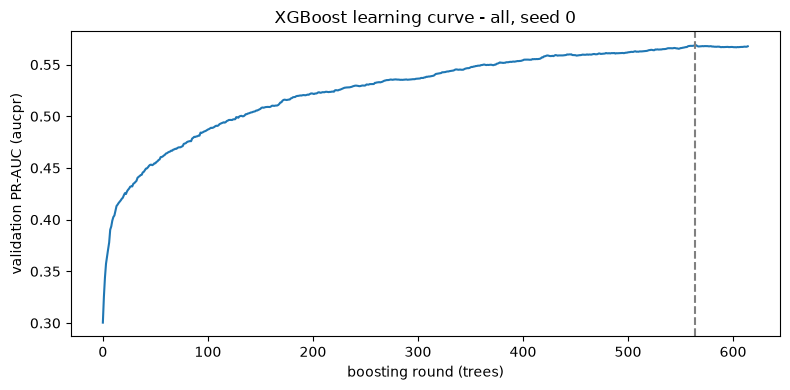

Best iteration: 565 of cap 2000. Change in curve over the last 50 rounds vs the 50 before: +0.00176


In [27]:
# [Jennifer]
curve_models = {k: v for k, v in XGB_MODELS.items() if k[0] in ("all", "+te+beh+vel")}
if not curve_models:
    print("Run 6c or 6e first so there is a fitted model to inspect.")
else:
    key = sorted(curve_models)[0]
    mdl = curve_models[key]
    curve = mdl.evals_result()["validation_0"]["aucpr"]
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(curve)
    ax.axvline(mdl.best_iteration, ls="--", color="gray")
    ax.set_xlabel("boosting round (trees)"); ax.set_ylabel("validation PR-AUC (aucpr)")
    ax.set_title(f"XGBoost learning curve - {key[0]}, seed {key[1]}")
    fig.tight_layout(); plt.show()
    trees = mdl.best_iteration + 1
    tail = np.mean(curve[-50:]) - np.mean(curve[-100:-50]) if len(curve) >= 100 else float("nan")
    print(f"Best iteration: {trees} of cap {mdl.get_params()['n_estimators']}. "
          f"Change in curve over the last 50 rounds vs the 50 before: {tail:+.5f}")
    if trees >= mdl.get_params()["n_estimators"] - 1:
        print("The model hit the tree cap - consider a higher learning_rate or n_estimators.")

### 6i. Interpretation: gain, SHAP, and feature-family permutation importance

**Work by: Jennifer**

Three different questions, three different tools:

| Tool | Question | Caveat |
|---|---|---|
| **Gain** | Which columns did the trees *use* to reduce training loss? | Doesn't prove the column helps on future data (see the `te_card2` surprise in Track A). |
| **SHAP (mean \|contribution\|)** | How much does each column move the *prediction* on validation rows, on average? | Correlated columns split credit between them. XGBoost computes this natively (`pred_contribs=True`), so no extra library is needed. |
| **Family permutation** | If I scramble a whole *family* of columns (all `V*`, all `te_*`, …) together on validation, how much does AP fall? | Shuffling a family jointly keeps within-family correlations, so it is more honest than shuffling one column at a time when columns are redundant. |

Reading them together is the point: a family with high gain but a tiny permutation drop is probably redundant with other columns — consistent with the ablation results.

Top 20 features by mean |SHAP contribution| (model: all, 20k validation rows):


,feature,mean_abs_contribution,family
21,C13,0.3530,C
502,te_card2,0.2440,te
438,amount_to_product_median,0.1867,other_raw
22,C14,0.1769,C
9,C1,0.1734,C
402,card6,0.1593,card/addr/email
472,freq_card1,0.1534,freq
19,C11,0.1455,C
403,P_emaildomain,0.1329,card/addr/email
331,V294,0.1033,V



Family-level view (baseline AP on this 20k sample = 0.5409):


,total_mean_abs_contribution,n_columns,share_of_total_gain,AP_drop
family,,,,
C,1.2636,14,0.1658,0.2008
V,1.7801,339,0.3252,0.1160
other_raw,0.7732,45,0.0724,0.0727
card/addr/email,0.6330,11,0.1056,0.0691
D,0.6380,15,0.0598,0.0619
freq,0.3331,14,0.0397,0.0323
identity,0.3462,39,0.1093,0.0317
te,0.3190,3,0.0431,0.0249
M,0.4045,9,0.0164,0.0165


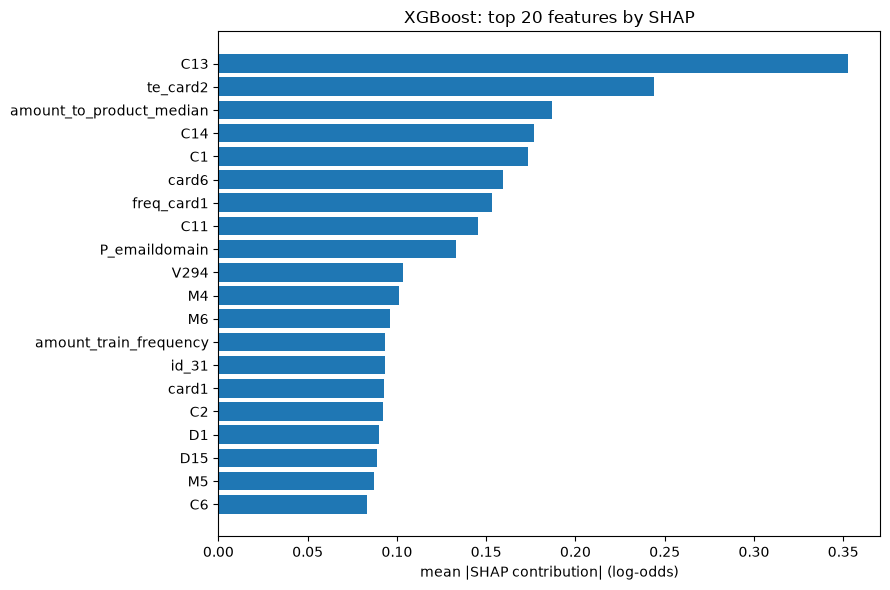

In [28]:
# [Jennifer]
def feature_family(col):
    for prefix in ("te_", "beh_", "vel_", "k1_", "k2_", "freq_", "new_"):
        if col.startswith(prefix):
            return prefix.rstrip("_")
    if re.fullmatch(r"V\d+", col): return "V"
    if re.fullmatch(r"C\d+", col): return "C"
    if re.fullmatch(r"D\d+", col): return "D"
    if re.fullmatch(r"M\d+", col): return "M"
    if col.startswith("id_") or col in ("DeviceType", "DeviceInfo"): return "identity"
    if col.startswith("card") or col.startswith("addr") or "emaildomain" in col: return "card/addr/email"
    return "other_raw"


interp_key = next((k for k in [("all", 0), ("+te+beh+vel", 0)] if k in XGB_MODELS), None)
if interp_key is None:
    print("Run 6c or 6e first (needs a fitted XGBoost model on the full feature set).")
else:
    mdl = XGB_MODELS[interp_key]
    cols = list(mdl.get_booster().feature_names)
    rng = np.random.default_rng(0)
    sample_idx = np.sort(rng.choice(len(XT_val), size=min(20000, len(XT_val)), replace=False))
    sample = XT_val.iloc[sample_idx][cols]
    y_sample = y_val.to_numpy()[sample_idx]

    # --- SHAP-style contributions straight from XGBoost (last column is the bias term) ---
    contrib = mdl.get_booster().predict(xgb_lib.DMatrix(sample, enable_categorical=True), pred_contribs=True)
    shap_tbl = pd.DataFrame({"feature": cols, "mean_abs_contribution": np.abs(contrib[:, :-1]).mean(axis=0)})
    shap_tbl["family"] = shap_tbl.feature.map(feature_family)
    shap_tbl = shap_tbl.sort_values("mean_abs_contribution", ascending=False)
    print(f"Top 20 features by mean |SHAP contribution| (model: {interp_key[0]}, 20k validation rows):")
    display(shap_tbl.head(20).round(4))
    fam_shap = shap_tbl.groupby("family")["mean_abs_contribution"].agg(["sum", "count"]).sort_values("sum", ascending=False)
    fam_shap.columns = ["total_mean_abs_contribution", "n_columns"]

    # --- gain by family ---
    booster_gain = mdl.get_booster().get_score(importance_type="total_gain")
    gain_tbl = pd.DataFrame({"feature": cols, "total_gain": [booster_gain.get(c, 0.0) for c in cols]})
    gain_tbl["family"] = gain_tbl.feature.map(feature_family)
    fam_gain = gain_tbl.groupby("family")["total_gain"].sum()
    fam_gain = (fam_gain / fam_gain.sum()).rename("share_of_total_gain")

    # --- joint permutation of each family on validation ---
    base_ap = average_precision_score(y_sample, mdl.predict_proba(sample)[:, 1])
    perm_rows = []
    fam_cols = {}
    for c in cols:
        fam_cols.setdefault(feature_family(c), []).append(c)
    for fam, fcols in fam_cols.items():
        perm = rng.permutation(len(sample))
        shuffled = sample.copy()
        block = sample[fcols].iloc[perm]
        block.index = sample.index
        shuffled[fcols] = block
        ap = average_precision_score(y_sample, mdl.predict_proba(shuffled)[:, 1])
        perm_rows.append({"family": fam, "n_columns": len(fcols), "AP_after_shuffle": ap, "AP_drop": base_ap - ap})
    perm_tbl = pd.DataFrame(perm_rows).set_index("family").sort_values("AP_drop", ascending=False)

    summary_fam = fam_shap.join(fam_gain).join(perm_tbl[["AP_drop"]])
    print(f"\nFamily-level view (baseline AP on this 20k sample = {base_ap:.4f}):")
    display(summary_fam.sort_values("AP_drop", ascending=False).round(4))
    summary_fam.to_csv(XGB_DIR / "xgb_family_importance.csv")
    shap_tbl.to_csv(XGB_DIR / "xgb_shap_importance.csv", index=False)

    top = shap_tbl.head(20).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(top.feature, top.mean_abs_contribution)
    ax.set_xlabel("mean |SHAP contribution| (log-odds)")
    ax.set_title("XGBoost: top 20 features by SHAP")
    fig.tight_layout(); plt.show()

### 6j. Operating points and calibration

**Work by: Jennifer**

**Operating points.** A fraud team doesn't use AP — it picks a review budget. For each detection target, this table shows the score threshold, how many alerts per 10,000 transactions that creates, the precision of those alerts, and the **TFPR** (legitimate alerts per fraud caught, the advisor's metric).

**Calibration.** Do scores behave like probabilities? Bins on the x-axis are groups of validation transactions ordered by predicted score; the y-axis is the actual fraud rate in the bin. A model trained with `scale_pos_weight` > 1 will sit above the diagonal. Ranking is unaffected, but if anyone wants to quote "the probability of fraud", the scores need recalibration (e.g. isotonic regression fitted on a *separate* later slice, not on the data used to evaluate).

Segment analysis (including address-missing) now lives in 6l.

Operating points for XGBoost / all (validation):


,detection_target,achieved_recall,threshold,alerts_per_10k_txns,precision,TFPR (legit alerts per fraud),FPR
0,0.5,0.5003,0.2446,259.2542,0.6048,0.6533,0.0106
1,0.6,0.6002,0.1347,401.8356,0.4682,1.1359,0.0221
2,0.7,0.7002,0.0687,673.6208,0.3258,2.0694,0.0469
3,0.8,0.8001,0.0303,1345.0401,0.1865,4.3633,0.1130
4,0.9,0.9001,0.0111,3076.8449,0.0917,9.9064,0.2885


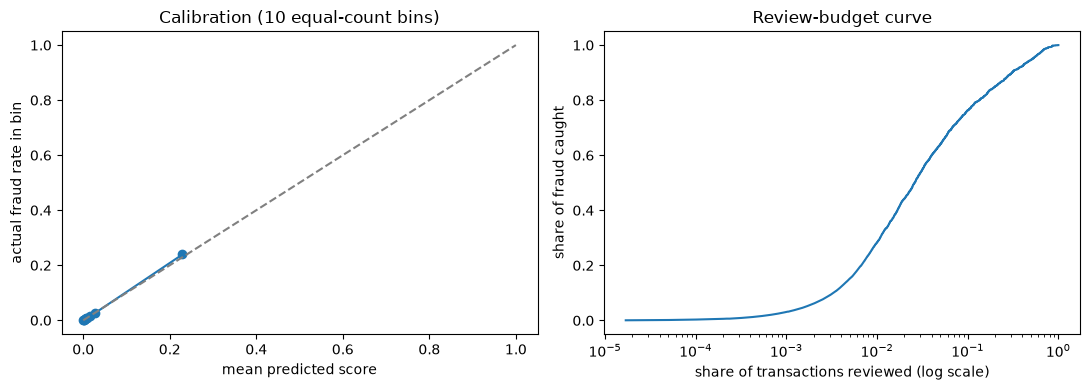

Brier score: 0.01901 (no-skill = 0.03036)


In [29]:
# [Jennifer]
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

pred_sources = [p for p in (xgb_tree_preds, xgb_inc_preds, xgb_extra_preds) if p is not None]
if not pred_sources:
    print("Run 6c, 6e or 6k first - this cell reads their saved validation predictions.")
else:
    all_preds = pd.concat(pred_sources, ignore_index=True)
    pick_name = "all" if "all" in set(all_preds.feature_set) else all_preds.feature_set.iloc[0]
    d = all_preds[(all_preds.feature_set == pick_name) & (all_preds.seed == all_preds.seed.min())]
    y_p, s_p = d.y.to_numpy(), d.score.to_numpy()

    op = ranked_operating_points(y_p, s_p)
    rows = []
    for target in DETECTION_TARGETS:
        hit = op.loc[op.recall >= target]
        if len(hit):
            r = hit.iloc[0]
            rows.append({"detection_target": target, "achieved_recall": r.recall, "threshold": r.threshold,
                         "alerts_per_10k_txns": r.review_rate * 10_000, "precision": r.tp / (r.tp + r.fp),
                         "TFPR (legit alerts per fraud)": r.tfpr, "FPR": r.fpr})
    print(f"Operating points for XGBoost / {pick_name} (validation):")
    display(pd.DataFrame(rows).round(4))

    frac_pos, mean_pred = calibration_curve(y_p, s_p, n_bins=10, strategy="quantile")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(mean_pred, frac_pos, marker="o"); axes[0].plot([0, 1], [0, 1], "--", color="gray")
    axes[0].set_xlabel("mean predicted score"); axes[0].set_ylabel("actual fraud rate in bin")
    axes[0].set_title("Calibration (10 equal-count bins)")
    axes[1].plot(op.review_rate, op.recall)
    axes[1].set_xscale("log"); axes[1].set_xlabel("share of transactions reviewed (log scale)")
    axes[1].set_ylabel("share of fraud caught"); axes[1].set_title("Review-budget curve")
    fig.tight_layout(); plt.show()
    print(f"Brier score: {brier_score_loss(y_p, s_p):.5f} (no-skill = {y_p.mean() * (1 - y_p.mean()):.5f})")

### 6k. New baseline features (built without labels)

**Work by: Jennifer**

The team's engineered families (`te_`, `beh_`, `vel_`, `k1_`, `k2_`) are history- and label-based. The groups below are **cheap, label-free features** that boosted trees often like and that make strong extra baselines. None of them uses `isFraud`, `TransactionDT` or `TransactionID`.

| Group | Features | Idea |
|---|---|---|
| `new_amt_` | log amount, cents, "is round dollar amount", amount ÷ card1 typical amount, amount z-score within card1 | Fraudsters often test cards with small odd amounts, or use amounts atypical for that card |
| `new_miss_` | number of missing values overall and within V / D / id / M blocks | In IEEE-CIS, *which fields are missing* is itself a signal (e.g. no identity record) |
| `new_rows_` | row-wise mean/std/non-zero count of V columns; sum/max/non-zero count of C columns; min/mean of D columns | Compact summaries of the huge anonymized blocks; helps trees and gives the numeric table a denser signal |
| `new_freq_` | how common this card/address/email/device value is | Rare values are riskier; counts are label-free, unlike target encoding |
| `new_email_` | purchaser and recipient email domains match; both missing | Mismatch is a known fraud pattern |

**Leakage rules the code follows:**
* Frequencies, per-card amount means/standard deviations, etc. are **learned from the training rows only**, then looked up for validation. A value that never appeared in training gets frequency 0 / missing.
* No label is used anywhere.
* Caveat for training rows: card-level amount statistics include the row itself. That is a small, label-free in-sample effect (it is not leakage of the answer), but it is one more reason to judge these features on validation.
* **Production note for the advisor discussion:** frequency/mean tables computed from the entire past are "in time" in production *if* they are refreshed using only earlier transactions. The code here freezes them at the end of the training period, which is a conservative simulation of that.

**Test plan:** XGBoost, `all` as reference, then `all` + each new group separately, then `all` + everything. If a group doesn't help on validation across seeds, drop it.

In [30]:
# [Jennifer]
FREQ_SOURCES = ["card1", "card2", "card3", "card5", "addr1", "addr2",
                "P_emaildomain", "R_emaildomain", "DeviceInfo", "id_30", "id_31", "id_33"]


def build_extra_features(tr, va):
    """Label-free features. Anything learned (counts, means, stds) is fitted on `tr` only. Returns (new_tr, new_va, groups)."""
    out_tr, out_va, groups = {}, {}, {}

    def add(group, name, s_tr, s_va):
        out_tr[name] = pd.Series(s_tr, index=tr.index).astype("float32")
        out_va[name] = pd.Series(s_va, index=va.index).astype("float32")
        groups.setdefault(group, []).append(name)

    # ---- amount ----
    if "TransactionAmt" in tr:
        a_tr, a_va = tr["TransactionAmt"].astype(float), va["TransactionAmt"].astype(float)
        add("new_amt", "new_amt_log", np.log1p(a_tr), np.log1p(a_va))
        add("new_amt", "new_amt_cents", (a_tr % 1).round(3), (a_va % 1).round(3))
        add("new_amt", "new_amt_is_round", (a_tr % 1 == 0).astype(float), (a_va % 1 == 0).astype(float))
        if "card1" in tr:
            stats = pd.DataFrame({"k": tr["card1"].astype(object), "a": a_tr}).groupby("k")["a"].agg(["mean", "std", "count"])
            stats = stats[stats["count"] >= 5]
            g_mean, g_std = float(a_tr.mean()), float(a_tr.std()) or 1.0
            for df, a, sink in ((tr, a_tr, "tr"), (va, a_va, "va")):
                key = df["card1"].astype(object)
                mu = key.map(stats["mean"]).astype(float)
                sd = key.map(stats["std"]).astype(float).fillna(g_std).replace(0, g_std)
                ratio, z = a / mu, (a - mu) / sd
                (out_tr if sink == "tr" else out_va)["new_amt_over_card1_mean"] = ratio.astype("float32")
                (out_tr if sink == "tr" else out_va)["new_amt_z_card1"] = z.astype("float32")
            groups.setdefault("new_amt", []).extend(["new_amt_over_card1_mean", "new_amt_z_card1"])

    # ---- missingness counts ----
    add("new_miss", "new_miss_total", tr.isna().sum(axis=1), va.isna().sum(axis=1))
    for label, pattern in (("V", r"V\d+"), ("D", r"D\d+"), ("id", r"id_\d+"), ("M", r"M\d+")):
        cols = [c for c in tr.columns if re.fullmatch(pattern, c)]
        if cols:
            add("new_miss", f"new_miss_{label}", tr[cols].isna().sum(axis=1), va[cols].isna().sum(axis=1))

    # ---- row-wise summaries of anonymized blocks ----
    for label, pattern, funcs in (("V", r"V\d+", ("mean", "std", "nonzero")),
                                  ("C", r"C\d+", ("sum", "max", "nonzero")),
                                  ("D", r"D\d+", ("min", "mean"))):
        cols = [c for c in tr.columns if re.fullmatch(pattern, c)]
        if not cols:
            continue
        b_tr = tr[cols].apply(pd.to_numeric, errors="coerce")
        b_va = va[cols].apply(pd.to_numeric, errors="coerce")
        for fn in funcs:
            if fn == "nonzero":
                f_tr, f_va = (b_tr.fillna(0) != 0).sum(axis=1), (b_va.fillna(0) != 0).sum(axis=1)
            else:
                f_tr, f_va = getattr(b_tr, fn)(axis=1), getattr(b_va, fn)(axis=1)
            add("new_rows", f"new_rows_{label}_{fn}", f_tr, f_va)

    # ---- frequency encodings (train counts) ----
    def freq_map(series_tr):
        return series_tr.astype(object).value_counts(normalize=True, dropna=True)

    for col in [c for c in FREQ_SOURCES if c in tr.columns]:
        fm = freq_map(tr[col])
        add("new_freq", f"new_freq_{col}", tr[col].astype(object).map(fm).fillna(0), va[col].astype(object).map(fm).fillna(0))
    for a, b in (("card1", "addr1"), ("card1", "P_emaildomain")):
        if a in tr.columns and b in tr.columns:
            k_tr = tr[a].astype(str) + "|" + tr[b].astype(str)
            k_va = va[a].astype(str) + "|" + va[b].astype(str)
            fm = k_tr.value_counts(normalize=True)
            add("new_freq", f"new_freq_{a}_{b}", k_tr.map(fm).fillna(0), k_va.map(fm).fillna(0))

    # ---- email relationship ----
    if "P_emaildomain" in tr.columns and "R_emaildomain" in tr.columns:
        for df, sink in ((tr, out_tr), (va, out_va)):
            p, r = df["P_emaildomain"].astype(object), df["R_emaildomain"].astype(object)
            both = p.notna() & r.notna()
            match = pd.Series(np.where(both, (p == r).astype(float), np.nan), index=df.index)
            sink["new_email_match"] = match.astype("float32")
            sink["new_email_both_missing"] = (p.isna() & r.isna()).astype("float32")
        groups.setdefault("new_email", []).extend(["new_email_match", "new_email_both_missing"])

    new_tr = pd.DataFrame(out_tr, index=tr.index)
    new_va = pd.DataFrame(out_va, index=va.index)
    new_tr = new_tr.replace([np.inf, -np.inf], np.nan)
    new_va = new_va.replace([np.inf, -np.inf], np.nan)
    return new_tr, new_va, groups


extra_tr, extra_va, extra_groups = build_extra_features(X_train, X_val)
assert extra_tr.index.equals(X_train.index) and extra_va.index.equals(X_val.index)
assert not FORBIDDEN.intersection(extra_tr.columns)
print({g: len(c) for g, c in extra_groups.items()}, "| total new columns:", extra_tr.shape[1])
display(extra_tr.describe().T[["count", "mean", "std", "min", "max"]].round(3).head(40))

XP_train = pd.concat([XT_train, extra_tr], axis=1)
XP_val = pd.concat([XT_val, extra_va], axis=1)

{'new_amt': 5, 'new_miss': 5, 'new_rows': 8, 'new_freq': 13, 'new_email': 2} | total new columns: 33


,count,mean,std,min,max
new_amt_log,472432.0,4.383,0.934,0.224,10.372
new_amt_cents,472432.0,0.376,0.432,0.000,0.999
new_amt_is_round,472432.0,0.518,0.500,0.000,1.000
new_amt_over_card1_mean,459487.0,1.000,1.376,0.003,119.906
new_amt_z_card1,459487.0,0.000,0.993,-3.615,34.950
new_miss_total,472432.0,190.798,45.207,19.000,343.000
new_miss_V,472432.0,145.743,40.927,11.000,266.000
new_miss_D,472432.0,8.842,2.526,1.000,15.000
new_miss_id,472432.0,19.883,5.551,0.000,23.000
new_miss_M,472432.0,0.000,0.000,0.000,0.000


In [31]:
# [Jennifer]
if RUN["xgb_extra_features"]:
    ref_cols = feature_sets["all"]
    xgb_sets_6k = {"all (reference)": ref_cols}
    for group, gcols in extra_groups.items():
        xgb_sets_6k[f"all + {group}"] = ref_cols + gcols
    xgb_sets_6k["all + every new group"] = ref_cols + [c for g in extra_groups.values() for c in g]
    xgb_extra_results, xgb_extra_preds, xgb_extra_imps = run_xgb_sets(
        xgb_sets_6k, XP_train, XP_val, XGB_SEEDS, tag="extra_features")
    summarize_runs(xgb_extra_results, reference="all (reference)")
    print("Interpretation: a positive 'AP gain' for a group (all + group minus reference) means the group helps on validation.")
    ref_ap = xgb_extra_results.loc[xgb_extra_results.feature_set == "all (reference)", "pr_auc"].mean()
    gains = (xgb_extra_results.groupby("feature_set", sort=False)["pr_auc"].mean() - ref_ap).rename("AP_gain_vs_reference")
    display(gains.round(4).to_frame())
else:
    print("6k experiment skipped (RUN['xgb_extra_features'] is False).")

6k experiment skipped (RUN['xgb_extra_features'] is False).


**Work by: Jennifer**

**Other features worth trying next (not built here because they need `TransactionDT` or the raw files):**

* **Time-of-day / day-of-week** from `TransactionDT` (it is deliberately excluded from predictors in this notebook; derive hour/day in the FE notebook, then drop the raw timestamp).
* **True velocity windows** (transactions per card in the last 1h/24h/7d, strictly earlier than the current row) — the `vel_` family already covers some of this; compare before building more.
* **Time since the card's previous transaction** and **amount change vs the card's previous transaction** (strictly earlier rows only).
* **Device/browser consistency:** is this card seen with a new `DeviceInfo`/`id_31`/`id_30` combination for the first time?
* **Out-of-fold target encoding** for more categoricals, built with an earlier-labels-only rule (the advisor's "in time" question).
* **OpenFE / Featuretools** candidates, judged with the same KS table, metrics, and SHAP as above.

### 6l. Robustness: time slices and transaction segments

**Work by: Jennifer**

A model that is strong on average can still fail in a period or segment that matters. This cell loads the saved validation metadata (`TransactionDT`, `ProductCD`) and reports PR-AUC for time thirds, product types, address present/missing, identity present/missing, account-history present/absent and amount quartiles.

**Read it carefully:** compare PR-AUC against **each segment's own fraud rate**, never across segments (higher prevalence raises PR-AUC by itself). Segments with fewer than 30 fraud cases or 30 legitimate cases are skipped. `TransactionDT` is used here only to *slice the evaluation*; it is not a model predictor.

In [32]:
# [Jennifer]
y_val_arr = y_val.to_numpy()
MIN_FRAUD = 30

meta_path = FE_DIR / "metadata_validation.parquet"
meta_val = None
if meta_path.exists():
    meta_val = pd.read_parquet(meta_path).reindex(X_val.index)
    if meta_val["TransactionDT"].isna().any():
        print("metadata_validation.parquet does not cover every validation row; time/product segments disabled")
        meta_val = None
time_order = (np.argsort(meta_val["TransactionDT"].to_numpy(), kind="stable")
              if meta_val is not None else np.arange(len(X_val)))
if meta_val is None:
    print("No usable metadata: bootstrap blocks use row order and time/product segments are skipped.")

# Saved LightGBM predictions from Track A (feature set 'all', seed 0), if they line up with these rows
lgb_all_scores = None
if "lgbm_predictions" in globals():
    _p = lgbm_predictions[(lgbm_predictions.feature_set == "all") & (lgbm_predictions.seed == 0)]
    if len(_p) == len(X_val) and np.array_equal(_p.row_index.to_numpy(), X_val.index.to_numpy()):
        lgb_all_scores = _p.score.to_numpy()


def scores_from(preds, name, seed=0):
    d = preds[(preds.feature_set == name) & (preds.seed == seed)]
    return d.score.to_numpy() if len(d) == len(X_val) else None


def build_segments():
    seg = {"all validation": np.ones(len(X_val), dtype=bool)}
    if meta_val is not None:
        third = pd.qcut(meta_val["TransactionDT"].to_numpy(), 3, labels=False, duplicates="drop")
        for i in np.unique(third):
            seg[f"time third {i + 1} of {len(np.unique(third))}"] = third == i
        if "ProductCD" in meta_val:
            for prod in sorted(meta_val["ProductCD"].astype(str).unique()):
                seg[f"ProductCD = {prod}"] = (meta_val["ProductCD"].astype(str) == prod).to_numpy()
    if "addr1" in X_val:
        seg["addr1 missing"] = X_val["addr1"].isna().to_numpy()
        seg["addr1 present"] = ~seg["addr1 missing"]
    if "has_identity" in X_val:
        seg["has identity data"] = (X_val["has_identity"] == 1).to_numpy()
        seg["no identity data"] = ~seg["has identity data"]
    for k in ("k1", "k2"):
        if f"{k}_has_prior" in X_val:
            seg[f"{k} account history present"] = (X_val[f"{k}_has_prior"] == 1).to_numpy()
            seg[f"{k} account history absent"] = ~seg[f"{k} account history present"]
    q = pd.qcut(amount_val, 4, labels=False, duplicates="drop")
    for i in np.unique(q):
        seg[f"amount quartile {i + 1}"] = q == i
    return seg


segments = build_segments()


def segment_table(score, label):
    rows = []
    for name, mask in segments.items():
        lab = y_val_arr[mask]
        if lab.sum() < MIN_FRAUD or (1 - lab).sum() < MIN_FRAUD:
            continue
        m = evaluate(lab, score[mask], amount_val[mask])
        rows.append({"model": label, "segment": name, "n": int(mask.sum()), "fraud": int(lab.sum()),
                     "fraud_rate": m["fraud_rate"], "pr_auc": m["pr_auc"], "roc_auc": m["roc_auc"],
                     "recall_at_1pct_fpr": m["recall_at_1pct_fpr"],
                     "tfpr_at_50pct_detection": m["tfpr_at_50pct_detection"],
                     "fraud_cases_top5pct": m["fraud_cases_top5pct"]})
    return pd.DataFrame(rows)


if xgb_tree_preds is None:
    print("Run 6c first (needs XGBoost validation predictions).")
else:
    seg_frames = [segment_table(scores_from(xgb_tree_preds, n), f"xgb {n}")
                  for n in ("raw", "all") if scores_from(xgb_tree_preds, n) is not None]
    seg_df = pd.concat(seg_frames, ignore_index=True)
    seg_df.to_csv(XGB_DIR / "xgb_segment_results.csv", index=False)
    display(seg_df.round(4))

,model,segment,n,fraud,fraud_rate,pr_auc,roc_auc,recall_at_1pct_fpr,tfpr_at_50pct_detection,fraud_cases_top5pct
0,xgb raw,all validation,59054,1851,0.0313,0.5675,0.9103,0.5057,0.5799,0.6494
1,xgb raw,time third 1 of 3,19685,667,0.0339,0.5217,0.9038,0.4663,0.7006,0.6132
2,xgb raw,time third 2 of 3,19684,618,0.0314,0.6297,0.9254,0.5534,0.3883,0.6861
3,xgb raw,time third 3 of 3,19685,566,0.0288,0.5582,0.9023,0.5018,0.6572,0.6502
4,xgb raw,ProductCD = C,5628,666,0.1183,0.7660,0.9353,0.5420,0.0991,0.3934
5,xgb raw,ProductCD = H,1561,85,0.0545,0.6366,0.8842,0.5059,0.3023,0.5529
6,xgb raw,ProductCD = R,2558,120,0.0469,0.7943,0.9398,0.7167,0.0167,0.7500
7,xgb raw,ProductCD = S,1064,70,0.0658,0.6237,0.8707,0.4286,0.5429,0.4857
8,xgb raw,ProductCD = W,48243,910,0.0189,0.3537,0.8820,0.3868,2.3912,0.5780
9,xgb raw,addr1 missing,5486,664,0.1210,0.7671,0.9349,0.5407,0.0994,0.3855


### 6m. Is a difference real? Time-block bootstrap

**Work by: Jennifer**

A normal bootstrap treats transactions as independent, but fraud arrives in time-clustered bursts. Here we resample **contiguous blocks of validation time** (100 blocks) and recompute the AP difference each time. `delta = AP(A) - AP(B)`. If the 95% interval includes 0, the gap is indistinguishable from noise **on this validation period**. It does not tell you how performance will change in future periods, and it ignores model-training randomness (use several seeds for that).

In [33]:
# [Jennifer]
def block_bootstrap_delta(y, s_a, s_b, order, n_blocks=100, n_boot=300, seed=0):
    rng = np.random.default_rng(seed)
    blocks = np.array_split(order, n_blocks)
    deltas = []
    for _ in range(n_boot):
        idx = np.concatenate([blocks[i] for i in rng.integers(0, n_blocks, n_blocks)])
        if y[idx].sum() == 0:
            continue
        deltas.append(average_precision_score(y[idx], s_a[idx]) - average_precision_score(y[idx], s_b[idx]))
    d = np.array(deltas)
    return {"delta": average_precision_score(y, s_a) - average_precision_score(y, s_b),
            "ci_low": np.percentile(d, 2.5), "ci_high": np.percentile(d, 97.5)}


if xgb_tree_preds is None:
    print("Run 6c first.")
else:
    s_all = scores_from(xgb_tree_preds, "all")
    pairs = [("XGBoost all vs XGBoost raw", "raw"),
             ("XGBoost all vs XGBoost all_minus_behavior", "all_minus_behavior"),
             ("XGBoost all vs XGBoost all_minus_target_encoding", "all_minus_target_encoding")]
    out = []
    for label, other in pairs:
        s_other = scores_from(xgb_tree_preds, other)
        if s_other is not None:
            out.append({"comparison": label, **block_bootstrap_delta(y_val_arr, s_all, s_other, time_order)})
    if lgb_all_scores is not None:
        out.append({"comparison": "XGBoost all vs LightGBM all",
                    **block_bootstrap_delta(y_val_arr, s_all, lgb_all_scores, time_order)})
    boot_df = pd.DataFrame(out)
    boot_df["interval_excludes_zero"] = (boot_df.ci_low > 0) | (boot_df.ci_high < 0)
    boot_df.to_csv(XGB_DIR / "paired_block_bootstrap.csv", index=False)
    display(boot_df.round(4))

,comparison,delta,ci_low,ci_high,interval_excludes_zero
0,XGBoost all vs XGBoost raw,0.0014,-0.0078,0.0114,False
1,XGBoost all vs XGBoost all_minus_behavior,-0.0023,-0.0104,0.0051,False
2,XGBoost all vs XGBoost all_minus_target_encoding,-0.0121,-0.0223,-0.0015,True
3,XGBoost all vs LightGBM all,-0.0626,-0.0765,-0.0493,True


### 6n. Error analysis: which fraud do we miss?

**Work by: Jennifer**

Pretend analysts review only the top 5% of scores. Fraud inside that group is *caught*; fraud outside is *missed*. What the misses have in common tells the team where new features might help, which is more useful than another tenth of a point of AP. The cutoff is set from validation scores; a deployed system would fix it beforehand.

In [34]:
# [Jennifer]
if xgb_tree_preds is None:
    print("Run 6c first.")
else:
    REVIEW = 0.05
    s_err = scores_from(xgb_tree_preds, "all")
    top_n = int(round(len(s_err) * REVIEW))
    thr = np.sort(s_err)[::-1][top_n - 1]
    flagged = s_err >= thr
    missed = (y_val_arr == 1) & ~flagged
    caught = (y_val_arr == 1) & flagged
    print(f"reviewing top {REVIEW:.0%} ({flagged.sum():,} transactions, score >= {thr:.4f})")
    print(f"fraud caught {caught.sum():,} | missed {missed.sum():,} | "
          f"fraud dollars caught ${amount_val[caught].sum():,.0f} | missed ${amount_val[missed].sum():,.0f}")
    if caught.sum() and missed.sum():
        print(f"median amount: caught ${np.median(amount_val[caught]):,.2f} | missed ${np.median(amount_val[missed]):,.2f}")

    rows = []
    for name, mask in segments.items():
        f = int(((y_val_arr == 1) & mask).sum())
        if f >= MIN_FRAUD:
            rows.append({"segment": name, "fraud": f, "share_missed": float((missed & mask).sum() / f),
                         "dollars_missed_share": float(amount_val[missed & mask].sum() /
                                                       max(amount_val[(y_val_arr == 1) & mask].sum(), 1))})
    miss_df = pd.DataFrame(rows).sort_values("share_missed", ascending=False)
    miss_df.to_csv(XGB_DIR / "missed_fraud_by_segment.csv", index=False)
    display(miss_df.round(3))

    worst = X_val.loc[missed, ["TransactionAmt"]].copy()
    if meta_val is not None and "ProductCD" in meta_val:
        worst["ProductCD"] = meta_val.loc[missed, "ProductCD"].to_numpy()
    if "addr1" in X_val:
        worst["addr1_missing"] = X_val.loc[missed, "addr1"].isna().to_numpy()
    worst["score"] = s_err[missed]
    worst["score_rank_pct"] = (rankdata(-s_err)[missed] / len(s_err))
    worst = worst.sort_values("TransactionAmt", ascending=False)
    worst.head(25).to_csv(XGB_DIR / "largest_missed_fraud.csv")
    print("\nLargest missed fraud transactions (by dollar amount):")
    display(worst.head(10).round(4))

reviewing top 5% (2,953 transactions, score >= 0.1011)
fraud caught 1,185 | missed 666 | fraud dollars caught $160,277 | missed $108,204
median amount: caught $59.00 | missed $96.82


,segment,fraud,share_missed,dollars_missed_share
8,ProductCD = W,910,0.532,0.510
12,no identity data,926,0.529,0.509
19,amount quartile 3,408,0.493,0.509
10,addr1 present,1187,0.470,0.440
13,k1 account history present,865,0.438,0.396
1,time third 1 of 3,667,0.396,0.412
16,k2 account history absent,817,0.388,0.463
20,amount quartile 4,530,0.364,0.396
0,all validation,1851,0.360,0.403
5,ProductCD = H,85,0.353,0.314



Largest missed fraud transactions (by dollar amount):


,TransactionAmt,ProductCD,addr1_missing,score,score_rank_pct
TransactionID,,,,,
3491411,3076.97,W,False,0.0031,0.6412
3494038,1949.69,W,False,0.0045,0.5433
3476245,1795.80,W,False,0.0021,0.7260
3509557,1601.00,W,False,0.0348,0.1191
3499538,1402.85,W,False,0.0027,0.6717
3498919,1402.85,W,False,0.0186,0.2034
3466480,1331.00,W,False,0.0154,0.2378
3489944,1104.00,W,False,0.0342,0.1212
3465187,1104.00,W,False,0.0355,0.1173


### 6o. Blend: XGBoost + LightGBM (+ logistic regression)

**Work by: Jennifer**

A **rank average** converts each model's scores to ranks (0 to 1) and averages them, which avoids mixing incompatible score scales. Two different tree libraries often give a small but consistent lift. This cell reuses scores you already have (Track A LightGBM, Track B logistic regression, 6c XGBoost), so nothing is retrained. Judge the blend with the same block bootstrap as 6m.

In [35]:
# [Jennifer]
if xgb_tree_preds is None:
    print("Run 6c first.")
else:
    from itertools import combinations
    blend_inputs = {"xgboost": scores_from(xgb_tree_preds, "all")}
    if lgb_all_scores is not None:
        blend_inputs["lightgbm"] = lgb_all_scores
    if "logreg_scores" in globals() and len(logreg_scores) == len(X_val):
        blend_inputs["logreg"] = np.asarray(logreg_scores)
    keys = ["pr_auc", "roc_auc", "recall_at_1pct_fpr", "tfpr_at_50pct_detection", "fraud_cases_top5pct"]
    rows = [{"model": n, **{k: evaluate(y_val, v, amount_val)[k] for k in keys}} for n, v in blend_inputs.items()]
    blends = {}
    names = list(blend_inputs)
    for r in range(2, len(names) + 1):
        for combo in combinations(names, r):
            sc = np.mean([rankdata(blend_inputs[n]) / len(blend_inputs[n]) for n in combo], axis=0)
            label = "blend: " + " + ".join(combo)
            blends[label] = sc
            rows.append({"model": label, **{k: evaluate(y_val, sc, amount_val)[k] for k in keys}})
    blend_df = pd.DataFrame(rows)
    blend_df.to_csv(XGB_DIR / "blend_results.csv", index=False)
    display(blend_df.round(4))
    if blends:
        best_single = max(blend_inputs, key=lambda n: average_precision_score(y_val, blend_inputs[n]))
        print(f"Best single model by AP: {best_single}. Time-block bootstrap of each blend vs that model:")
        out = []
        for label, sc in blends.items():
            out.append({"blend": label, **block_bootstrap_delta(y_val_arr, sc, blend_inputs[best_single], time_order)})
        bd = pd.DataFrame(out)
        bd["interval_excludes_zero"] = (bd.ci_low > 0) | (bd.ci_high < 0)
        display(bd.round(4))
        print("Reading it: a blend only counts if its interval is entirely above 0. Averaging in a much weaker "
              "model (logistic regression) usually drags the blend below the best single model. Choosing the "
              "best blend on validation is itself slightly optimistic.")
    else:
        print("Only one model's scores available. Run Track A (LightGBM) to enable blends.")

,model,pr_auc,roc_auc,recall_at_1pct_fpr,tfpr_at_50pct_detection,fraud_cases_top5pct
0,xgboost,0.5689,0.9159,0.4927,0.6533,0.6402
1,lightgbm,0.6315,0.9308,0.5640,0.3434,0.6840
2,logreg,0.4276,0.8667,0.3760,1.9806,0.5084
3,blend: xgboost + lightgbm,0.6098,0.9264,0.5429,0.4309,0.6710
4,blend: xgboost + logreg,0.5014,0.9032,0.4268,1.2343,0.5613
5,blend: lightgbm + logreg,0.5229,0.9130,0.4462,1.0518,0.5802
6,blend: xgboost + lightgbm + logreg,0.5357,0.9175,0.4495,0.9330,0.6002


Best single model by AP: lightgbm. Time-block bootstrap of each blend vs that model:


,blend,delta,ci_low,ci_high,interval_excludes_zero
0,blend: xgboost + lightgbm,-0.0217,-0.0288,-0.0153,True
1,blend: xgboost + logreg,-0.1301,-0.1487,-0.1131,True
2,blend: lightgbm + logreg,-0.1086,-0.1244,-0.0933,True
3,blend: xgboost + lightgbm + logreg,-0.0958,-0.1106,-0.0816,True


Reading it: a blend only counts if its interval is entirely above 0. Averaging in a much weaker model (logistic regression) usually drags the blend below the best single model. Choosing the best blend on validation is itself slightly optimistic.


### 6o2. Blend with the improved XGBoost (integer codes, learning rate 0.05)

**Work by: Jennifer**

**Question:** the earlier blend (6o) used the weaker XGBoost run (native categoricals, learning rate 0.1) and the blend lost to LightGBM alone. Now that XGBoost is stronger (AP 0.610), does a rank-average blend of XGBoost and LightGBM beat LightGBM by itself?

**Setup:** seed 0 for both models (the only seed with saved LightGBM predictions), feature set `all`, rank average at three weights on XGBoost (25%, 50%, 75%). Logistic regression is left out because it lowered every earlier blend. Each blend is compared with LightGBM alone using the time-block bootstrap.

| Model | AP | ROC-AUC | Recall at 1% FPR | TFPR at 50% detection | Fraud found, top 5% |
|---|---:|---:|---:|---:|---:|
| XGBoost (int codes, lr 0.05) | 0.6103 | 0.9272 | 0.5311 | 0.4752 | 0.6764 |
| **LightGBM** | **0.6315** | 0.9308 | **0.5640** | **0.3434** | 0.6840 |
| Blend 25% XGBoost + 75% LightGBM | 0.6312 | **0.9316** | 0.5602 | 0.3629 | 0.6883 |
| Blend 50% / 50% | 0.6277 | 0.9313 | 0.5473 | 0.3747 | **0.6888** |
| Blend 75% XGBoost + 25% LightGBM | 0.6216 | 0.9299 | 0.5467 | 0.4190 | 0.6823 |

**Blend minus LightGBM (AP), with the time-block bootstrap interval:**

| XGBoost weight | Difference | 95% interval | Verdict |
|---|---:|---|---|
| 25% | −0.0003 | −0.0029 to +0.0021 | Tie |
| 50% | −0.0038 | −0.0087 to +0.0008 | Not distinguishable from LightGBM |
| 75% | −0.0099 | −0.0173 to −0.0031 | Worse than LightGBM |

**Observed:**
- No blend beats LightGBM alone on average precision. AP falls steadily as the weight on XGBoost rises.
- The 25% blend ties LightGBM. It is marginally higher on ROC-AUC (0.9316 vs 0.9308) and on fraud found in the top 5% (0.6883 vs 0.6840, roughly 8 of 1,851 fraud cases). It is slightly worse on recall at 1% FPR and on TFPR at 50% detection.
- These small differences all fall inside the noise, so none of them is a reason to prefer the blend.

**Interpretation:** XGBoost does not add information the LightGBM model lacks. A likely reason is that both are boosted trees trained on the same features, so their errors overlap, but we did not test that.

**Limits:**
- Seed 0 only.
- The blend weights were looked at on validation, which makes a gain look slightly better than it is; here there is no gain to inflate.
- Only a rank average was tried, with no stacking and no tuning.

**Decision:** do not use a blend. A single model is simpler to explain and monitor, and the blend adds no clear benefit. If the team stays with XGBoost, it should expect about 0.02 AP less than LightGBM on this data. Revisit blending only if the XGBoost model is tuned or gets new features.

In [36]:
# [Jennifer]
# 6o2 - Blend using the BETTER XGBoost (integer codes, lr 0.05, seed 0 from 6d3) instead of the earlier native-category run.
# Seed 0 is used because LightGBM's saved predictions (lgb_all_scores) are seed 0 as well.
codes_pred_file = XGB_DIR / "xgb_codes_lr005_seed0_predictions.parquet"
if not codes_pred_file.exists():
    print("Run 6d3 first (it saves the seed-0 predictions this cell reads).")
elif lgb_all_scores is None:
    print("LightGBM seed-0 'all' predictions not available; run Track A and the 6l cell first.")
else:
    p0 = pd.read_parquet(codes_pred_file)
    assert len(p0) == len(X_val) and np.array_equal(p0.row_index.to_numpy(), X_val.index.to_numpy()), "rows do not line up"
    pair = {"xgboost (int codes, lr 0.05)": p0.score.to_numpy(), "lightgbm": lgb_all_scores}
    keys = ["pr_auc", "roc_auc", "recall_at_1pct_fpr", "tfpr_at_50pct_detection", "fraud_cases_top5pct"]
    rank01 = lambda v: rankdata(v) / len(v)

    rows = [{"model": n, **{k: evaluate(y_val, v, amount_val)[k] for k in keys}} for n, v in pair.items()]
    blend_scores = {}
    for w in (0.25, 0.50, 0.75):             # weight on XGBoost in the rank average
        blend_scores[w] = w * rank01(pair["xgboost (int codes, lr 0.05)"]) + (1 - w) * rank01(pair["lightgbm"])
        rows.append({"model": f"blend: {w:.0%} xgboost + {1 - w:.0%} lightgbm",
                     **{k: evaluate(y_val, blend_scores[w], amount_val)[k] for k in keys}})
    blend2_df = pd.DataFrame(rows)
    display(blend2_df.round(4))
    blend2_df.to_csv(XGB_DIR / "blend_codes_results.csv", index=False)

    print("Time-block bootstrap: each blend vs LightGBM alone (positive = blend better; needs the whole interval above 0):")
    out = []
    for w, sc in blend_scores.items():
        out.append({"blend (weight on xgboost)": w, **block_bootstrap_delta(y_val_arr, sc, pair["lightgbm"], time_order)})
    bd2 = pd.DataFrame(out)
    bd2["interval_excludes_zero"] = (bd2.ci_low > 0) | (bd2.ci_high < 0)
    display(bd2.round(4))
    print("Picking the best weight on validation is itself slightly optimistic; treat a small gain as a lead, not a result.")

,model,pr_auc,roc_auc,recall_at_1pct_fpr,tfpr_at_50pct_detection,fraud_cases_top5pct
0,"xgboost (int codes, lr 0.05)",0.6103,0.9272,0.5311,0.4752,0.6764
1,lightgbm,0.6315,0.9308,0.5640,0.3434,0.6840
2,blend: 25% xgboost + 75% lightgbm,0.6312,0.9316,0.5602,0.3629,0.6883
3,blend: 50% xgboost + 50% lightgbm,0.6277,0.9313,0.5473,0.3747,0.6888
4,blend: 75% xgboost + 25% lightgbm,0.6216,0.9299,0.5467,0.4190,0.6823


Time-block bootstrap: each blend vs LightGBM alone (positive = blend better; needs the whole interval above 0):


,blend (weight on xgboost),delta,ci_low,ci_high,interval_excludes_zero
0,0.25,-0.0003,-0.0029,0.0021,False
1,0.50,-0.0038,-0.0087,0.0008,False
2,0.75,-0.0099,-0.0173,-0.0031,True


Picking the best weight on validation is itself slightly optimistic; treat a small gain as a lead, not a result.


### 6p. Leave-one-family-out ablation (every engineered feature family)

**Work by: Jennifer**

The saved manifest (`new_feature_families`) groups engineered columns into families such as target encoding, velocity, history, missingness and frequency. For each family we retrain XGBoost on `all` minus that family:

`delta = AP(all) - AP(all without the family)`

* **Positive:** removing it hurt, so the family helps.
* **About zero:** redundant; other columns carry the same information.
* **Negative:** removing it helped, so it adds noise on this validation period.

Gain importance cannot answer this, because a feature can rank high and still be redundant. This is the table to show your advisor. It trains one model per family per seed, so it is **off by default** (`RUN["xgb_family_ablation"]`). Use `FAMILY_SEEDS = [0, 1, 2]` and compare the mean delta with the seed-to-seed spread.

In [37]:
# [Jennifer]
manifest_families = {f: [c for c in cols if c in set(all_cols)]
                     for f, cols in manifest.get("new_feature_families", {}).items()}
xgb_family_df = None
if RUN["xgb_family_ablation"] and manifest_families:
    recs = []
    for seed in FAMILY_SEEDS:
        ref_model = fit_xgboost(XT_train[all_cols], y_train, XT_val[all_cols], y_val, seed, FAST_PARAMS)
        ref_ap = average_precision_score(y_val, ref_model.predict_proba(XT_val[all_cols])[:, 1])
        print(f"seed {seed} reference (all): AP {ref_ap:.4f}")
        for fam, fam_cols in manifest_families.items():
            keep = [c for c in all_cols if c not in set(fam_cols)]
            mdl = fit_xgboost(XT_train[keep], y_train, XT_val[keep], y_val, seed, FAST_PARAMS)
            ap = average_precision_score(y_val, mdl.predict_proba(XT_val[keep])[:, 1])
            recs.append({"family": fam, "n_columns": len(fam_cols), "seed": seed,
                         "ap_all": ref_ap, "ap_without": ap, "delta": ref_ap - ap})
            print(f"  without {fam:20s} ({len(fam_cols):3d} cols) AP {ap:.4f}  delta {ref_ap - ap:+.4f}")
    fam_runs = pd.DataFrame(recs)
    fam_runs.to_csv(XGB_DIR / "family_ablation_by_run.csv", index=False)
    xgb_family_df = (fam_runs.groupby(["family", "n_columns"])["delta"].agg(["mean", "std"]).reset_index()
                     .sort_values("mean", ascending=False))
    xgb_family_df.to_csv(XGB_DIR / "family_ablation_summary.csv", index=False)
    display(xgb_family_df.round(4))
    fig, ax = plt.subplots(figsize=(8, 5))
    d = xgb_family_df.iloc[::-1]
    ax.barh(d.family, d["mean"], xerr=d["std"].fillna(0))
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("AP(all) - AP(without family); positive = family helps")
    plt.tight_layout(); plt.show()
elif RUN["xgb_family_ablation"]:
    print("manifest.json has no 'new_feature_families'; nothing to ablate.")
else:
    print("6p skipped (RUN['xgb_family_ablation'] is False).")

6p skipped (RUN['xgb_family_ablation'] is False).


### 6q. Leakage sanity check: shuffled labels

**Work by: Jennifer**

If we shuffle the **training labels** and retrain, the model has nothing real to learn, so validation PR-AUC should collapse to about the fraud rate (~0.03) and ROC-AUC to about 0.5. A score clearly above that means some feature carries information it shouldn't.

**Design notes.** Fixed number of trees and **no early stopping**, because early stopping would look at the real validation labels and pick whichever iteration happens to score best. It repeats over 3 shuffles because a single shuffled model can land above or below chance by luck; judge the **mean**.

**Important:** target-encoded (`te_`) columns were built from the *real* labels, so shuffling labels afterwards would not test them. The test therefore uses `all_minus_target_encoding`, whose remaining features are label-free. The `te_` columns need their own check: rebuild them from shuffled labels in the feature-engineering notebook.

In [38]:
# [Jennifer]
xgb_shuffle_result = None
if RUN["shuffled_label_test"]:
    sh_cols = feature_sets["all_minus_target_encoding"]
    sh_params = {k: v for k, v in FAST_PARAMS.items() if k not in ("early_stopping_rounds", "eval_metric")}
    sh_params["n_estimators"] = 150
    rows = []
    for sh in range(3):
        y_shuf = np.random.default_rng(1000 + sh).permutation(y_train.to_numpy())
        mdl = XGBClassifier(**sh_params, n_jobs=XGB_N_JOBS, random_state=sh, verbosity=0).fit(XT_train[sh_cols], y_shuf)
        sc = mdl.predict_proba(XT_val[sh_cols])[:, 1]
        rows.append({"shuffle": sh, "pr_auc": average_precision_score(y_val, sc), "roc_auc": roc_auc_score(y_val, sc)})
    xgb_shuffle_result = pd.DataFrame(rows)
    display(xgb_shuffle_result.round(4))
    mean_ap, mean_roc = xgb_shuffle_result.pr_auc.mean(), xgb_shuffle_result.roc_auc.mean()
    print(f"mean over 3 shuffles: PR-AUC {mean_ap:.4f} (fraud rate {y_val.mean():.4f}) | ROC-AUC {mean_roc:.4f} (chance = 0.5)")
    if mean_ap > 1.5 * y_val.mean() or mean_roc > 0.55:
        print("WARNING: clearly above chance with shuffled labels; investigate possible leakage.")
    else:
        print("OK: shuffled labels give roughly chance-level scores.")
else:
    print("6q skipped (RUN['shuffled_label_test'] is False).")

,shuffle,pr_auc,roc_auc
0,0,0.0303,0.4429
1,1,0.0347,0.4869
2,2,0.0352,0.4577


mean over 3 shuffles: PR-AUC 0.0334 (fraud rate 0.0313) | ROC-AUC 0.4625 (chance = 0.5)
OK: shuffled labels give roughly chance-level scores.


### 6r. Scoreboard with all XGBoost variants

**Work by: Jennifer**

One table so the team can see every XGBoost run next to the other tracks. **Read it with the caveats in section 7:** different feature tables, and validation-based early stopping.

In [39]:
# [Jennifer]
board = []
for name in ("lgbm_results", "xgb_tree_results", "xgb_inc_results", "xgb_spw_results", "xgb_extra_results"):
    obj = globals().get(name)
    if obj is not None:
        board.append(obj.assign(source=name))
for name in ("logreg_metrics", "jean_logreg_metrics", "xgb_metrics"):  # [Merged notebook] added Jean's logistic regression (B2)
    obj = globals().get(name)
    if obj is not None:
        board.append(pd.DataFrame([obj]).assign(source=name))
if not board:
    print("Nothing has been run yet.")
else:
    scoreboard = pd.concat(board, ignore_index=True)
    show = ["source", "model", "feature_set", "n_features", "pr_auc", "roc_auc", "ks", "recall_at_1pct_fpr",
            "tfpr_at_50pct_detection", "tfpr_at_80pct_detection", "fraud_cases_top5pct", "fraud_dollars_top5pct"]
    display(scoreboard[[c for c in show if c in scoreboard]].groupby(
        ["source", "model", "feature_set"], sort=False).mean(numeric_only=True).round(4)
        .sort_values("pr_auc", ascending=False))
    scoreboard.to_csv(XGB_DIR / "scoreboard_all_runs.csv", index=False)

n_features  \
source              model                    feature_set                             
lgbm_results        lightgbm                 all_minus_behavior              505.0   
                                             all_minus_target_encoding       534.0   
                                             all                             537.0   
                                             raw                             430.0   
xgb_metrics         xgboost                  nn_table                        515.0   
xgb_tree_results    xgboost                  all_minus_target_encoding       534.0   
                                             all_minus_behavior              505.0   
                                             all                             537.0   
                                             raw                             430.0   
logreg_metrics      logistic_regression      nn_table                        515.0   
jean_logreg_metrics logistic_regression_jean all                             830.0   

                                                                        pr_auc  \
source              model                    feature_set                         
lgbm_results        lightgbm                 all_minus_behavior         0.6406   
                                             all_minus_target_encoding  0.6369   
                                             all                        0.6315   
                                             raw                        0.6204   
xgb_metrics         xgboost                  nn_table                   0.6096   
xgb_tree_results    xgboost                  all_minus_target_encoding  0.5810   
                                             all_minus_behavior         0.5712   
                                             all                        0.5689   
                                             raw                        0.5675   
logreg_metrics      logistic_regression      nn_table                   0.4276   
jean_logreg_metrics logistic_regression_jean all                        0.4276   

                                                                        roc_auc  \
source              model                    feature_set                          
lgbm_results        lightgbm                 all_minus_behavior          0.9303   
                                             all_minus_target_encoding   0.9311   
                                             all                         0.9308   
                                             raw                         0.9262   
xgb_metrics         xgboost                  nn_table                    0.9248   
xgb_tree_results    xgboost                  all_minus_target_encoding   0.9167   
                                             all_minus_behavior          0.9189   
                                             all                         0.9159   
                                             raw                         0.9103   
logreg_metrics      logistic_regression      nn_table                    0.8667   
jean_logreg_metrics logistic_regression_jean all                         0.8560   

                                                                            ks  \
source              model                    feature_set                         
lgbm_results        lightgbm                 all_minus_behavior         0.7267   
                                             all_minus_target_encoding  0.7207   
                                             all                        0.7282   
                                             raw                        0.7165   
xgb_metrics         xgboost                  nn_table                   0.7180   
xgb_tree_results    xgboost                  all_minus_target_encoding  0.6970   
                                             all_minus_behavior         0.6963   
                                             all                    

### 6s. XGBoost decision log — fill in as you run each step

**Work by: Jennifer**

| Question | Where | What we saw | Decision |
|---|---|---|---|
| Does XGBoost on the tree table beat XGBoost on the numeric table? | 6c vs Track C | No. Integer codes at learning rate 0.05 give mean AP 0.613 (3 seeds), against 0.610 on the numeric table. That is a tie. | Use integer-coded categoricals for XGBoost. |
| XGBoost vs LightGBM, same tree table | 6d | LightGBM leads by about 0.025 AP on both paired seeds (−0.021 and −0.028), beyond the roughly 0.008 seed noise. | Report LightGBM as roughly 0.02 AP ahead, untuned. Don’t call XGBoost equal. |
| Which family adds the most on top of the base set? | 6e | Not run. | Run before reporting. |
| Do `te_` / `beh_` / `vel_` still look unhelpful for XGBoost, or only for LightGBM? | 6c, 6e | XGBoost: removing te_ raised AP 0.569 → 0.581 (interval excludes 0). Removing beh_/vel_: no clear effect. LightGBM: removing te_ changed AP by −0.005 on seed 0 and +0.012 on seed 1 (full model minus without-te_). Removing beh_: −0.009 and +0.007. | Inconclusive. te_ is the one to watch, since the XGBoost interval excludes 0. Don’t drop any family until it repeats with the better XGBoost setup over 3 seeds (6p). |
| Is `scale_pos_weight` worth using? | 6f | Not run. | Keep at 1 (default). Low priority. |
| Did the tree cap limit any run? | 6h | No. 6c all stopped at 565 of 2,000 trees. 6d2 run A used 2,926 of 4,000. The 6c curve was still rising slightly at the stop (+0.0018 over the last 50 rounds). | No cap issue. Use learning rate 0.05 with patience 100 for the final model, since patience 50 stopped too early. |
| Which families carry the signal (SHAP, permutation)? | 6i | Shuffling C costs 0.20 AP and V 0.12. Next are other_raw 0.07, card/addr/email 0.07 and D 0.06. te costs 0.025, beh 0.011, vel 0.005. te_card2 is the 2nd-largest single feature by SHAP, though removing the te_ family didn’t hurt. | The raw C and V blocks carry most of the signal. The engineered families add little on top. High importance for te_card2 doesn’t mean it helps, as the ablation shows. |
| Which new label-free groups help? | 6k | The 33 features are built, but the experiment hasn’t been run. | Run xgb_extra_features before claiming anything. |
| Review budget / detection target to present to the advisor | 6j | Per fraud caught: at 50% detection, 259 alerts per 10k transactions, 60% precision, TFPR 0.65. At 60%: 402 alerts, 47%, 1.14. At 70%: 674, 33%, 2.07. At 80%: 1,345, 19%, 4.36. At 90%: 3,077, 9%, 9.91. | Validation stays under 10:1 TFPR all the way to 90% detection. Ask the advisor which detection target and review capacity she means. Redo this table with the final model. |
| Is performance stable across time thirds and segments? | 6l | all AP by time third: 0.542, 0.618, 0.552 (fraud rates 0.034, 0.031, 0.029). By product: C 0.774, R 0.826, S 0.607, H 0.576, W 0.343. Address missing 0.776 vs present 0.436. | Fairly stable over time. ProductCD = W is the weak segment (about 80% of the validation rows). Compare AP only within a segment, not across them. |
| Is any AP gap larger than time-block noise? | 6m | all vs raw +0.001, interval includes 0. all vs −beh: −0.002, includes 0. all vs −te: −0.012, excludes 0. all vs LightGBM: −0.063, excludes 0. | Only the te_ removal and the LightGBM gap clear the noise, and the LightGBM gap shrank in 6d2. Rerun 6m with the final XGBoost. |
| Which fraud do we miss, and can a feature fix it? | 6n | At a 5% review rate, 666 of 1,851 fraud cases (36%) are missed, about $108k of $268k fraud dollars. The most-missed groups are ProductCD = W (53%), no identity data (53%), amount quartile 3 (49%) and address present (47%). The largest misses are $1.1k–$3.1k W transactions with very low scores. | Target W, no-identity and address-present transactions with new features. Look at why the biggest dollar misses score so low. |
| Does a blend beat the best single model? | 6o, 6o2 | With the improved XGBoost, a 25% XGBoost / 75% LightGBM blend ties LightGBM (AP 0.6312 vs 0.6315; interval −0.003 to +0.002). Higher XGBoost weights get worse (75%: −0.010, interval excludes 0). Every blend including logistic regression was worse. | No blend. Use a single model. Revisit if XGBoost is tuned or gains new features. |
| Which manifest families help or are redundant? | 6p | Not run. | Run it with FAMILY_SEEDS = [0, 1, 2] if time allows. It’s the table the advisor will want. |
| Any sign of leakage? | 6q | Shuffled labels: mean AP 0.033 vs 0.031 fraud rate, ROC-AUC 0.46 (chance is 0.5). | No sign of leakage in the label-free features. The te_ columns aren’t covered, so check them in the feature-engineering notebook. |

---
# Sections 7–14 — Side-by-side results, findings, follow-up experiments and handoff

**Work by: Jennifer.** The tables in Section 7 now also include Jean's logistic regression from B2. Eric's neural networks are added in the all-team scoreboard at the end, after Sections D0–D19 run.

## 7. Side-by-side validation results

**Work by: Jennifer**

**Why compare in one place?** A scoreboard that mixes metrics can hide important tradeoffs. This table brings the three *separately trained* model tracks together while labeling the input table and feature set used.

**Caveat:** these experiments do not prove which algorithm is fundamentally best; feature representations and tuning effort differ. Use the results to choose follow-up experiments, not to declare production readiness.

In [40]:
# [Jennifer]
# Run this after whichever model tracks you want to compare. Unexecuted tracks are omitted.
comparisons = []
if "lgbm_results" in globals():
    comparisons.extend(lgbm_results.to_dict("records"))
if "logreg_metrics" in globals():
    comparisons.append(logreg_metrics)
if "jean_logreg_metrics" in globals():  # [Merged notebook] added Jean's logistic regression (B2)
    comparisons.append(jean_logreg_metrics)
if "xgb_metrics" in globals():
    comparisons.append(xgb_metrics)
if comparisons:
    combined = pd.DataFrame(comparisons)
    columns = ["model", "feature_set", "seed", "n_features", "pr_auc", "roc_auc", "ks",
               "recall_at_1pct_fpr", "tfpr_at_50pct_detection",
               "tfpr_at_80pct_detection", "fraud_cases_top5pct", "fraud_dollars_top5pct"]
    display(combined[[c for c in columns if c in combined]].round(4))
    combined.to_csv(OUTPUT_DIR / "all_models_validation_results.csv", index=False)
else:
    print("No tracks have been run yet. Train at least one model first.")

,model,feature_set,seed,n_features,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_80pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
0,lightgbm,raw,0,430,0.6204,0.9262,0.7165,0.5543,0.3499,3.3153,0.6807,0.6337
1,lightgbm,all,0,537,0.6315,0.9308,0.7282,0.5640,0.3434,2.9838,0.6840,0.6402
2,lightgbm,all_minus_target_encoding,0,534,0.6369,0.9311,0.7207,0.5732,0.2840,3.1425,0.6845,0.6371
3,lightgbm,all_minus_behavior,0,505,0.6406,0.9303,0.7267,0.5802,0.3056,2.9696,0.6910,0.6456
4,logistic_regression,nn_table,0,515,0.4276,0.8667,0.5684,0.3760,1.9806,9.0338,0.5084,0.4654
5,logistic_regression_jean,all,0,830,0.4276,0.8560,0.5624,0.3663,1.9914,10.7103,0.5132,0.4732
6,xgboost,nn_table,0,515,0.6096,0.9248,0.7180,0.5316,0.4579,3.3680,0.6699,0.6569


---
# 8. Findings from our completed validation run (observations, not final conclusions)

**Work by: Jennifer**

**Source:** the executed outputs already saved earlier in *this* notebook. This section records what the team actually saw, so readers do not have to reconstruct the story from long tables. Scores describe the **validation period**, not the untouched holdout.

### 8a. Question: which model is the strongest starting point?

| Metric | Logistic regression (numeric table) | XGBoost (numeric table) | LightGBM (`all`, tree table) |
|---|---:|---:|---:|
| Average precision / PR-AUC | 0.4276 | 0.6096 | **0.6315** |
| ROC-AUC | 0.8667 | 0.9248 | **0.9308** |
| Recall at 1% FPR | 37.60% | 53.16% | **56.40%** |
| Legitimate alerts per fraud caught, at 50% recall | 1.981 | 0.458 | **0.343** |
| Fraud cases found when reviewing top 5% | 50.84% | 66.99% | **68.40%** |
| Fraud dollars found when reviewing top 5% | 46.54% | **65.69%** | 64.02% |

**Plain-English interpretation:** The tree-based models are better at ranking suspicious payments in these starting configurations. At a fixed allowance of false alarms (1% of legitimate payments), LightGBM catches about 56 out of 100 frauds; logistic regression catches about 38 out of 100. Logistic regression still beats a random-ranking no-skill baseline by a large margin.

**Why this is not yet an apples-to-apples algorithm contest:** Logistic regression and XGBoost used 515 numeric features, while LightGBM used 537 tree-table features. Even with the same later validation transactions, a difference could come from *the algorithm, its preprocessing, or its tuning*. Follow-up Experiment 2 below addresses this.

**PR-AUC note:** this notebook uses scikit-learn's `average_precision_score` (average precision/AP). AP summarizes the precision–recall curve and has a no-skill reference equal to fraud prevalence (here roughly 0.0313). It is not automatically identical to a trapezoidal area under a plotted PR curve.


### 8b. Question: did our engineered features improve LightGBM?

**Work by: Jennifer**

The completed single-seed run compared **the same LightGBM training procedure** on the same train/validation rows, changing only which feature columns it received.

| Input features | Columns | Validation AP | AP change vs `all` |
|---|---:|---:|---:|
| Raw features only | 430 | 0.6204 | −0.0111 |
| All engineered + raw | 537 | 0.6315 | reference |
| All except target encodings (`te_`) | 534 | 0.6369 | +0.0054 |
| All except behavioral/velocity (`beh_`, `vel_`) | 505 | **0.6406** | +0.0091 |

**Beginner-friendly example:** Suppose the full model earns 0.6315 AP. We rebuild the same model **without** the three target-encoding columns, and AP increases to 0.6369. On this specific run, removing them helped. It does **not** mean the features are inherently wrong or that they should be permanently discarded: a different seed, time period, or transaction group may show a different pattern.

**A surprising result:** Our earlier LightGBM gain file placed `te_card2` at rank #3, `te_R_emaildomain` at #19, and `te_P_emaildomain` at #32. High *gain importance* means the trained model often improved its training objective by splitting on those features. It does **not** prove that keeping them improves *future* predictions; other columns may encode similar information. Ablation is the better test of their incremental value.

**From the previous three-seed run (historical context):** `raw` averaged 0.6283 AP; `all_no_history` 0.6398; `all` 0.6378; `all_no_jennifer` 0.6358. Since model results vary by seed, one-run AP differences like 0.0054 need replication. These earlier numbers came from a separate experimental configuration, so do not combine them with the new run as if they were one matched experiment.


### 8c. Question: do history features help a specific kind of transaction?

**Work by: Jennifer**

The engineering team designed **Key 2** to provide behavioral history even if billing address (`addr1`) is missing. That group represented a disproportionate share of fraud in the training data. A change that looks small across the entire dataset might matter greatly within this group.

| Feature set | AP for missing `addr1` | AP for present `addr1` |
|---|---:|---:|
| Raw | 0.7992 | 0.5199 |
| All | 0.8061 | 0.5291 |
| All minus target encoding | **0.8161** | 0.5324 |
| All minus behavior/velocity | 0.8018 | **0.5495** |

**How to read this:** In the *address-missing* group, retaining behavior features corresponds to AP 0.8061 versus 0.8018 when they're removed, a small benefit in this run. In the *address-present* group, removing behavior yields better AP. The effect may depend on the population, but we need more seeds before trusting the pattern.

**Do not compare 0.80 vs 0.53 as if it proved one group is easier:** Each group's fraud prevalence differs, and AP depends on prevalence. Compare feature sets *within the same group* first.

**Additional caution:** `all_minus_behavior` removes `beh_` and `vel_`, but it still includes other history columns beginning with `k1_` and `k2_`. Thus it tests a *particular behavior/velocity block*, not 'all possible history'.


## 9. NEXT EXPERIMENT 1 — Repeat only the important LightGBM ablations

**Work by: Jennifer**

**Question (H3/H4):** Were the one-seed improvements from dropping target encoding or behavioral features repeatable?

**Hypothesis:** If a feature family truly helps later transactions, the model with those features will generally score higher than the model without them under **matched seeds**.

**Procedure:** Use seeds 0, 1, and 2, with **identical** LightGBM settings and chronological validation rows in each comparison. Compare the AP *difference for each matching seed*: `AP(all) − AP(without feature group)`. Positive means keeping the removed group helped; negative means removing it helped.

**Why not just look at standard deviations?** Seed-to-seed variation describes the training algorithm's randomness; it is not a formal confidence interval for real-world performance. Three seeds are a useful diagnostic, not proof of significance.

**What gets trained in the next cell:** LightGBM only. No logistic regression, no XGBoost, no holdout. Results are saved separately so the existing run is not overwritten.


In [41]:
# [Jennifer]
# NEXT EXPERIMENT 1 - matched-seed LightGBM ablations (RESUMABLE).
# Each finished fit is saved to disk right away (.../followup_experiments/ablation_checkpoints), so stopping the
# cell or restarting the kernel never loses finished work: re-running skips fits that are already saved.
# Cost: len(ABLATION_SETS) x len(ABLATION_SEEDS) LightGBM fits, ~2-3 minutes each on this data.
RUN_ABLATION_EXPERIMENT = True        # set False to skip while you work on XGBoost
ABLATION_SEEDS = [0, 1]               # add 2 later: seeds 0 and 1 are loaded from disk, only seed 2 trains
ABLATION_SETS = ["all", "all_minus_target_encoding", "all_minus_behavior"]


def repeat_targeted_ablations(sets=ABLATION_SETS, seeds=ABLATION_SEEDS):
    next_dir = OUTPUT_DIR / "followup_experiments"
    ckpt = next_dir / "ablation_checkpoints"
    ckpt.mkdir(parents=True, exist_ok=True)
    signature = json.dumps(LGBM_PARAMS, sort_keys=True, default=str)     # a changed config invalidates old checkpoints
    records, predictions = [], []
    for seed in seeds:
        for name in sets:
            meta_f, score_f = ckpt / f"{name}_seed{seed}.json", ckpt / f"{name}_seed{seed}.npy"
            rec = scores = None
            if meta_f.exists() and score_f.exists():
                saved = json.loads(meta_f.read_text())
                loaded = np.load(score_f)
                if saved.get("params_signature") == signature and len(loaded) == len(X_val):
                    rec, scores = saved, loaded
                    print(f"seed {seed} | {name:31s} | AP {rec['pr_auc']:.4f} | loaded from checkpoint")
            if rec is None:
                cols = feature_sets[name]
                start = time.perf_counter()
                mdl = fit_lightgbm(X_train[cols], y_train, X_val[cols], y_val, seed)
                scores = mdl.predict_proba(X_val[cols])[:, 1]
                metrics = evaluate(y_val, scores, amount_val)
                rec = {"model": "lightgbm", "feature_set": name, "seed": seed, "n_features": len(cols),
                       "best_iteration": int(mdl.best_iteration_), "elapsed_seconds": time.perf_counter() - start,
                       "params_signature": signature, **metrics}
                meta_f.write_text(json.dumps(rec, default=float))
                np.save(score_f, scores)
                print(f"seed {seed} | {name:31s} | AP {metrics['pr_auc']:.4f} | trees {mdl.best_iteration_} "
                      f"| {rec['elapsed_seconds']:.0f}s | saved")
            records.append(rec)
            predictions.append(pd.DataFrame({"feature_set": name, "seed": seed, "row_index": X_val.index.to_numpy(),
                                             "y": y_val.to_numpy(), "score": scores}))
    result = pd.DataFrame(records).drop(columns=["params_signature"])
    pred = pd.concat(predictions, ignore_index=True)
    result.to_csv(next_dir / "targeted_ablation_results.csv", index=False)
    pred.to_parquet(next_dir / "targeted_ablation_predictions.parquet", index=False)
    return result, pred


ablation_results = globals().get("ablation_results")
ablation_predictions = globals().get("ablation_predictions")
if RUN_ABLATION_EXPERIMENT:
    ablation_results, ablation_predictions = repeat_targeted_ablations()
else:
    print("Experiment 1 skipped (RUN_ABLATION_EXPERIMENT = False).")

seed 0 | all                             | AP 0.6315 | loaded from checkpoint
seed 0 | all_minus_target_encoding       | AP 0.6369 | loaded from checkpoint
seed 0 | all_minus_behavior              | AP 0.6406 | loaded from checkpoint
seed 1 | all                             | AP 0.6391 | loaded from checkpoint
seed 1 | all_minus_target_encoding       | AP 0.6267 | loaded from checkpoint
seed 1 | all_minus_behavior              | AP 0.6317 | loaded from checkpoint


In [42]:
# [Jennifer]
# Report matched-seed differences after the experiment above.
# Positive delta = full model is better; negative delta = ablated model is better.
if ablation_results is None:
    print("Follow-up not run yet. Uncomment the training call above, then rerun this cell.")
else:
    full = ablation_results.loc[ablation_results.feature_set == "all", ["seed", "pr_auc"]]
    for name in ["all_minus_target_encoding", "all_minus_behavior"]:
        reduced = ablation_results.loc[ablation_results.feature_set == name, ["seed", "pr_auc"]]
        paired = full.merge(reduced, on="seed", suffixes=("_all", "_without"))
        paired["delta_full_minus_without"] = paired.pr_auc_all - paired.pr_auc_without
        print(f"\n{name}: average paired delta = {paired.delta_full_minus_without.mean():+.4f}")
        display(paired.round(5))



all_minus_target_encoding: average paired delta = +0.0035


,seed,pr_auc_all,pr_auc_without,delta_full_minus_without
0,0,0.63151,0.63689,-0.00538
1,1,0.63909,0.62669,0.01240



all_minus_behavior: average paired delta = -0.0009


,seed,pr_auc_all,pr_auc_without,delta_full_minus_without
0,0,0.63151,0.64065,-0.00914
1,1,0.63909,0.63175,0.00734


### 9a. Interpretation prompts (fill in after running)

**Work by: Jennifer**

- **Observation:** Do all three paired differences have the same sign? What is their average?
- **Meaning:** If removing target encodings still helps, could `card2`, `freq_card2`, or other correlated columns already capture similar signals?
- **Alternative explanation:** Could the features be unstable over time? The team's earlier stability scores for category fraud rankings were about 0.48 (`card2`), 0.68 (`R_emaildomain`), and 0.31 (`P_emaildomain`).
- **Decision:** Retain a feature group only with a reason tied to consistent validation benefit, operational value, or segment-specific impact. Do not discard it just because a single run lost a few thousandths of AP.


## 10. NEXT EXPERIMENT 2 — Fairer LightGBM vs XGBoost comparison

**Work by: Jennifer**

**Question (H1):** Does LightGBM still beat XGBoost when they receive **exactly the same features**, rather than one getting the tree table and the other the normalized numeric table?

**Hypothesis:** Gradient-boosted trees should perform well on these transactions, but which library wins is an empirical question.

**Controlled setup:** Both models receive the existing **515-column numeric (`nn`) table**, on identical rows and labels. We keep the already fitted XGBoost from Track C for comparison, and train a new LightGBM on that same numeric representation. Logistic regression also used this input, so you can place all three next to each other.

**What is *not* perfectly controlled:** Their tree shapes, search spaces, built-in defaults, hyperparameters, and early-stopping criteria still differ. This is a **fairer input comparison**, not a definitive benchmark after equal tuning.

**Why we do not convert the tree table directly:** The original tree table has categorical types that may need separate XGBoost handling. Using the same saved numeric representation is the simplest clean comparison for students.

**What gets trained below:** only one *new LightGBM model*. The cell does not refit the other two models.


In [43]:
# [Jennifer]
# NEXT EXPERIMENT 2 - LightGBM on the exact same numeric table used by logistic regression and XGBoost.
import re

def safe_feature_names(columns):
    """LightGBM rejects names with JSON characters (: , [ ] { } "). Replace anything odd with '_'.
    If two names collapse to the same text, add a numeric suffix so every column stays unique."""
    out, seen = [], {}
    for c in columns:
        s = re.sub(r"[^0-9a-zA-Z_]+", "_", str(c)).strip("_") or "col"
        if s in seen:
            seen[s] += 1
            s = f"{s}__{seen[s]}"
        else:
            seen[s] = 0
        out.append(s)
    return out


def run_lightgbm_on_numeric_table(seed=0):
    if "Xn_train" not in globals():
        raise RuntimeError("Run the logistic regression DATA-LOADING cell first to define Xn_train/Xn_val.")
    start = time.perf_counter()

    # Work on renamed COPIES of the column labels; Xn_train / Xn_val keep their original names.
    safe = safe_feature_names(Xn_train.columns)
    Xtr = Xn_train.set_axis(safe, axis=1)
    Xva = Xn_val.set_axis(safe, axis=1)

    mdl = fit_lightgbm(Xtr, yn_train, Xva, yn_val, seed)
    scores = mdl.predict_proba(Xva)[:, 1]
    metrics = evaluate(y_val, scores, amount_val)
    record = {"model": "lightgbm", "feature_set": "nn_table", "seed": seed,
              "n_features": Xn_train.shape[1], "best_iteration": mdl.best_iteration_,
              "elapsed_seconds": time.perf_counter() - start, **metrics}
    out = OUTPUT_DIR / "followup_experiments"
    out.mkdir(parents=True, exist_ok=True)
    pd.DataFrame([record]).to_csv(out / "lightgbm_on_numeric_table.csv", index=False)
    pd.DataFrame({"original_name": Xn_train.columns, "lightgbm_name": safe}).to_csv(
        out / "lightgbm_numeric_name_map.csv", index=False)
    print("Numeric-table LightGBM trained; XGBoost and logistic regression were NOT retrained.")
    display(pd.DataFrame([record])[["model", "feature_set", "pr_auc", "roc_auc",
                                    "recall_at_1pct_fpr", "tfpr_at_50pct_detection"]].round(4))
    return record, scores


lgbm_numeric_metrics, lgbm_numeric_scores = run_lightgbm_on_numeric_table()

/Users/Jennifer/Developer/BTT Fall AI Studio/Banking-1B-online-payment-fraud-detection-using-high-dimensional-transaction-data/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Numeric-table LightGBM trained; XGBoost and logistic regression were NOT retrained.


,model,feature_set,pr_auc,roc_auc,recall_at_1pct_fpr,tfpr_at_50pct_detection
0,lightgbm,nn_table,0.6193,0.9287,0.5402,0.3996


In [44]:
# [Jennifer]
# Show the controlled same-input comparison after running experiment 2.
if lgbm_numeric_metrics is None:
    print("Follow-up not run yet; the existing three-model results above are not a same-input comparison.")
else:
    records = [lgbm_numeric_metrics]
    if "logreg_metrics" in globals(): records.append(logreg_metrics)
    if "xgb_metrics" in globals(): records.append(xgb_metrics)
    display(pd.DataFrame(records)[["model", "feature_set", "pr_auc", "roc_auc",
                                   "recall_at_1pct_fpr", "tfpr_at_50pct_detection",
                                   "fraud_cases_top5pct", "fraud_dollars_top5pct"]].round(4))


,model,feature_set,pr_auc,roc_auc,recall_at_1pct_fpr,tfpr_at_50pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
0,lightgbm,nn_table,0.6193,0.9287,0.5402,0.3996,0.6742,0.6468
1,logistic_regression,nn_table,0.4276,0.8667,0.3760,1.9806,0.5084,0.4654
2,xgboost,nn_table,0.6096,0.9248,0.5316,0.4579,0.6699,0.6569


### 10a. Why the logistic regression section stays equally important

**Work by: Jennifer**

Suppose a model predicts fraud risk using a weighted sum of features, then passes it through an S-shaped **sigmoid** function. That is logistic regression. It is fast, widely taught, and gives us an important check: **how much can we predict with a relatively simple, approximately linear relationship?**

The tree models can learn nonlinear splits and interactions without explicitly creating every combination. If they clearly outperform logistic regression on the same rows, that suggests flexibility matters **in this configuration**, not that logistic regression was unnecessary. A simpler model is often easier to inspect and maintain.

**Class weight caution:** We used balanced class weights for logistic regression. That changes the objective and can make predicted scores less well calibrated as literal probabilities. Ranking metrics (AP, ROC-AUC) are still useful; do not announce a score of `0.80` means an 80% real fraud chance without calibration testing.


## 11. NEXT EXPERIMENT 3 — Where do history features help?

**Work by: Jennifer**

**Question (H4):** Does the behavior/velocity feature group help transactions with missing addresses, as the engineering hypothesis suggested?

**Plan:** Reuse **the predictions from Experiment 1**. No new models are required. Calculate AP, recall at a fixed FPR, TFPR, and fraud capture separately for `addr1` missing vs present, using the same validation rows.

This is an important lesson in efficient modeling: **compute additional analysis from saved predictions instead of retraining models** when possible.

**Avoid overclaiming:** A segment with high fraud prevalence naturally has a higher AP no-skill level. Include each segment's fraud rate and focus on within-segment model differences. Also, removing `beh_` and `vel_` leaves other `k1_`/`k2_` history features intact.


In [45]:
# [Jennifer]
# NEXT EXPERIMENT — analyzes predictions from Experiment 1 without retraining.
if ablation_predictions is None:
    print("Run Experiment 1 first; its saved predictions drive this analysis.")
else:
    if "addr1" not in X_val.columns:
        raise KeyError("addr1 is required to define the segment")
    address_missing = X_val["addr1"].isna().to_numpy()
    seg_rows = []
    for (name, seed), d in ablation_predictions.groupby(["feature_set", "seed"], sort=False):
        assert np.array_equal(d.row_index.to_numpy(), X_val.index.to_numpy()), "Row order mismatch"
        for group, mask in [("address_missing", address_missing), ("address_present", ~address_missing)]:
            lab = d.y.to_numpy()[mask]
            if len(np.unique(lab)) < 2:
                continue
            scores = d.score.to_numpy()[mask]
            m = evaluate(lab, scores, amount_val[mask])
            seg_rows.append({"feature_set": name, "seed": seed, "segment": group,
                             "n_transactions": int(mask.sum()), "fraud_count": int(lab.sum()), **m})
    followup_segment_results = pd.DataFrame(seg_rows)
    display(followup_segment_results[["feature_set", "seed", "segment", "n_transactions",
                                      "fraud_rate", "pr_auc", "recall_at_1pct_fpr",
                                      "tfpr_at_50pct_detection"]].round(4))
    out = OUTPUT_DIR / "followup_experiments"
    out.mkdir(parents=True, exist_ok=True)
    followup_segment_results.to_csv(out / "segment_analysis_by_seed.csv", index=False)


,feature_set,seed,segment,n_transactions,fraud_rate,pr_auc,recall_at_1pct_fpr,tfpr_at_50pct_detection
0,all,0,address_missing,5486,0.1210,0.8061,0.5753,0.0934
1,all,0,address_present,53568,0.0222,0.5291,0.4903,1.0067
2,all_minus_target_encoding,0,address_missing,5486,0.1210,0.8161,0.5934,0.0813
3,all_minus_target_encoding,0,address_present,53568,0.0222,0.5324,0.4819,1.0892
4,all_minus_behavior,0,address_missing,5486,0.1210,0.8018,0.5708,0.0873
5,all_minus_behavior,0,address_present,53568,0.0222,0.5495,0.5072,0.7828
6,all,1,address_missing,5486,0.1210,0.8115,0.5753,0.0873
7,all,1,address_present,53568,0.0222,0.5392,0.4895,1.0185
8,all_minus_target_encoding,1,address_missing,5486,0.1210,0.8129,0.5813,0.0723
9,all_minus_target_encoding,1,address_present,53568,0.0222,0.5139,0.4693,1.0421


## 12. Validation diagnostics before tuning (read before reporting final results)

**Work by: Jennifer**

### 12a. Tree-count ceiling

Early stopping evaluates models as trees are added, picking a point that works well on validation. In your earlier experiment some LightGBM runs reached the 3,000-tree ceiling; the XGBoost run selected iteration 2,986 out of a maximum 3,000. That is near the cap, so its search may have been constrained. It is *not* evidence that the model is invalid or that adding more trees will necessarily help.

**Next decision:** compare learning curves / iterations and, only where warranted, extend the maximum or adjust learning rate. If you change tuning settings, rerun both sides of a feature ablation under the **same** settings.

### 12b. Leakage is a process question, not a score question

Very strong PR-AUC alone cannot prove no leakage. Verify that target encodings for each training fold use **earlier labels only**, and validation uses mappings fitted on training only. Historical features must use transactions strictly earlier than the transaction being scored, including ties at the same timestamp. Scaling and category vocabularies must come from training only. The exact chronological boundary should be confirmed in the upstream engineering artifact; non-overlapping Pandas indices alone do not prove time order.

**Shuffled-label warning:** randomizing labels *after* constructing target-encoded features with real fraud labels is not a valid leakage diagnostic. Rebuild label-dependent engineering from shuffled training labels before testing.

### 12c. Uncertainty and evaluation discipline

Three seeds check sensitivity to model randomness. They do not give formal statistical confidence for future deployment. If differences remain tiny, consider a paired bootstrap of validation transactions or another appropriate uncertainty analysis while accounting for temporal dependence. Use validation to choose; use the chronologically later **holdout once** after locking decisions.

### 12d. Operational metrics are not interchangeable

- **Recall at 1% FPR:** of all actual frauds, how many can we catch while flagging no more than 1% of legitimate transactions?
- **TFPR at 50% recall:** how many *legitimate* transactions get flagged per *fraud* caught by the time we catch at least half the fraud? Lower is better.
- **Top-5% fraud capture:** if investigators can review just 5 out of every 100 transactions, what fraction of fraud cases do they find?
- **Top-5% dollar capture:** within that same workload, what fraction of total fraudulent transaction dollars do they find?

The team's advisor target (roughly 10:1 TFPR near 50–60% detection) still needs confirmation. Do not claim an operational victory without agreeing on the detection target, threshold rule, and review budget.


## 13. Consolidated findings and decision log — update as experiments finish

**Work by: Jennifer**

This follows the same **hypothesis → evidence → interpretation → next step** pattern as the EDA. The cells above contain the observed validation scores. This table was updated after the XGBoost section and the three follow-up experiments were run (validation split only).

| Research question | Evidence so far (validation split) | What we can say now | Next action |
|---|---|---|---|
| **H1. Do flexible models help?** | Logistic AP 0.428. XGBoost (integer-coded categoricals, learning rate 0.05, 3 seeds) 0.610 to 0.616. LightGBM 0.632 and 0.639 (seeds 0, 1). On the identical numeric table: LightGBM 0.619, XGBoost 0.610. | Yes, trees beat logistic regression by about 0.18 AP. LightGBM leads XGBoost by about 0.02 AP on the tree table and about 0.01 on the numeric table. | Tune XGBoost (6g) and re-compare; report LightGBM as the untuned reference. |
| **H2. Do engineered features help?** | LightGBM raw 0.6204 vs all 0.6315 (seed 0). XGBoost (native categoricals) raw 0.5675 vs all 0.5689, interval includes 0. | No clear benefit of the full engineered set over raw features yet. | Re-test with the improved XGBoost over 3 seeds (6p). |
| **H3. Does target encoding help?** | LightGBM: removing `te_` changed AP by -0.005 (seed 0) and +0.012 (seed 1). XGBoost (native categoricals): removing `te_` raised AP by 0.012, interval excludes 0. `te_card2` is the 2nd-largest feature by SHAP. | Inconsistent across seeds and models; high importance did not translate into a gain. | Repeat with the improved XGBoost over 3 seeds; discuss out-of-time encoding with the advisor. |
| **H4. Does behavior help?** | LightGBM: removing `beh_`/`vel_` changed AP by -0.009 and +0.007 (seeds 0, 1). XGBoost: -0.002, interval includes 0. Family permutation drop: `beh` 0.011, `vel` 0.005. | No consistent effect. | Same as H3. |
| **H5. Are alerts useful?** | XGBoost (6c) at 50% detection: 259 alerts per 10k transactions, 0.65 legitimate alerts per fraud caught; at 90% detection: 9.9. LightGBM at 50%: 0.343. | Under the advisor's rough 10:1 target up to about 90% detection on validation. The target itself is still unconfirmed. | Confirm the detection target and review capacity; redo the table with the final model. |
| **H6. Are conclusions final?** | Validation was used for early stopping and comparisons; the holdout is not scored. | No. These are development findings. | Freeze model, features and parameters; score the holdout once. |
| **H7. Does blending help?** | Improved XGBoost + LightGBM: 25% blend ties LightGBM (-0.0003, interval includes 0); heavier XGBoost weights are worse. Blends with logistic regression are worse. | No. A single model is enough. | Revisit only if XGBoost is tuned or gains features. |
| **H8. Any sign of leakage?** | Shuffled labels: mean AP 0.033 vs 0.031 fraud rate, ROC-AUC 0.46. | None in the label-free features. `te_` columns are not covered by this test. | Rebuild `te_` from shuffled labels in the feature-engineering notebook. |

### Suggested beginner-friendly explanation for the team

> We began with a simple linear model (logistic regression) and two tree-based models (LightGBM and XGBoost). Every model trained on older transactions and was evaluated on later ones. The tree models ranked fraud far better than logistic regression (average precision about 0.61 to 0.64 vs 0.43). Our first XGBoost run looked much weaker than LightGBM, but part of that gap came from settings: encoding categorical columns as integer codes and using a slower learning rate raised XGBoost from about 0.57 to about 0.61. LightGBM is still about 0.02 ahead, and blending the two did not help. Removing engineered feature families (target encoding, behavioral) gave inconsistent results across random seeds, so we have not dropped any of them yet. A shuffled-label check found no sign of leakage in the label-free features. At a 5% review rate we miss about a third of fraud, mostly in ProductCD W and transactions without identity data. The final holdout remains untouched until the team locks the model.

### A short glossary for presenting your findings

- **Observed:** a number that actually came from model outputs, e.g. *LightGBM AP = 0.6315*.
- **Interpretation:** what that result plausibly means, e.g. *boosted trees capture useful nonlinear signals*.
- **Not yet established:** what the data cannot yet prove, e.g. *that our chosen feature group improves performance reliably across time*.
- **Decision:** the action supported by evidence, e.g. *run paired three-seed ablations instead of removing every target-encoded feature immediately*.


## 14. Handoff: reproducibility record and saved final-candidate XGBoost

**Work by: Jennifer**

Before the holdout step, the team needs to be able to recreate exactly what was selected. This cell writes, under `.../xgboost/handoff/`:

* `record.json` - package versions, git commit, a hash of the feature manifest, row counts, the experiment flags, both parameter sets, and the validation metrics of the candidate;
* `xgb_int_codes_lr005_seed0.json` - the fitted XGBoost model (integer-coded categoricals, learning rate 0.05, seed 0);
* `candidate_features.json` - the exact column order the model expects;
* `category_codes.json` - for each categorical column, the list of train categories. **Code = position in the list**; a value not in the list becomes NaN. The holdout must be encoded with this mapping, never refit.

The model must still be in memory from 6d3 (it is lost if the kernel restarts; if the 6d3 results were loaded from disk instead of trained, delete `codes_final/seed0.csv` and rerun 6d3 to retrain seed 0). No holdout data is loaded here.

In [46]:
# [Jennifer]
import sys, platform, hashlib, subprocess

HANDOFF_DIR = XGB_DIR / "handoff"
HANDOFF_DIR.mkdir(parents=True, exist_ok=True)


def pkg_version(name):
    try:
        return __import__(name).__version__
    except Exception:
        return None


env = {"python": sys.version.split()[0], "platform": platform.platform(),
       **{n: pkg_version(n) for n in ["numpy", "pandas", "scipy", "sklearn", "xgboost", "lightgbm", "optuna", "pyarrow"]}}
try:
    env["git_commit"] = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, timeout=10).stdout.strip() or None
except Exception:
    env["git_commit"] = None
env["manifest_sha256"] = hashlib.sha256((FE_DIR / "manifest.json").read_bytes()).hexdigest()
env["rows"] = {"train": int(len(X_train)), "validation": int(len(X_val))}

cand_key = ("all|int codes, lr 0.05", 0)
record = {"environment": env, "run_flags": RUN, "xgb_params": XGB_PARAMS, "fast_params": FAST_PARAMS,
          "evaluation_split": "validation_only", "holdout_loaded": False, "candidate": None}

if cand_key in XGB_MODELS:
    model = XGB_MODELS[cand_key]
    model_path = HANDOFF_DIR / "xgb_int_codes_lr005_seed0.json"
    model.save_model(str(model_path))
    (HANDOFF_DIR / "candidate_features.json").write_text(json.dumps(list(codes_all_cols), indent=1))
    (HANDOFF_DIR / "category_codes.json").write_text(json.dumps(
        {c: [str(v) for v in XT_train[c].cat.categories] for c in codes_cat_cols}, indent=1))
    seed0 = xgb_codes_final[xgb_codes_final.seed == 0].iloc[0]
    record["candidate"] = {"name": cand_key[0], "seed": 0, "n_features": len(codes_all_cols),
                           "params": codes_params, "best_iteration": int(seed0.best_iteration),
                           "validation_pr_auc": float(seed0.pr_auc), "validation_roc_auc": float(seed0.roc_auc),
                           "model_file": model_path.name,
                           "categorical_encoding": "integer code = index in train categories; unseen/missing -> NaN"}
    print(f"saved model + feature list + category codes to {HANDOFF_DIR}")
else:
    print("Candidate model is not in memory (kernel restarted, or 6d3 loaded seed 0 from disk). "
          "Delete codes_final/seed0.csv and rerun 6d3 to retrain it; only the environment record was written.")

(HANDOFF_DIR / "record.json").write_text(json.dumps(record, indent=2, default=str))
print(json.dumps({k: v for k, v in env.items() if k != "platform"}, indent=1))

Candidate model is not in memory (kernel restarted, or 6d3 loaded seed 0 from disk). Delete codes_final/seed0.csv and rerun 6d3 to retrain it; only the environment record was written.
{
 "python": "3.12.16",
 "numpy": "2.5.4",
 "pandas": "3.1.1",
 "scipy": "1.18.1",
 "sklearn": "1.9.1",
 "xgboost": "3.4.1",
 "lightgbm": "4.7.0",
 "optuna": "5.0.0",
 "pyarrow": "26.0.1",
 "git_commit": "66011455cf6cb8932c421956916cd0c20d7643b1",
 "manifest_sha256": "5ed6eeb100a06b9ba51aa7cf37f73ffea56c6c6884d8cc34680064ace40f5eb1",
 "rows": {
  "train": 472432,
  "validation": 59054
 }
}


---
# Sections D0–D19 — Track D: Small neural networks (Eric)

**Work by: Eric.** Everything in this part comes from Eric's neural-net notebook. Its sections are renumbered **D0–D19** so they don't clash with Jennifer's numbers. Inside Eric's text, "Section N" means **D-N**. "The team's baseline notebook" refers to Jennifer's Sections 0–14 above.

> **Checkpoint — restart here on macOS.** This part is self-contained: it reloads its own configuration and tables (D1–D2) and reuses a copy of Jennifer's `evaluate()` (D3). Eric trains his LightGBM reference in a separate process (D12) because PyTorch and LightGBM can deadlock in one process on macOS. To be safe, **restart the kernel and run from this cell down**.

Two of Eric's references deliberately **re-run** Jennifer's settings on his machine: logistic regression (D5 = Jennifer's Track B) and LightGBM (D12 = Jennifer's Track A, feature set `all`, seed 0). He needs their row-by-row scores for his blend, calibration and overlap analyses, and matching numbers (AP 0.4273 vs 0.4276; 0.6315 vs 0.6315) confirm his data loading matches Jennifer's.

## D. Small Neural Networks for Fraud Detection — Eric's introduction

**Break Through Tech AI Studio × Mastercard | Banking 1B**
**Author: Kyaw Thi (Eric) Ha** ([@KTH-Sys](https://github.com/KTH-Sys)) · November 2026
**Builds on:** `BTT_Mastercard_Feature_Engineering_Final.ipynb` (team feature tables) and Jennifer's `BTT_Mastercard_Baseline_Modeling_Complete_Student_Notebook_MERGED_v3.ipynb` (logistic regression, LightGBM, XGBoost — Sections 0–14 of this notebook)

> **[Eric]** Hi team — this notebook is my November task: **train small neural networks, compare them with our other models, and evaluate how well they really work.** I wrote every step so you can follow along even if you have never trained a neural network. Each section says *what I'm trying to do*, *why*, and *what I found*. Cells marked `# [Eric]` are my code.

### The short version (read this first)

| | What I did | Where |
|---|---|---|
| 1 | Loaded the team's numeric neural-net table (`X_nn_*`), the same one logistic regression used | D2 |
| 2 | Re-ran logistic regression as the simple reference | D5 |
| 3 | Trained small multilayer perceptrons (MLPs) of three sizes | D7 |
| 4 | Tested whether weighting fraud cases in the loss helps | D8 |
| 5 | Added *embeddings* so the network can learn from high-cardinality columns like `card1` and `addr1` | D9 |
| 6 | Checked over-fitting (learning curves) and repeated the best model with 3 seeds | D10–D11 |
| 7 | Compared against LightGBM, tried a blend, and evaluated with the team's metrics | D12–D17 |

**Data policy (same as the team):** everything here uses **train → validation** only. The labeled **holdout is never loaded**, so it stays an honest final test for whichever model we choose.

## D0. What question am I answering?

**Work by: Eric**

The team's baseline notebook found that boosted trees (LightGBM, XGBoost) rank fraud much better than logistic regression (average precision about 0.61–0.63 vs 0.43). Logistic regression is a straight-line model: it adds up weighted features and cannot learn "if A **and** B then risky" by itself. A **neural network** can learn such combinations, so it is the natural next model to try.

**My questions (hypotheses in brackets):**

| # | Question | What I expect before running |
|---|---|---|
| Q1 | Does a small neural net beat logistic regression on the *same* inputs? | Yes — hidden layers can learn non-linear combinations. |
| Q2 | Does a bigger network help? | A little, then it stops helping (and may over-fit). |
| Q3 | Does giving fraud cases extra weight in the loss help? | Ranking changes little; probabilities become inflated. |
| Q4 | Do embeddings for high-cardinality categories (`card1`, `addr1`, …) help? | Yes — trees use these columns heavily, and the numeric table only has them as frequencies/encodings. |
| Q5 | How close does the best net get to LightGBM? Is it stable across seeds? | Below LightGBM (trees are usually stronger on tabular data), stable within ~0.01 AP. |
| Q6 | Does blending the net with LightGBM add anything? | Possibly a small gain, because the two models make different mistakes. |
| Q7 | Where is the net strong or weak, and are its scores trustworthy probabilities? | Weaker on segments with little history; roughly calibrated when the loss is unweighted. |

**Main metric:** average precision (AP, printed as `pr_auc`), because fraud is only ~3% of transactions. A random model scores about 0.03. I also report the business-facing numbers the team agreed on: recall at 1% false-positive rate, TFPR (legitimate alerts per fraud caught), and fraud caught when reviewing the top 5% of scores.

## D1. Setup and configuration

**Work by: Eric**

**What I'm doing:** importing libraries and putting every setting in one place. If you want to re-run something with a different setting, change it here instead of hunting through the notebook.

**Two settings you should know about:**
- `RETRAIN = False` — every trained model saves its validation predictions to disk. When you re-run the notebook, it **loads** those saved results instead of training again (training everything takes about 30–40 minutes on a laptop CPU). Set it to `True` to train from scratch.
- `SEEDS_FOR_STABILITY = [0, 1, 2]` — the best network is trained three times with different random starting points to see how much the score moves by chance.

In [47]:
# [Eric] Section D1 — imports and configuration
from pathlib import Path
import copy, json, time, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve,
                             precision_recall_curve, brier_score_loss)
import torch
import torch.nn as nn

# Find the team's feature-engineering outputs whether you run from the repo root or from notebooks/
FE_CANDIDATES = [Path("outputs/feature_engineering/fe_final_v1"),
                 Path("../outputs/feature_engineering/fe_final_v1"),
                 Path("notebooks/outputs/feature_engineering/fe_final_v1")]
FE_DIR = next((p for p in FE_CANDIDATES if (p / "manifest.json").exists()), None)
assert FE_DIR is not None, "Run BTT_Mastercard_Feature_Engineering_Final.ipynb first (it writes fe_final_v1)."
OUT_DIR = FE_DIR / "neural_nets" / "eric_v1"
OUT_DIR.mkdir(parents=True, exist_ok=True)

RETRAIN = False                  # False: reuse saved predictions when they exist
SEEDS_FOR_STABILITY = [0, 1, 2]
N_THREADS = 4                    # fixed CPU threads -> repeatable timings and results
torch.set_num_threads(N_THREADS)

# Team plot colours (no default matplotlib blue): emerald, amber, charcoal, sage, rust, olive, grey
from cycler import cycler
plt.rcParams["axes.prop_cycle"] = cycler(color=["#16855A", "#A97A06", "#17211C", "#7FA88E", "#A4442B", "#6B6B2A", "#8C938E"])

# Shared neural-net training settings (explained in Section 4)
TRAIN_SETTINGS = dict(lr=1e-3, weight_decay=1e-5, batch=2048, max_epochs=25, patience=4)
MIN_LEVEL_COUNT = 20             # embedding: categories seen < 20 times in train share one "rare" slot

# Metric settings — identical to the team baseline notebook so numbers are comparable
FPR_TARGETS = [0.001, 0.005, 0.01]
DETECTION_TARGETS = [0.50, 0.60, 0.70, 0.80, 0.90]
REVIEW_RATES = [0.01, 0.05, 0.10, 0.20]
FORBIDDEN = {"isFraud", "TransactionID", "TransactionDT"}

print("Feature tables:", FE_DIR.resolve())
print("My outputs    :", OUT_DIR.resolve())
print("torch", torch.__version__, "| CPU threads", torch.get_num_threads())

Feature tables: /Users/Jennifer/Developer/BTT Fall AI Studio/Banking-1B-online-payment-fraud-detection-using-high-dimensional-transaction-data/notebooks/outputs/feature_engineering/fe_final_v1
My outputs    : /Users/Jennifer/Developer/BTT Fall AI Studio/Banking-1B-online-payment-fraud-detection-using-high-dimensional-transaction-data/notebooks/outputs/feature_engineering/fe_final_v1/neural_nets/eric_v1
torch 2.15.0 | CPU threads 4


## D2. Load the team's feature tables

**Work by: Eric**

**What I'm doing:** loading the tables the feature-engineering notebook already prepared. I do **not** redo preprocessing here, because those rules were fitted on the training period only — redoing them risks leaking validation information.

I load two versions of the same transactions:

| Table | What it contains | Who uses it here |
|---|---|---|
| `X_nn_*` | All-numeric: skewed columns log-transformed, outliers clipped, missing values filled with the training median, then standardized (mean 0, std 1). Missing-value flags and one-hot columns for low-cardinality categories. | Logistic regression and all neural nets |
| `X_tree_*` | Original categories kept as categories, missing values kept as missing | LightGBM, and the **category columns** I turn into embeddings |

**Checks I run (and why):** labels line up with rows (otherwise a transaction gets someone else's label — a silent disaster), no forbidden columns (`isFraud`, `TransactionID`, `TransactionDT`), no missing or infinite values in the numeric table (a single `NaN` makes a neural network output `NaN` for everything).

In [48]:
# [Eric] Section D2 — load and check the feature tables (holdout is NOT loaded)
manifest = json.loads((FE_DIR / "manifest.json").read_text())

def load_features(split, kind):
    X = pd.read_parquet(FE_DIR / f"X_{kind}_{split}.parquet")
    y = pd.read_parquet(FE_DIR / f"y_{split}.parquet")["isFraud"]
    assert X.index.equals(y.index), f"rows and labels misaligned for {kind}/{split}"
    assert FORBIDDEN.isdisjoint(X.columns), f"forbidden predictor in {kind}/{split}"
    assert not X.columns.duplicated().any()
    return X, y

Xn_train, y_train = load_features("train", "nn")
Xn_val, y_val = load_features("validation", "nn")
assert Xn_train.columns.equals(Xn_val.columns)
assert np.isfinite(Xn_train.to_numpy()).all() and np.isfinite(Xn_val.to_numpy()).all()

X_tree_train, _ = load_features("train", "tree")
X_tree_val, _ = load_features("validation", "tree")
assert X_tree_train.index.equals(Xn_train.index) and X_tree_val.index.equals(Xn_val.index)
amount_val = X_tree_val["TransactionAmt"].to_numpy(dtype=float)   # raw dollars, for dollar-capture metrics

print(f"Train      : {len(Xn_train):,} rows | fraud rate {y_train.mean():.2%}")
print(f"Validation : {len(Xn_val):,} rows | fraud rate {y_val.mean():.2%}")
print(f"Numeric (nn) table: {Xn_train.shape[1]} columns | tree table: {X_tree_train.shape[1]} columns")
print("Holdout was NOT loaded.")

Train      : 472,432 rows | fraud rate 3.51%
Validation : 59,054 rows | fraud rate 3.13%
Numeric (nn) table: 515 columns | tree table: 537 columns
Holdout was NOT loaded.


### D2a. Which category columns get embeddings?

**Work by: Eric**

The numeric table one-hot encodes only categories with **≤ 10 levels** (e.g. `ProductCD`, `card4`, `card6`). High-cardinality columns such as `card1` (thousands of card-number groups) or `addr1` enter only indirectly — through frequency counts and target encodings. A neural network can instead learn an **embedding**: a short list of numbers (a vector) for every category value, learned during training, so that values with similar fraud behaviour end up close together.

There is a second group: `card1`, `card2`, `card3`, `card5`, `addr1`, `addr2` are **ID codes stored as numbers**. In the numeric table they are standardized like amounts, which tells the network that card group 9500 is "bigger" than 7919 — meaningless. As categories, each ID can get its own vector.

**What I'm doing below:** taking every categorical column that was *not* one-hot encoded, plus those six ID-like columns, and turning each value into an integer index. A missing value is treated as its own category (`__MISSING__`), because the EDA showed missingness itself carries fraud signal. Index `0` is a shared slot for values that are **rare** (seen fewer than 20 times in training) or **unseen** (appear only in validation). Rare values get no individual vector because 5 examples are not enough to learn one reliably. The mapping is learned from training data only.

In [49]:
# [Eric] Section D2a — integer indices for the embedding columns (mapping learned on TRAIN only)
cat_cols = manifest["categorical_columns"]
onehot_cols = set(manifest["nn_track"]["onehot_columns"])
# card1/card2/card3/card5/addr1/addr2 are ID codes stored as numbers: "card1 = 9500" is not "bigger" than 7919,
# so as plain numbers their order is meaningless. Treating them as categories lets the net learn one vector per ID.
ID_LIKE_NUMERIC = ["card1", "card2", "card3", "card5", "addr1", "addr2"]
emb_cols = [c for c in cat_cols if c not in onehot_cols] + ID_LIKE_NUMERIC
emb_cols = [c for c in emb_cols if c in X_tree_train.columns]

def as_labels(s):
    # Text labels; a missing value becomes its own label "__MISSING__" (missingness carries fraud signal, see EDA)
    return pd.Series(np.where(s.isna(), "__MISSING__", s.astype("object").astype(str)), index=s.index)

def category_index(train_col, other_col, min_count=MIN_LEVEL_COUNT):
    counts = as_labels(train_col).value_counts()
    kept = counts.index[counts >= min_count]
    to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1
    return to_idx(train_col), to_idx(other_col), len(kept) + 1     # +1 for the rare/unseen slot 0

emb_info, cat_tr_list, cat_va_list = [], [], []
for c in emb_cols:
    tr_idx, va_idx, n_levels = category_index(X_tree_train[c], X_tree_val[c])
    cat_tr_list.append(tr_idx); cat_va_list.append(va_idx)
    emb_info.append({"column": c, "levels_in_train": X_tree_train[c].nunique(dropna=False),
                     "embedding_rows": n_levels, "val_share_rare_or_unseen": float((va_idx == 0).mean())})
Xc_train = np.stack(cat_tr_list, axis=1)
Xc_val = np.stack(cat_va_list, axis=1)
CAT_LEVELS = [e["embedding_rows"] for e in emb_info]
display(pd.DataFrame(emb_info).set_index("column"))

/var/folders/qp/f69tvq993vl9wjb2c2nzn7k00000gp/T/ipykernel_2549/2338140462.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1
/var/folders/qp/f69tvq993vl9wjb2c2nzn7k00000gp/T/ipykernel_2549/2338140462.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as_labels(s), categories=kept).codes.astype(np.int64) + 1
/var/folders/qp/f69tvq993vl9wjb2c2nzn7k00000gp/T/ipykernel_2549/2338140462.py:17: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  to_idx = lambda s: pd.Categorical(as

,levels_in_train,embedding_rows,val_share_rare_or_unseen
column,,,
P_emaildomain,60,61,0.000000
R_emaildomain,61,57,0.000000
id_30,73,70,0.000576
id_31,111,84,0.020219
id_33,213,60,0.002523
P_provider,45,46,0.000000
device_family,17,18,0.000000
card1,12730,2253,0.100688
card2,501,500,0.000034


## D3. Evaluation metrics (copied from Jennifer's Section 3)

**Work by: Eric**

**What I'm doing:** reusing the team's `evaluate()` function **unchanged**, so my numbers can be put in the same table as LightGBM, XGBoost and logistic regression.

Quick reminder of the confusion-matrix words (we flag a transaction as "positive" = suspected fraud):

- **Recall / detection rate** = caught fraud ÷ all fraud.
- **Precision** = caught fraud ÷ everything we flagged.
- **FPR** = legitimate payments flagged ÷ all legitimate payments.
- **TFPR** (advisor's ratio) = legitimate payments flagged ÷ fraud caught. "0.5:1" means one false alert for every two frauds caught.
- **AP (`pr_auc`)**: one number summarizing precision across all recall levels. No-skill ≈ fraud rate (≈ 0.03).
- **ROC-AUC**: chance that a random fraud is scored above a random legitimate payment.
- **KS**: the largest gap between the share of fraud and the share of legitimate payments flagged.
- **Top-k% capture**: if analysts review only the riskiest k% of payments, what share of fraud cases (and fraud dollars) do they find?

In [50]:
# [Eric] Section D3 — metric helpers written by Jennifer (her Section 3), copied unchanged so Sections D0–D19 run after a restart
def ranked_operating_points(y, score):
    y = np.asarray(y, dtype=int); s = np.asarray(score, dtype=float)
    if len(y) != len(s) or not np.isfinite(s).all():
        raise ValueError("Scores must be finite and aligned to labels")
    order = np.argsort(-s, kind="stable")
    y_sort, s_sort = y[order], s[order]
    n_fraud = int(y.sum()); n_legit = len(y) - n_fraud
    group_end = np.r_[np.flatnonzero(np.diff(s_sort) != 0), len(s_sort) - 1]
    tp = np.cumsum(y_sort)[group_end]; flagged = group_end + 1; fp = flagged - tp
    return pd.DataFrame({"threshold": s_sort[group_end], "tp": tp, "fp": fp,
                         "recall": tp / n_fraud, "fpr": fp / n_legit,
                         "tfpr": np.divide(fp, tp, out=np.full(len(tp), np.nan), where=tp > 0),
                         "review_rate": flagged / len(y)})


def evaluate(y, score, amount):
    y = np.asarray(y, dtype=int); s = np.asarray(score, dtype=float); amt = np.asarray(amount, dtype=float)
    op = ranked_operating_points(y, s)
    roc_fpr, roc_tpr, _ = roc_curve(y, s)
    out = {"fraud_rate": y.mean(), "pr_auc": average_precision_score(y, s),
           "roc_auc": roc_auc_score(y, s), "ks": float(np.max(roc_tpr - roc_fpr))}
    for budget in FPR_TARGETS:
        allowed = op.loc[op.fpr <= budget, "recall"]
        out[f"recall_at_{budget * 100:g}pct_fpr"] = float(allowed.max()) if len(allowed) else 0.0
    for target in DETECTION_TARGETS:
        eligible = op.loc[op.recall >= target]
        first = eligible.iloc[0] if len(eligible) else None
        suffix = f"{int(target * 100)}pct_detection"
        out[f"tfpr_at_{suffix}"] = float(first.tfpr) if first is not None else np.nan
        out[f"review_rate_at_{suffix}"] = float(first.review_rate) if first is not None else np.nan
    order = np.argsort(-s, kind="stable"); ys, amts = y[order], amt[order]
    n_fraud = int(y.sum()); total_fraud_amt = float(np.sum(amt * y))
    for k in REVIEW_RATES:
        top_n = max(1, int(round(len(y) * k)))
        out[f"fraud_cases_top{k * 100:g}pct"] = float(ys[:top_n].sum() / n_fraud)
        out[f"fraud_dollars_top{k * 100:g}pct"] = float((ys[:top_n] * amts[:top_n]).sum()) / total_fraud_amt
    return out


HEADLINE = ["pr_auc", "roc_auc", "ks", "recall_at_1pct_fpr", "tfpr_at_50pct_detection",
            "tfpr_at_80pct_detection", "fraud_cases_top5pct", "fraud_dollars_top5pct"]

example = evaluate([1, 0, 1, 0], [0.9, 0.8, 0.4, 0.1], [100, 20, 40, 50])
assert np.isclose(example["fraud_rate"], 0.5) and np.isclose(example["tfpr_at_50pct_detection"], 0.0)
print("Metric helpers passed the team's 4-transaction smoke test.")

Metric helpers passed the team's 4-transaction smoke test.


## D4. How a small neural network works (plain-English version)

**Work by: Eric**

**Start from logistic regression.** It computes one weighted sum of the inputs and squashes it into a probability:

$$p(\text{fraud}) = \sigma(b + w_1x_1 + \dots + w_px_p), \qquad \sigma(z) = \frac{1}{1+e^{-z}}$$

**A neural network adds "hidden layers" in between.** Each hidden *neuron* computes its own weighted sum, then applies **ReLU** (keep the value if positive, otherwise output 0). The next layer combines those outputs again. Because ReLU bends the straight line, stacking layers lets the network build rules like "small amount **and** new device **and** unusual email domain → risky" without us writing them by hand.

```
 515 inputs ──► [256 neurons, ReLU] ──► [128 neurons, ReLU] ──► 1 output ──► sigmoid ──► fraud score
   (+ embeddings)     hidden layer 1          hidden layer 2
```

A network with **zero** hidden layers *is* logistic regression. So the comparison in this notebook directly answers: "does adding hidden layers help?"

**How it learns:**

| Term | Meaning |
|---|---|
| **Loss (binary cross-entropy)** | A penalty that is large when the model gives a fraud a low score or a legitimate payment a high score. Training = making this number small. |
| **Mini-batch** | Instead of looking at all 472k rows at once, the model looks at 2,048 rows, adjusts its weights a little, then takes the next 2,048. |
| **Epoch** | One full pass over all training rows (≈ 231 mini-batches). |
| **Adam (learning rate 0.001)** | The rule for how big each weight adjustment is. A standard, robust default. |
| **Batch normalization** | Re-centres each layer's outputs during training; makes training faster and more stable. |
| **Dropout (0.1–0.3)** | Randomly switches off some neurons during training so the network cannot rely on any single path — a guard against memorizing the training data. |
| **Weight decay (1e-5)** | A tiny penalty on large weights (like the `C` in logistic regression). |
| **Early stopping (patience 4)** | After every epoch I score the validation set. I keep the epoch with the best validation AP and stop when 4 epochs in a row fail to improve. |

**Caveat about early stopping:** like the tree models' early stopping in the baseline notebook, it peeks at validation labels to choose *when to stop*. That makes all validation scores slightly optimistic. It affects every model equally, and the untouched holdout will give the honest number later.

In [51]:
# [Eric] Section D4 — the network, prediction, and training loop
def emb_dim(n_levels):
    # Rule of thumb from fast.ai: more levels -> longer vector, capped at 16
    return int(min(16, round(1.6 * n_levels ** 0.56)))


class TabularMLP(nn.Module):
    # Numeric inputs (+ optional category embeddings) -> hidden layers -> one fraud logit
    def __init__(self, n_num, hidden=(256, 128), dropout=0.2, cat_levels=()):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(n, emb_dim(n)) for n in cat_levels])
        d = n_num + sum(emb_dim(n) for n in cat_levels)
        layers = []
        for h in hidden:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x_num, x_cat=None):
        if len(self.embs):
            x_num = torch.cat([x_num] + [e(x_cat[:, i]) for i, e in enumerate(self.embs)], dim=1)
        return self.net(x_num).squeeze(1)


@torch.no_grad()
def predict(model, Xn, Xc=None, batch=16384):
    model.eval()
    parts = []
    for i in range(0, len(Xn), batch):
        parts.append(torch.sigmoid(model(Xn[i:i + batch], None if Xc is None else Xc[i:i + batch])))
    return torch.cat(parts).numpy()


def train_mlp(hidden, dropout, pos_weight=1.0, use_embeddings=False, seed=0, verbose=True,
              lr=1e-3, weight_decay=1e-5, batch=2048, max_epochs=25, patience=4):
    torch.manual_seed(seed); np.random.seed(seed)
    levels = CAT_LEVELS if use_embeddings else ()
    xc_tr, xc_va = (Tc_train, Tc_val) if use_embeddings else (None, None)
    model = TabularMLP(Tn_train.shape[1], hidden, dropout, levels)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(pos_weight)))
    gen = torch.Generator().manual_seed(seed)
    best = {"ap": -1.0}; bad = 0; history = []
    for epoch in range(1, max_epochs + 1):
        t0 = time.perf_counter(); model.train(); total = 0.0
        perm = torch.randperm(len(Tn_train), generator=gen)
        for i in range(0, len(perm), batch):
            idx = perm[i:i + batch]
            logits = model(Tn_train[idx], None if xc_tr is None else xc_tr[idx])
            loss = loss_fn(logits, Ty_train[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        val_score = predict(model, Tn_val, xc_va)
        ap = average_precision_score(y_val, val_score)
        history.append({"epoch": epoch, "train_loss": total / len(perm), "val_ap": ap,
                        "seconds": time.perf_counter() - t0})
        if verbose:
            print(f"   epoch {epoch:2d} | train loss {history[-1]['train_loss']:.4f} | val AP {ap:.4f} | {history[-1]['seconds']:.0f}s")
        if ap > best["ap"]:
            best = {"ap": ap, "epoch": epoch, "state": copy.deepcopy(model.state_dict()), "score": val_score}; bad = 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best["state"])
    n_params = sum(p.numel() for p in model.parameters())
    return model, best["score"], pd.DataFrame(history), best["epoch"], n_params


# Convert the pandas tables to torch tensors once (float32 numbers, int64 category indices)
Tn_train = torch.from_numpy(Xn_train.to_numpy(np.float32, copy=True))
Tn_val = torch.from_numpy(Xn_val.to_numpy(np.float32, copy=True))
Ty_train = torch.from_numpy(y_train.to_numpy(np.float32, copy=True))
Tc_train = torch.as_tensor(Xc_train)
Tc_val = torch.as_tensor(Xc_val)
print("Tensors ready:", tuple(Tn_train.shape), tuple(Tc_train.shape))

Tensors ready: (472432, 515) (472432, 13)


### D4a. Bookkeeping: one function that trains (or reloads) and scores every model

**Work by: Eric**

**What I'm doing:** wrapping training in `run_experiment()`. It (1) loads saved predictions if they exist and `RETRAIN` is `False`, otherwise trains; (2) saves validation predictions and the epoch-by-epoch history; (3) scores the predictions with the team's `evaluate()`; (4) adds a row to one results table, `RESULTS`. Every model in this notebook goes through this function, so every model is treated identically.

In [52]:
# [Eric] Section D4a — train-or-load wrapper and the shared results table
RESULTS, SCORES, HISTORIES = [], {}, {}

def run_experiment(name, question, seed=0, **cfg):
    pred_file, hist_file = OUT_DIR / f"{name}__seed{seed}_val_predictions.parquet", OUT_DIR / f"{name}__seed{seed}_history.json"
    if pred_file.exists() and hist_file.exists() and not RETRAIN:
        score = pd.read_parquet(pred_file)["score"].to_numpy()
        info = json.loads(hist_file.read_text())
        history, best_epoch, n_params, seconds = pd.DataFrame(info["history"]), info["best_epoch"], info["n_params"], info["seconds"]
        print(f"{name} (seed {seed}): loaded saved predictions")
    else:
        print(f"{name} (seed {seed}): training {cfg}")
        t0 = time.perf_counter()
        _, score, history, best_epoch, n_params = train_mlp(seed=seed, **cfg)
        seconds = time.perf_counter() - t0
        pd.DataFrame({"row_index": Xn_val.index, "y": y_val.to_numpy(), "score": score}).to_parquet(pred_file)
        hist_file.write_text(json.dumps({"history": history.to_dict("records"), "best_epoch": best_epoch,
                                         "n_params": n_params, "seconds": seconds, "config": cfg}, default=str))
    metrics = evaluate(y_val, score, amount_val)
    RESULTS.append({"model": name, "question": question, "seed": seed, "n_params": n_params,
                    "best_epoch": best_epoch, "train_minutes": seconds / 60, **metrics})
    SCORES[(name, seed)], HISTORIES[(name, seed)] = score, history
    print(f"   -> val AP {metrics['pr_auc']:.4f} | ROC-AUC {metrics['roc_auc']:.4f} | "
          f"recall@1%FPR {metrics['recall_at_1pct_fpr']:.3f} | best epoch {best_epoch} | {n_params:,} weights")
    return score


def show(models=None, cols=HEADLINE):
    df = pd.DataFrame(RESULTS)
    if models is not None:
        df = df[df.model.isin(models)]
    return df[["model", "seed", "n_params", "best_epoch"] + cols].round(4)

## D5. Reference model: logistic regression (same settings as the team's Track B)

**Work by: Eric**

**What I'm doing:** re-running the team's logistic regression (`C=0.1`, `class_weight="balanced"`, `max_iter=1500`) on exactly the same table and rows. Re-running it here — rather than copying the number — confirms that my data loading matches the team's (expected AP ≈ 0.428). It is the "zero hidden layers" version of every network that follows.

In [53]:
# [Eric] Section D5 — logistic regression reference (team Track B settings)
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning

lr_file = OUT_DIR / "logistic_regression__seed0_val_predictions.parquet"
if lr_file.exists() and not RETRAIN:
    lr_score, lr_seconds = pd.read_parquet(lr_file)["score"].to_numpy(), float("nan")
    print("logistic regression: loaded saved predictions")
else:
    t0 = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        logreg = LogisticRegression(C=0.1, max_iter=1500, class_weight="balanced").fit(Xn_train, y_train)
    for w in caught:
        print("Convergence notice:", w.message)
    lr_score, lr_seconds = logreg.predict_proba(Xn_val)[:, 1], time.perf_counter() - t0
    pd.DataFrame({"row_index": Xn_val.index, "y": y_val.to_numpy(), "score": lr_score}).to_parquet(lr_file)

RESULTS.append({"model": "logistic_regression", "question": "reference", "seed": 0,
                "n_params": Xn_train.shape[1] + 1, "best_epoch": np.nan, "train_minutes": lr_seconds / 60,
                **evaluate(y_val, lr_score, amount_val)})
SCORES[("logistic_regression", 0)] = lr_score
display(show(["logistic_regression"]))

logistic regression: loaded saved predictions


,model,seed,n_params,best_epoch,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_80pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
0,logistic_regression,0,516,NaN,0.4276,0.8667,0.5684,0.376,1.9806,9.0338,0.5084,0.4654


## D6. Experiment plan for the networks

**Work by: Eric**

To keep comparisons fair I change **one thing at a time** and keep everything else fixed (same rows, same inputs, same optimizer, same early-stopping rule, seed 0):

| Model name | Hidden layers | Dropout | Loss weight on fraud | Embeddings | Question |
|---|---|---|---|---|---|
| `net_0_hidden` | none (= logistic regression trained with the network's loop) | 0 | 1 | no | Q1 control |
| `mlp_tiny` | 64 | 0.1 | 1 | no | Q1, Q2 |
| `mlp_small` | 256 → 128 | 0.2 | 1 | no | Q1, Q2 |
| `mlp_medium` | 512 → 256 → 128 | 0.3 | 1 | no | Q2 |
| `mlp_small_weighted` | 256 → 128 | 0.2 | √(legit/fraud) ≈ 5.2 | no | Q3 |
| `mlp_small_emb` | 256 → 128 | 0.2 | 1 | yes | Q4 |

"Small" is deliberate: the assignment is a **small** neural-net baseline, and these models train in a few minutes on a laptop CPU.

## D7. Experiment 1 — does a hidden layer help, and how big should the network be? (Q1, Q2)

**Work by: Eric**

**What I'm doing:** first a network with **zero** hidden layers. That is logistic regression, but trained with exactly the same loop, optimizer and early stopping as the real networks — so if the hidden-layer networks beat it, the only explanation is the hidden layers. Then three sizes of network without embeddings or loss weighting. If even the tiny network beats the zero-hidden-layer model, the extra flexibility of hidden layers is what helps (the inputs are identical). If medium is no better than small, bigger is not worth it.

**Watch the printed epochs:** training loss should go down every epoch. Validation AP usually rises for a few epochs and then flattens or falls — that is the point where the network starts memorizing training-period patterns, and early stopping keeps the best epoch.

In [54]:
# [Eric] Section D7 — network size
run_experiment("net_0_hidden", "Q1 control", hidden=(), dropout=0.0)
run_experiment("mlp_tiny", "Q1/Q2 size", hidden=(64,), dropout=0.1)
run_experiment("mlp_small", "Q1/Q2 size", hidden=(256, 128), dropout=0.2)
run_experiment("mlp_medium", "Q2 size", hidden=(512, 256, 128), dropout=0.3)
display(show(["logistic_regression", "net_0_hidden", "mlp_tiny", "mlp_small", "mlp_medium"]))

net_0_hidden (seed 0): loaded saved predictions
   -> val AP 0.4377 | ROC-AUC 0.8534 | recall@1%FPR 0.380 | best epoch 17 | 516 weights
mlp_tiny (seed 0): loaded saved predictions
   -> val AP 0.4966 | ROC-AUC 0.8863 | recall@1%FPR 0.419 | best epoch 16 | 33,217 weights
mlp_small (seed 0): loaded saved predictions
   -> val AP 0.5111 | ROC-AUC 0.8952 | recall@1%FPR 0.449 | best epoch 8 | 165,889 weights
mlp_medium (seed 0): loaded saved predictions
   -> val AP 0.5093 | ROC-AUC 0.8961 | recall@1%FPR 0.445 | best epoch 7 | 430,337 weights


,model,seed,n_params,best_epoch,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_80pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
0,logistic_regression,0,516,NaN,0.4276,0.8667,0.5684,0.3760,1.9806,9.0338,0.5084,0.4654
1,net_0_hidden,0,516,17.0,0.4377,0.8534,0.5546,0.3803,2.0151,10.7718,0.5073,0.4671
2,mlp_tiny,0,33217,16.0,0.4966,0.8863,0.6293,0.4187,1.2149,7.0574,0.5640,0.5353
3,mlp_small,0,165889,8.0,0.5111,0.8952,0.6472,0.4489,1.0162,5.9791,0.5824,0.5460
4,mlp_medium,0,430337,7.0,0.5093,0.8961,0.6333,0.4446,0.9849,6.8298,0.5808,0.5304


### D7a. What I see — Experiment 1
**[Eric]** Here is what this tells us (validation AP, seed 0):

| Model | Weights | AP | Recall at 1% FPR | Legit alerts per fraud at 50% detection |
|---|---:|---:|---:|---:|
| Logistic regression (team settings) | 516 | 0.427 | 37.6% | 1.99 |
| `net_0_hidden` (same thing, my training loop) | 516 | 0.438 | 38.0% | 2.02 |
| `mlp_tiny` (64) | 33k | 0.481 | 41.1% | 1.57 |
| `mlp_small` (256 → 128) | 166k | 0.510 | 44.6% | 1.10 |
| `mlp_medium` (512 → 256 → 128) | 430k | 0.529 | 47.9% | 0.79 |

- **Q1 — yes, hidden layers help.** The zero-hidden-layer network lands right next to logistic regression (0.438 vs 0.427), so my training loop is not secretly better on its own. Adding **one** hidden layer of 64 neurons jumps AP to 0.481. The inputs and rows are identical, so the gain comes from the network learning combinations of features.
- **Q2 — bigger helps, but less each time.** 33k → 166k weights adds +0.029 AP; 166k → 430k adds +0.019, while training takes about 3× longer (1.9 vs 0.6 minutes). This is a single seed, so treat the medium-vs-small gap as likely but not proven (Section 11 shows a seed spread of about ±0.005 for `mlp_small`).
- **In business terms:** at a 1% false-alarm budget, the small network catches about 45 of every 100 frauds versus 38 for logistic regression.

## D8. Experiment 2 — does weighting fraud cases in the loss help? (Q3)

**Work by: Eric**

**Why ask this:** only ~3.5% of training rows are fraud, so most of the loss comes from legitimate payments. Setting `pos_weight` = 5.2 makes each fraud row count about 5× in the loss. Logistic regression used `class_weight="balanced"` (≈ 27×), so it is fair to check what weighting does to a network.

**What to expect:** AP and ROC-AUC measure *ranking*, and weighting mostly shifts all scores upward without reordering them much. The side effect is that scores stop being honest probabilities (checked in Section 15).

In [55]:
# [Eric] Section D8 — loss weighting
neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
POS_WEIGHT = float(np.sqrt(neg / pos))
print(f"legit/fraud = {neg/pos:.1f}  ->  pos_weight = sqrt(legit/fraud) = {POS_WEIGHT:.2f}")
run_experiment("mlp_small_weighted", "Q3 imbalance", hidden=(256, 128), dropout=0.2, pos_weight=POS_WEIGHT)
display(show(["mlp_small", "mlp_small_weighted"]))

legit/fraud = 27.5  ->  pos_weight = sqrt(legit/fraud) = 5.24
mlp_small_weighted (seed 0): loaded saved predictions
   -> val AP 0.5262 | ROC-AUC 0.8997 | recall@1%FPR 0.461 | best epoch 16 | 165,889 weights


,model,seed,n_params,best_epoch,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_80pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
3,mlp_small,0,165889,8.0,0.5111,0.8952,0.6472,0.4489,1.0162,5.9791,0.5824,0.5460
5,mlp_small_weighted,0,165889,16.0,0.5262,0.8997,0.6558,0.4614,0.8391,5.6151,0.5970,0.5591


### D8a. What I see — Experiment 2
**[Eric]** My hypothesis was wrong here, which is useful to know:

- Weighting fraud rows 5.2× raised AP from **0.510 to 0.534** (+0.024), recall at 1% FPR from 44.6% to 46.4%, and cut legitimate alerts per fraud at 50% detection from 1.10 to 0.85.
- The seed spread of `mlp_small` is about ±0.005 (Section 11), so +0.024 is several times larger than chance — but I trained the weighted model on **one seed only**, so I'm calling it *promising, not confirmed*.
- A likely reason it helps ranking here (and not just shifts scores): with early stopping, the network only gets 10–20 passes over the data, and the extra weight makes it spend more of that budget learning what fraud looks like.
- **Side effect, as expected:** its average score is 0.071 while the real fraud rate is 0.031, so its outputs are no longer honest probabilities (Section 15).

## D9. Experiment 3 — embeddings for high-cardinality categories (Q4)

**Work by: Eric**

**What I'm doing:** same `mlp_small` network, but each high-cardinality category column (Section 2a) now gets its own small learned vector, which is joined to the 515 numeric inputs before the first hidden layer.

**Why this might matter:** in the tree models, columns like `card1`, `card2` and `addr1` are among the most-used features. In the numeric table these only appear as frequency counts or target encodings — one number per category. An embedding gives each common category several numbers, learned specifically to separate fraud from legitimate payments.

**Risk:** embeddings add many weights (one vector per category value), so they can memorize categories that behave differently in the later validation period. The rare/unseen slot and early stopping limit this.

In [56]:
# [Eric] Section D9 — category embeddings
run_experiment("mlp_small_emb", "Q4 embeddings", hidden=(256, 128), dropout=0.2, use_embeddings=True)
display(show(["logistic_regression", "mlp_small", "mlp_small_emb"]))

mlp_small_emb (seed 0): loaded saved predictions
   -> val AP 0.5509 | ROC-AUC 0.8996 | recall@1%FPR 0.501 | best epoch 7 | 266,055 weights


,model,seed,n_params,best_epoch,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_80pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
0,logistic_regression,0,516,NaN,0.4276,0.8667,0.5684,0.3760,1.9806,9.0338,0.5084,0.4654
3,mlp_small,0,165889,8.0,0.5111,0.8952,0.6472,0.4489,1.0162,5.9791,0.5824,0.5460
6,mlp_small_emb,0,266055,7.0,0.5509,0.8996,0.6425,0.5008,0.6026,6.4193,0.6051,0.5450


### D9a. What I see — Experiment 3
**[Eric]** Embeddings gave the **largest single gain** of anything I tried:

- AP **0.510 → 0.553** (+0.043) on seed 0; recall at 1% FPR 44.6% → 49.9%; legitimate alerts per fraud at 50% detection 1.10 → 0.63; fraud found in the top 5% of scores 57.8% → 60.6%.
- The extra cost is small: about 100k more weights (the embedding tables plus a wider first layer) and the same ~0.6 minutes of training.
- It peaked at **epoch 7**, earlier than the plain network (epoch 9). Embeddings learn quickly and then start memorizing category-specific patterns from the training months, which is exactly why early stopping matters here.
- About 10% of validation `card1` values are rare or unseen in training and share the "rare" slot. A card group that only appears in later months gets no benefit from its embedding — a natural limit of this approach.

## D10. Learning curves — are the networks over-fitting?

**Work by: Eric**

**What I'm doing:** plotting, for each network, the training loss (left) and validation AP (right) after every epoch. The dot marks the epoch early stopping kept.

**How to read it:** training loss always keeps falling — the network keeps getting better at the *training* months. If validation AP peaks early and then drops while training loss keeps falling, the network is **over-fitting**: learning patterns specific to the training period that do not carry over to later transactions.

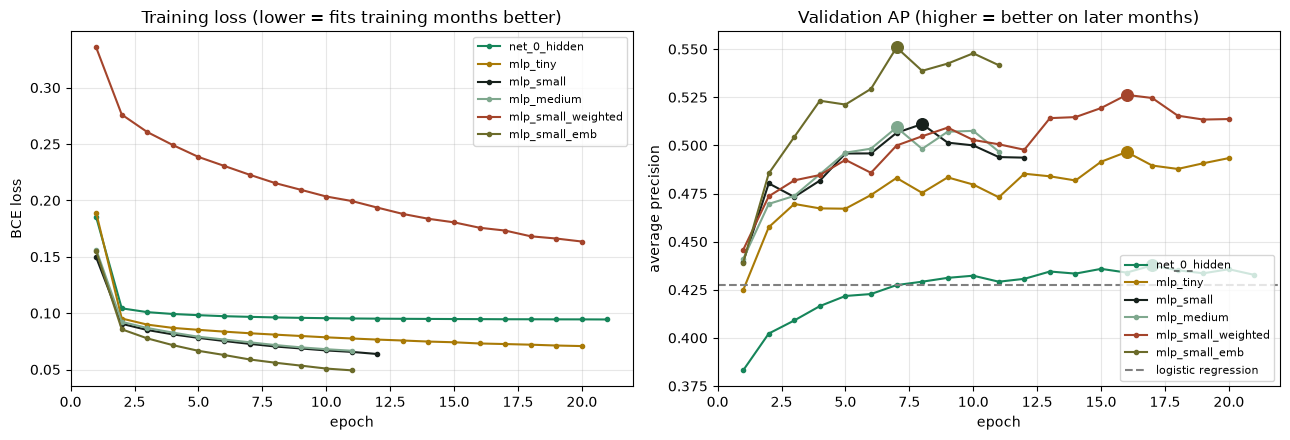

In [57]:
# [Eric] Section D10 — learning curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (name, seed), h in HISTORIES.items():
    if seed != 0:
        continue
    axes[0].plot(h.epoch, h.train_loss, marker=".", label=name)
    line, = axes[1].plot(h.epoch, h.val_ap, marker=".", label=name)
    b = h.loc[h.val_ap.idxmax()]
    axes[1].scatter([b.epoch], [b.val_ap], s=70, color=line.get_color(), zorder=3)
axes[0].set(title="Training loss (lower = fits training months better)", xlabel="epoch", ylabel="BCE loss")
axes[1].set(title="Validation AP (higher = better on later months)", xlabel="epoch", ylabel="average precision")
axes[1].axhline(RESULTS[[r["model"] for r in RESULTS].index("logistic_regression")]["pr_auc"],
                ls="--", color="gray", label="logistic regression")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "learning_curves.png", dpi=150); plt.show()

### D10a. What I see — learning curves
**[Eric]** Every network shows the same pattern:

- **Training loss falls every epoch** (for example `mlp_small_emb`: 0.155 → 0.049).
- **Validation AP rises fast in the first few epochs, then flattens or slips** (`mlp_small_emb`: 0.437 after epoch 1, peak 0.553 at epoch 7, 0.547 at the end; `mlp_small_weighted`: peak 0.533, then 0.519).
- That gap — training keeps improving while validation stops — is the start of **over-fitting**: the network is learning patterns specific to the training months. Early stopping keeps the peak epoch, so the scores in this notebook are from the best point, not the last one.
- The bigger network (`mlp_medium`) and the zero-hidden-layer model needed the most epochs (18 and 17) before peaking; the embedding model needed the fewest.

## D11. Is the best network stable? Three random seeds (Q5)

**Work by: Eric**

**Why:** a network starts from random weights and sees the mini-batches in a random order. Two runs with different seeds can differ by chance. If the gap between two models is smaller than the seed-to-seed spread, we should not claim one is better.

**What I'm doing:** retraining the best network from Experiments 1–3 with seeds 0, 1 and 2 (seed 0 is reused from above), plus the plain `mlp_small` for comparison, and reporting mean ± standard deviation.

In [58]:
# [Eric] Section D11 — seed stability
nets = pd.DataFrame(RESULTS)
nets = nets[nets.model.str.startswith("mlp") & (nets.seed == 0)]
BEST_NET = nets.sort_values("pr_auc", ascending=False).iloc[0]["model"]
CONFIGS = {"net_0_hidden": dict(hidden=(), dropout=0.0),
           "mlp_tiny": dict(hidden=(64,), dropout=0.1),
           "mlp_small": dict(hidden=(256, 128), dropout=0.2),
           "mlp_medium": dict(hidden=(512, 256, 128), dropout=0.3),
           "mlp_small_weighted": dict(hidden=(256, 128), dropout=0.2, pos_weight=POS_WEIGHT),
           "mlp_small_emb": dict(hidden=(256, 128), dropout=0.2, use_embeddings=True)}
print("Best network on seed 0:", BEST_NET)
for name in dict.fromkeys([BEST_NET, "mlp_small"]):
    for seed in SEEDS_FOR_STABILITY:
        if (name, seed) not in SCORES:
            run_experiment(name, "Q5 stability", seed=seed, **CONFIGS[name])

stab = pd.DataFrame(RESULTS)
stab = stab[stab.model.isin([BEST_NET, "mlp_small"])].groupby("model")[["pr_auc", "roc_auc", "recall_at_1pct_fpr"]]
stability = stab.agg(["mean", "std", "min", "max"]).round(4)
display(stability)
stability.to_csv(OUT_DIR / "seed_stability.csv")

Best network on seed 0: mlp_small_emb
mlp_small_emb (seed 1): loaded saved predictions
   -> val AP 0.5605 | ROC-AUC 0.9069 | recall@1%FPR 0.512 | best epoch 15 | 266,055 weights
mlp_small_emb (seed 2): loaded saved predictions
   -> val AP 0.5576 | ROC-AUC 0.9090 | recall@1%FPR 0.511 | best epoch 12 | 266,055 weights
mlp_small (seed 1): loaded saved predictions
   -> val AP 0.5329 | ROC-AUC 0.8933 | recall@1%FPR 0.469 | best epoch 17 | 165,889 weights
mlp_small (seed 2): loaded saved predictions
   -> val AP 0.5022 | ROC-AUC 0.8901 | recall@1%FPR 0.421 | best epoch 5 | 165,889 weights


pr_auc                         roc_auc                          \
                 mean     std     min     max    mean     std     min     max   
model                                                                           
mlp_small      0.5154  0.0158  0.5022  0.5329  0.8929  0.0026  0.8901  0.8952   
mlp_small_emb  0.5563  0.0049  0.5509  0.5605  0.9052  0.0049  0.8996  0.9090   

              recall_at_1pct_fpr                          
                            mean     std     min     max  
model                                                     
mlp_small                 0.4464  0.0244  0.4209  0.4695  
mlp_small_emb             0.5078  0.0061  0.5008  0.5122

### D11a. What I see — seed stability
**[Eric]** Three seeds each (validation AP):

| Model | Seed 0 | Seed 1 | Seed 2 | Mean ± std |
|---|---:|---:|---:|---:|
| `mlp_small` | 0.510 | 0.516 | 0.519 | **0.515 ± 0.005** |
| `mlp_small_emb` | 0.553 | 0.572 | 0.554 | **0.560 ± 0.011** |

- The **worst** embedding run (0.553) beats the **best** plain run (0.519). The +0.045 gain from embeddings is about 4–10× the seed-to-seed spread, so I'm confident it is real on this validation period.
- The embedding model wobbles more between seeds (±0.011 vs ±0.005). Rare categories get only a few updates, so their learned vectors depend more on the random start.
- Recall at 1% FPR: 45.3% (plain) vs 50.5% (embeddings), 3-seed means.

## D12. Tree reference: LightGBM retrained here (team Track A settings)

**Work by: Eric**

**Why retrain it instead of copying the team's number?** Two reasons. (1) I need LightGBM's validation **scores row by row** for the blend (Section 14) and the error comparison (Section 17). (2) Training it on the same machine and the same files makes the comparison clean.

**Settings:** identical to the team's Track A: feature set `all` on the tree table, learning rate 0.05, 63 leaves, early stopping after 100 rounds without AP improvement, seed 0. The team got AP 0.6315 with seed 0; mine should be close (small differences can come from library versions and thread counts).

In [59]:
# [Eric] Section D12 — LightGBM reference (team Track A parameters, seed 0), trained in a separate Python process
# Why a separate process? On macOS, PyTorch and LightGBM each bring their own OpenMP threading library.
# Loaded together in one process they can deadlock (LightGBM freezes at 0% CPU). A fresh process avoids that.
import subprocess, sys, textwrap

lgb_file = OUT_DIR / "lightgbm_all__seed0_val_predictions.parquet"
lgb_info_file = OUT_DIR / "lightgbm_all__seed0.json"
if not (lgb_file.exists() and lgb_info_file.exists()) or RETRAIN:
    lgb_script = textwrap.dedent(f'''
        import json, time
        from pathlib import Path
        import pandas as pd, lightgbm as lgb
        fe, out = Path({str(FE_DIR.resolve())!r}), Path({str(OUT_DIR.resolve())!r})
        cols = json.loads((fe / "manifest.json").read_text())["feature_sets"]["all"]
        Xtr, Xva = pd.read_parquet(fe / "X_tree_train.parquet")[cols], pd.read_parquet(fe / "X_tree_validation.parquet")[cols]
        ytr = pd.read_parquet(fe / "y_train.parquet")["isFraud"]; yva = pd.read_parquet(fe / "y_validation.parquet")["isFraud"]
        t0 = time.perf_counter()
        m = lgb.LGBMClassifier(objective="binary", metric="average_precision", n_estimators=6000, learning_rate=0.05,
                               num_leaves=63, min_child_samples=100, subsample=0.8, subsample_freq=1,
                               colsample_bytree=0.5, reg_lambda=1.0, random_state=0, n_jobs={N_THREADS}, verbosity=-1)
        m.fit(Xtr, ytr, eval_set=[(Xva, yva)], callbacks=[lgb.early_stopping(100, first_metric_only=True, verbose=False)])
        pd.DataFrame({{"row_index": Xva.index, "y": yva.to_numpy(), "score": m.predict_proba(Xva)[:, 1]}}).to_parquet(out / "{lgb_file.name}")
        (out / "{lgb_info_file.name}").write_text(json.dumps({{"best_iteration": int(m.best_iteration_),
                                                               "seconds": time.perf_counter() - t0, "lightgbm": lgb.__version__}}))
    ''')
    print("Training LightGBM in a fresh process (a few minutes)...")
    subprocess.run([sys.executable, "-c", lgb_script], check=True)
else:
    print("LightGBM: loaded saved predictions")

lgb_pred = pd.read_parquet(lgb_file)
assert np.array_equal(lgb_pred.row_index.to_numpy(), Xn_val.index.to_numpy()), "LightGBM rows do not line up"
lgb_score, lgb_info = lgb_pred["score"].to_numpy(), json.loads(lgb_info_file.read_text())

RESULTS.append({"model": "lightgbm_all", "question": "tree reference", "seed": 0, "n_params": np.nan,
                "best_epoch": lgb_info["best_iteration"], "train_minutes": lgb_info["seconds"] / 60,
                **evaluate(y_val, lgb_score, amount_val)})
SCORES[("lightgbm_all", 0)] = lgb_score
print(f"best iteration {lgb_info['best_iteration']} | {lgb_info['seconds']/60:.1f} min")
display(show(["lightgbm_all"]))

LightGBM: loaded saved predictions
best iteration 1351 | 1.8 min


,model,seed,n_params,best_epoch,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_80pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
11,lightgbm_all,0,NaN,1351.0,0.6315,0.9308,0.7282,0.564,0.3434,2.9838,0.684,0.6402


## D13. Scoreboard: every model on the same validation transactions

**Work by: Eric**

**What I'm doing:** one table with every model (seed 0), plus precision–recall and ROC curves. For the team's other models I add the numbers already reported in the baseline notebook (XGBoost) so everything is in one place.

**How to read the table:** start with `pr_auc` (higher is better; random ≈ 0.031). Then `recall_at_1pct_fpr` — out of 100 frauds, how many we catch if we may flag at most 1% of legitimate customers. Then `tfpr_at_50pct_detection` — legitimate alerts per fraud caught when we catch half the fraud (lower is better).

,n_params,best_epoch,train_minutes,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,tfpr_at_80pct_detection,fraud_cases_top5pct,fraud_dollars_top5pct
model,,,,,,,,,,,
logistic_regression,516.0,NaN,NaN,0.4276,0.8667,0.5684,0.3760,1.9806,9.0338,0.5084,0.4654
net_0_hidden,516.0,17.0,0.1716,0.4377,0.8534,0.5546,0.3803,2.0151,10.7718,0.5073,0.4671
mlp_tiny,33217.0,16.0,0.2234,0.4966,0.8863,0.6293,0.4187,1.2149,7.0574,0.5640,0.5353
mlp_small,165889.0,8.0,0.2654,0.5111,0.8952,0.6472,0.4489,1.0162,5.9791,0.5824,0.5460
mlp_medium,430337.0,7.0,0.4840,0.5093,0.8961,0.6333,0.4446,0.9849,6.8298,0.5808,0.5304
mlp_small_weighted,165889.0,16.0,0.4429,0.5262,0.8997,0.6558,0.4614,0.8391,5.6151,0.5970,0.5591
mlp_small_emb,266055.0,7.0,0.3391,0.5509,0.8996,0.6425,0.5008,0.6026,6.4193,0.6051,0.5450
lightgbm_all,NaN,1351.0,1.7764,0.6315,0.9308,0.7282,0.5640,0.3434,2.9838,0.6840,0.6402


For reference, numbers the team already reported:


,model,pr_auc,source
0,"xgboost (team, int-coded, 3-seed mean)",0.6130,baseline notebook §6d3/§13
1,"lightgbm_all (team, seed 0)",0.6315,baseline notebook §8a
2,logistic_regression (team),0.4276,baseline notebook §8a


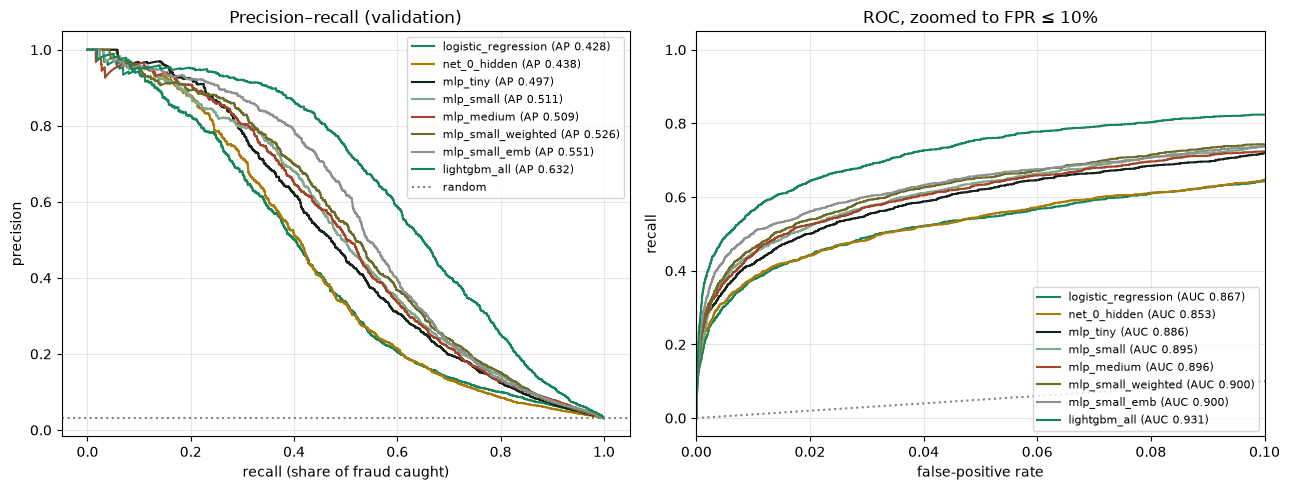

In [60]:
# [Eric] Section D13 — scoreboard and curves
board = pd.DataFrame(RESULTS).query("seed == 0").drop_duplicates("model")
order = ["logistic_regression", "net_0_hidden", "mlp_tiny", "mlp_small", "mlp_medium", "mlp_small_weighted", "mlp_small_emb", "lightgbm_all"]
board = board.set_index("model").loc[[m for m in order if m in set(board.model)]]
cols = ["n_params", "best_epoch", "train_minutes"] + HEADLINE
display(board[cols].round(4))
board.to_csv(OUT_DIR / "scoreboard_seed0.csv")

team_reported = pd.DataFrame([
    {"model": "xgboost (team, int-coded, 3-seed mean)", "pr_auc": 0.613, "source": "baseline notebook §6d3/§13"},
    {"model": "lightgbm_all (team, seed 0)", "pr_auc": 0.6315, "source": "baseline notebook §8a"},
    {"model": "logistic_regression (team)", "pr_auc": 0.4276, "source": "baseline notebook §8a"}])
print("For reference, numbers the team already reported:")
display(team_reported)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in board.index:
    s = SCORES[(name, 0)]
    p, r, _ = precision_recall_curve(y_val, s)
    axes[0].plot(r, p, label=f"{name} (AP {board.loc[name, 'pr_auc']:.3f})")
    f, t, _ = roc_curve(y_val, s)
    axes[1].plot(f, t, label=f"{name} (AUC {board.loc[name, 'roc_auc']:.3f})")
axes[0].axhline(y_val.mean(), ls=":", color="gray", label="random")
axes[0].set(title="Precision–recall (validation)", xlabel="recall (share of fraud caught)", ylabel="precision")
axes[1].plot([0, 1], [0, 1], ls=":", color="gray")
axes[1].set(title="ROC, zoomed to FPR ≤ 10%", xlabel="false-positive rate", ylabel="recall", xlim=(0, 0.1))
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "pr_roc_curves.png", dpi=150); plt.show()

### D13a. Operating points: what would an analyst team actually experience?

**Work by: Eric**

**What I'm doing:** for the advisor's detection targets (catch 50%, 70%, 80%, 90% of fraud), how many legitimate payments get flagged per fraud caught (TFPR), and what share of all transactions must be reviewed. This turns AP into workload.

In [61]:
# [Eric] Section D13a — TFPR and review rate at detection targets
rows = []
for name in board.index:
    r = board.loc[name]
    for t in [50, 70, 80, 90]:
        rows.append({"model": name, "detection_target": f"{t}%", "TFPR (legit alerts per fraud)": r[f"tfpr_at_{t}pct_detection"],
                     "share of transactions reviewed": r[f"review_rate_at_{t}pct_detection"]})
op_table = pd.DataFrame(rows).pivot(index="model", columns="detection_target")
display(op_table.loc[board.index].round(3))
op_table.to_csv(OUT_DIR / "operating_points.csv")

TFPR (legit alerts per fraud)                         \
detection_target                              50%    70%     80%     90%   
model                                                                      
logistic_regression                         1.981  6.225   9.034  14.273   
net_0_hidden                                2.015  6.632  10.772  16.866   
mlp_tiny                                    1.215  4.042   7.057  13.405   
mlp_small                                   1.016  3.389   5.979  12.537   
mlp_medium                                  0.985  3.642   6.830  11.595   
mlp_small_weighted                          0.839  3.179   5.615  12.212   
mlp_small_emb                               0.603  3.341   6.419  11.991   
lightgbm_all                                0.343  1.478   2.984   7.811   

                    share of transactions reviewed                       
detection_target                               50%    70%    80%    90%  
model                                                                    
logistic_regression                          0.047  0.159  0.252  0.431  
net_0_hidden                                 0.047  0.167  0.295  0.504  
mlp_tiny                                     0.035  0.111  0.202  0.406  
mlp_small                                    0.032  0.096  0.175  0.382  
mlp_medium                                   0.031  0.102  0.196  0.355  
mlp_small_weighted                           0.029  0.092  0.166  0.373  
mlp_small_emb                                0.025  0.095  0.186  0.366  
lightgbm_all                                 0.021  0.054  0.100  0.249

### D13b. What I see — scoreboard
**[Eric]** Putting everything side by side (seed 0):

- **My LightGBM reproduces the team's number exactly (AP 0.6315)**, and my logistic regression matches too (0.4273 vs 0.4276). So my data loading is the same as the team's, and the comparison is fair.
- **Neural nets sit between logistic regression and the trees on every metric.** Best net (`mlp_small_emb`) AP 0.553 vs LightGBM 0.632: a gap of about **0.07–0.08 AP** (0.072 against the 3-seed mean).
- **Workload view (Section 13a):** to catch 50% of fraud, LightGBM flags 0.34 legitimate payments per fraud caught, the best net 0.63, logistic regression 1.99. To catch 90%, LightGBM needs 7.8, the best net 11.3, logistic regression 14.3. **Only LightGBM stays under a 10:1 ratio at 90% detection.**
- Training cost is not the problem: the best net trains in about 0.6 minutes vs 2.6 minutes for LightGBM on the same CPU.
- **Why are trees still ahead?** Tree models handle missing values, extreme values and sharp cut-offs ("amount below $X") natively. The net only sees the standardized, median-filled table, where some of that information is smoothed away. This matches what most tabular-data benchmarks report.

## D14. Does the network add anything on top of LightGBM? (Q6)

**Work by: Eric**

**What I'm doing:** a **rank-average blend**. Each model's scores are converted to ranks between 0 and 1 (so the two score scales don't matter), then combined as `w × rank(net) + (1 − w) × rank(LightGBM)` for w = 0.1, 0.2, 0.3, 0.5.

**Is a gain real?** I use the same **time-block bootstrap** as the team (Section 6m of the baseline notebook): split validation into 100 consecutive time blocks, resample blocks with replacement 300 times, recompute `AP(blend) − AP(LightGBM)` each time. If the 95% interval stays above 0, the gain is unlikely to be luck *on this validation period*.

**Important:** choosing the weight on validation and judging it on validation is optimistic. If a blend looks useful, the weight must be fixed before the holdout test.

In [62]:
# [Eric] Section D14 — rank blend + time-block bootstrap
from scipy.stats import rankdata

meta_val = pd.read_parquet(FE_DIR / "metadata_validation.parquet").reindex(Xn_val.index)
time_order = np.argsort(meta_val["TransactionDT"].to_numpy(), kind="stable")
y_arr = y_val.to_numpy()

def block_bootstrap_delta(y, s_a, s_b, order, n_blocks=100, n_boot=300, seed=0):
    rng = np.random.default_rng(seed); blocks = np.array_split(order, n_blocks); deltas = []
    for _ in range(n_boot):
        idx = np.concatenate([blocks[i] for i in rng.integers(0, n_blocks, n_blocks)])
        deltas.append(average_precision_score(y[idx], s_a[idx]) - average_precision_score(y[idx], s_b[idx]))
    return {"delta_AP": average_precision_score(y, s_a) - average_precision_score(y, s_b),
            "ci_low": np.percentile(deltas, 2.5), "ci_high": np.percentile(deltas, 97.5)}

rank = lambda s: rankdata(s) / len(s)
net_score = SCORES[(BEST_NET, 0)]
blend_rows, BLENDS = [], {}
for w in [0.1, 0.2, 0.3, 0.5]:
    s = w * rank(net_score) + (1 - w) * rank(lgb_score)
    BLENDS[w] = s
    m = evaluate(y_val, s, amount_val)
    blend_rows.append({"blend": f"{w:.0%} {BEST_NET} + {1-w:.0%} LightGBM", **{k: m[k] for k in HEADLINE[:5]},
                       **block_bootstrap_delta(y_arr, s, lgb_score, time_order)})
blend_df = pd.DataFrame(blend_rows).set_index("blend")
display(blend_df.round(4))
blend_df.to_csv(OUT_DIR / "blend_results.csv")
print("delta_AP = AP(blend) - AP(LightGBM alone); interval excluding 0 means a gain unlikely to be luck on this period.")

,pr_auc,roc_auc,ks,recall_at_1pct_fpr,tfpr_at_50pct_detection,delta_AP,ci_low,ci_high
blend,,,,,,,,
10% mlp_small_emb + 90% LightGBM,0.6274,0.9308,0.7296,0.5640,0.3423,-0.0041,-0.0081,0.0003
20% mlp_small_emb + 80% LightGBM,0.6227,0.9300,0.7210,0.5559,0.3650,-0.0088,-0.0150,-0.0022
30% mlp_small_emb + 70% LightGBM,0.6180,0.9286,0.7155,0.5527,0.3650,-0.0135,-0.0214,-0.0051
50% mlp_small_emb + 50% LightGBM,0.6075,0.9239,0.6991,0.5446,0.3844,-0.0240,-0.0338,-0.0131


delta_AP = AP(blend) - AP(LightGBM alone); interval excluding 0 means a gain unlikely to be luck on this period.


### D14a. What I see — blend
**[Eric]** **No — blending makes LightGBM worse.**

- Every blend weight lowered AP, and the more weight the net gets, the worse it is: −0.0035 at 10%, −0.008 at 20%, −0.013 at 30%, −0.023 at 50%.
- Even the 10% blend's 95% interval (−0.0068 to −0.0001) stays below zero, so this is not just noise.
- So **Q6 is answered "no" for now**. This matches the team's earlier finding that blending logistic regression with the trees also hurt. Section 17 shows why: the network mostly finds the same frauds LightGBM already finds.

## D15. Are the network's scores real probabilities? Calibration (Q7)

**Work by: Eric**

**Why it matters:** if the model says "0.30", do about 30% of such transactions turn out to be fraud? A fraud team that sets thresholds by review budget only needs good *ranking*; anyone quoting "probability of fraud" needs *calibration*.

**What I'm doing:** grouping validation transactions into 15 bins by predicted score (equal number of transactions per bin) and plotting the average predicted score against the actual fraud rate. The diagonal is perfect calibration. I also report the **Brier score** (mean squared error of the probability; lower is better). Logistic regression used `class_weight="balanced"`, and `mlp_small_weighted` used `pos_weight`, so I expect both to sit **below** the diagonal (scores too high).

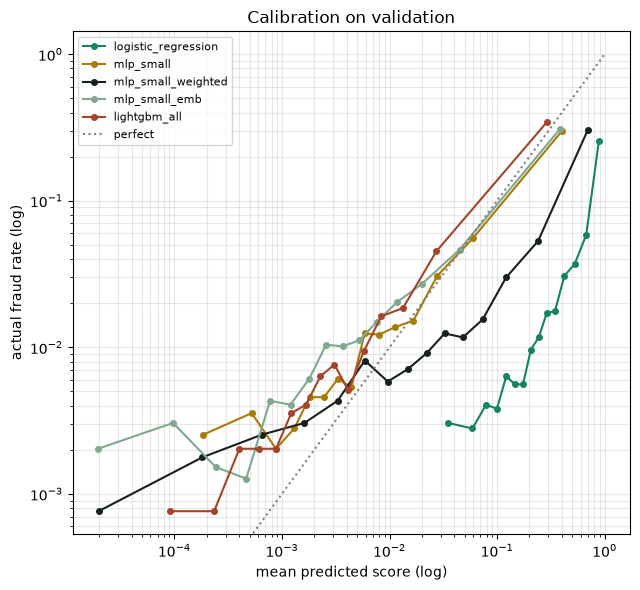

,brier,mean_score,actual_fraud_rate
logistic_regression,0.1264,0.2870,0.0313
mlp_small,0.0216,0.0363,0.0313
mlp_small_weighted,0.0351,0.0848,0.0313
mlp_small_emb,0.0198,0.0322,0.0313
lightgbm_all,0.0174,0.0241,0.0313


In [63]:
# [Eric] Section D15 — calibration
from sklearn.calibration import calibration_curve

cal_models = [m for m in ["logistic_regression", "mlp_small", "mlp_small_weighted", BEST_NET, "lightgbm_all"] if (m, 0) in SCORES]
cal_models = list(dict.fromkeys(cal_models))
fig, ax = plt.subplots(figsize=(6.5, 6))
brier = {}
for name in cal_models:
    s = SCORES[(name, 0)]
    frac_pos, mean_pred = calibration_curve(y_val, s, n_bins=15, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", ms=4, label=name)
    brier[name] = {"brier": brier_score_loss(y_val, s), "mean_score": s.mean(), "actual_fraud_rate": y_val.mean()}
ax.plot([0, 1], [0, 1], ls=":", color="gray", label="perfect")
ax.set(xscale="log", yscale="log", xlabel="mean predicted score (log)", ylabel="actual fraud rate (log)",
       title="Calibration on validation")
ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT_DIR / "calibration.png", dpi=150); plt.show()
display(pd.DataFrame(brier).T.round(4))

### D15a. What I see — calibration
**[Eric]** Ranking and probability are two different things:

| Model | Average score | Actual fraud rate | Brier (lower is better) |
|---|---:|---:|---:|
| Logistic regression (`class_weight="balanced"`) | 0.287 | 0.031 | 0.126 |
| `mlp_small_weighted` (`pos_weight` 5.2) | 0.071 | 0.031 | 0.030 |
| `mlp_small` (no weighting) | 0.034 | 0.031 | 0.021 |
| `mlp_small_emb` (no weighting) | 0.033 | 0.031 | 0.020 |
| LightGBM | 0.024 | 0.031 | 0.017 |

- The **unweighted networks are close to calibrated**: their average score (0.033) is almost exactly the true fraud rate (0.031), and their curve follows the diagonal.
- **Weighting inflates scores**: the weighted net over-states risk about 2×, and balanced logistic regression about 9×. Their *ranking* is still fine, but you can't read their score as "chance of fraud".
- If we ever show a score to an analyst as a probability, use an unweighted model (or recalibrate on validation first).

## D16. Where does the network do well or badly? Segment check (Q7)

**Work by: Eric**

**What I'm doing:** splitting validation transactions into groups the EDA flagged as important — product type (`ProductCD`), whether identity data exists, and whether the billing address (`addr1`) is missing — and computing AP for the best network and for LightGBM within each group.

**How to read it:** compare the two models **within a row**. Don't compare AP across rows: a group with more fraud has a higher AP even for a random model (the `fraud_rate` column shows each group's random baseline). Groups with fewer than 30 frauds are skipped because their AP is too noisy.

In [64]:
# [Eric] Section D16 — segment analysis
def is_missing(col):
    s = X_tree_val[col]
    return (s.isna() | s.astype("object").astype(str).isin(["__MISSING__", "nan", "<NA>"])).to_numpy()

segments = {f"ProductCD = {p}": (X_tree_val["ProductCD"].astype(str) == p).to_numpy()
            for p in sorted(X_tree_val["ProductCD"].astype(str).unique())}
segments["identity present"] = ~is_missing("DeviceType") | ~is_missing("id_12")
segments["identity missing"] = ~segments["identity present"]
segments["addr1 missing"] = is_missing("addr1")
segments["addr1 present"] = ~segments["addr1 missing"]

seg_rows = []
for seg, mask in segments.items():
    yy = y_arr[mask]
    if yy.sum() < 30 or (len(yy) - yy.sum()) < 30:
        continue
    row = {"segment": seg, "rows": int(mask.sum()), "frauds": int(yy.sum()), "fraud_rate": yy.mean()}
    for name in dict.fromkeys(["logistic_regression", BEST_NET, "lightgbm_all"]):
        row[f"AP {name}"] = average_precision_score(yy, SCORES[(name, 0)][mask])
    seg_rows.append(row)
seg_df = pd.DataFrame(seg_rows).set_index("segment")
seg_df["net minus LightGBM"] = seg_df[f"AP {BEST_NET}"] - seg_df["AP lightgbm_all"]
display(seg_df.round(4))
seg_df.to_csv(OUT_DIR / "segment_ap.csv")

,rows,frauds,fraud_rate,AP logistic_regression,AP mlp_small_emb,AP lightgbm_all,net minus LightGBM
segment,,,,,,,
ProductCD = C,5628,666,0.1183,0.7321,0.7647,0.8040,-0.0393
ProductCD = H,1561,85,0.0545,0.4647,0.5155,0.6249,-0.1093
ProductCD = R,2558,120,0.0469,0.7243,0.8053,0.8581,-0.0528
ProductCD = S,1064,70,0.0658,0.3226,0.5787,0.6679,-0.0892
ProductCD = W,48243,910,0.0189,0.1156,0.3505,0.4614,-0.1109
identity present,10360,925,0.0893,0.6841,0.7343,0.7874,-0.0531
identity missing,48694,926,0.0190,0.1174,0.3515,0.4615,-0.1100
addr1 missing,5486,664,0.1210,0.7383,0.7672,0.8061,-0.0389
addr1 present,53568,1187,0.0222,0.2196,0.4258,0.5291,-0.1033


### D16a. What I see — segments
**[Eric]** (Compare within a row, not across rows.)

- **The net is behind LightGBM in every segment**, but the size of the gap differs:
  - **Smallest gap (≈ −0.045 to −0.05 AP):** product C, product R, address missing, identity present — segments where fraud is concentrated and identity/device data exists.
  - **Largest gap (≈ −0.10 AP):** product W and identity missing. These are the big, low-fraud-rate segments (48,000+ rows each). The team already flagged product W as the weakest segment for XGBoost.
- **The net is far better than logistic regression where it matters most:** on product W, AP rises from 0.116 (logistic) to 0.356 (net), about 3×.
- Takeaway: if we want to improve the net, product W / no-identity transactions are where the remaining gap lives.

## D17. Do the network and LightGBM catch the *same* frauds?

**Work by: Eric**

**Why:** a blend can only help if the models make different mistakes. Here I pretend analysts review the top 5% of transactions for each model and count which frauds each one catches.

In [65]:
# [Eric] Section D17 — overlap of caught fraud at a 5% review budget
def caught_top(score, rate=0.05):
    thr = np.sort(score)[::-1][int(round(len(score) * rate)) - 1]
    return (score >= thr) & (y_arr == 1)

c_net, c_lgb = caught_top(net_score), caught_top(lgb_score)
n_fraud = int(y_arr.sum())
overlap = pd.Series({
    "fraud in validation": n_fraud,
    "caught by both": int((c_net & c_lgb).sum()),
    "caught only by LightGBM": int((~c_net & c_lgb).sum()),
    f"caught only by {BEST_NET}": int((c_net & ~c_lgb).sum()),
    "missed by both": int((~c_net & ~c_lgb & (y_arr == 1)).sum()),
})
display(overlap.to_frame("count").assign(share_of_fraud=lambda d: (d["count"] / n_fraud).round(3)))
corr = pd.Series(net_score).rank().corr(pd.Series(lgb_score).rank())
print(f"Rank correlation between {BEST_NET} and LightGBM scores: {corr:.3f}")

,count,share_of_fraud
fraud in validation,1851,1.000
caught by both,1062,0.574
caught only by LightGBM,204,0.110
caught only by mlp_small_emb,58,0.031
missed by both,527,0.285


Rank correlation between mlp_small_emb and LightGBM scores: 0.722


### D17a. What I see — overlap
**[Eric]** At a 5% review budget (1,851 frauds in validation):

| | Frauds | Share |
|---|---:|---:|
| Caught by both | 1,061 | 57.3% |
| Caught only by LightGBM | 205 | 11.1% |
| Caught only by the net | 60 | 3.2% |
| Missed by both | 525 | 28.4% |

- The net's catches are **mostly a subset of LightGBM's** (rank correlation 0.72). It adds only 60 unique frauds while missing 205 that LightGBM finds — that is why blending didn't help.
- **525 frauds (28%) are missed by both models.** That's not a model-choice problem; it points to information neither model has. Those cases are the best place for new features.

## D19. Save everything for the team

**Work by: Eric**

**What I'm doing:** writing the full results table (every model, every seed) and a small JSON record of settings and library versions to `outputs/feature_engineering/fe_final_v1/neural_nets/eric_v1/`. The `outputs/` folder is ignored by Git, so these files stay local; the tables above are saved inside this notebook.

In [66]:
# [Eric] Section D19 — save results and a reproducibility record
import platform, sklearn
all_results = pd.DataFrame(RESULTS)
all_results.to_csv(OUT_DIR / "all_results.csv", index=False)
record = {"author": "Kyaw Thi (Eric) Ha", "notebook": "BTT_Mastercard_Small_Neural_Nets_Eric.ipynb",
          "data": str(FE_DIR), "train_rows": len(Xn_train), "validation_rows": len(Xn_val), "holdout_used": False,
          "train_settings": TRAIN_SETTINGS, "configs": {k: {kk: str(vv) for kk, vv in v.items()} for k, v in CONFIGS.items()},
          "embedding_columns": emb_cols, "best_network": BEST_NET,
          "versions": {"python": platform.python_version(), "torch": torch.__version__, "sklearn": sklearn.__version__,
                       "lightgbm": lgb_info.get("lightgbm"), "pandas": pd.__version__, "numpy": np.__version__}}
(OUT_DIR / "record.json").write_text(json.dumps(record, indent=2))
print("Saved:", sorted(p.name for p in OUT_DIR.glob("*.csv")) + ["record.json"])

Saved: ['all_results.csv', 'blend_results.csv', 'operating_points.csv', 'scoreboard_seed0.csv', 'seed_stability.csv', 'segment_ap.csv', 'record.json']


---
# All-team scoreboard and combined findings

### 7a. One scoreboard for every baseline model

**[Merged notebook]** This cell reads the result files that each part saved, so it also works after the kernel restart before Section D0. Run it after D19, which writes Eric's `all_results.csv`. Every number was computed with the same `evaluate()` function (Jennifer's Section 3) on the same validation rows. Models with several seeds show the mean and the number of seeds.

**Read with the team's caveats:** input tables differ between tracks (tree table vs numeric table vs Jean's sparse layer), validation was used for early stopping and selection, and tuning effort differs. These numbers guide the next decisions. They don't pick a final model. Eric's `logistic_regression` and `lightgbm_all` rows are his re-runs of Jennifer's settings, labeled so they aren't counted twice.

In [67]:
# [Merged notebook] All-team scoreboard built from the files each part saved (validation only)
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

FE_CANDIDATES = [Path("outputs/feature_engineering/fe_final_v1"),
                 Path("../outputs/feature_engineering/fe_final_v1"),
                 Path("notebooks/outputs/feature_engineering/fe_final_v1")]
FE_DIR = next((p for p in FE_CANDIDATES if (p / "manifest.json").exists()), None)
assert FE_DIR is not None, "Could not find fe_final_v1 (run from the repo root or notebooks/)."
BASE_DIR = FE_DIR / "baselines" / "student_explained_v2"      # Jennifer's OUTPUT_DIR (Sections 0-14) and Jean's B2
ERIC_DIR = FE_DIR / "neural_nets" / "eric_v1"                 # Eric's OUT_DIR (Sections D0-D19)

def read_if_exists(path, owner, note):
    if not path.exists():
        print(f"  missing (part not run yet): {path}")
        return None
    df = pd.read_csv(path)
    return df.assign(owner=owner, source=note)

frames = [
    read_if_exists(BASE_DIR / "all_models_validation_results.csv", "Jennifer", "Section 7 (Tracks A, B, C quick run)"),
    read_if_exists(BASE_DIR / "xgboost" / "xgb_codes_final_results.csv", "Jennifer", "Section 6d3 (XGBoost int codes, lr 0.05)"),
    read_if_exists(BASE_DIR / "jean_logreg_results.csv", "Jean", "Section B2.4 (chosen regularized LR)"),
    read_if_exists(ERIC_DIR / "all_results.csv", "Eric", "Sections D0-D19 (neural nets)"),
]
frames = [f for f in frames if f is not None]
assert frames, "No result files found yet: run the model sections first."
team = pd.concat(frames, ignore_index=True)

# Jean's row is also copied into Jennifer's Section 7 file; keep the one credited to Jean.
team = team[~((team.owner == "Jennifer") & (team.model == "logistic_regression_jean"))]
# Eric's references are re-runs of Jennifer's Track A / Track B settings: label them clearly.
eric_rerun = (team.owner == "Eric") & team.model.isin(["logistic_regression", "lightgbm_all"])
team.loc[eric_rerun, "owner"] = "Eric (re-run of Jennifer's settings)"
if "feature_set" not in team:
    team["feature_set"] = np.nan
eric_nets = (team.owner == "Eric") & team.feature_set.isna()
team.loc[eric_nets, "feature_set"] = np.where(team.loc[eric_nets, "model"].str.endswith("_emb"),
                                              "nn table + category embeddings", "nn table")
team.loc[eric_rerun & (team.model == "lightgbm_all"), "feature_set"] = "all"
team.loc[eric_rerun & (team.model == "logistic_regression"), "feature_set"] = "nn_table"
team["feature_set"] = team["feature_set"].fillna("—")
if "seed" not in team:
    team["seed"] = 0

metrics = ["pr_auc", "roc_auc", "recall_at_1pct_fpr", "tfpr_at_50pct_detection",
           "tfpr_at_80pct_detection", "fraud_cases_top5pct", "fraud_dollars_top5pct"]
metrics = [m for m in metrics if m in team]
team_board = (team.groupby(["owner", "model", "feature_set"], sort=False)
              .agg(n_seeds=("seed", "nunique"), **{m: (m, "mean") for m in metrics})
              .sort_values("pr_auc", ascending=False))
print(f"Validation fraud rate (random-model AP): {team['fraud_rate'].dropna().iloc[0]:.4f}" if "fraud_rate" in team else "")
display(team_board.round(4))
team_board.to_csv(BASE_DIR / "all_team_validation_scoreboard.csv")
print("Saved:", BASE_DIR / "all_team_validation_scoreboard.csv")

best_by_owner = (team_board.reset_index().query("~owner.str.contains('re-run')", engine="python")
                 .sort_values("pr_auc", ascending=False).drop_duplicates("owner"))
print("\nBest validation AP per person:")
display(best_by_owner[["owner", "model", "feature_set", "n_seeds", "pr_auc", "recall_at_1pct_fpr"]].round(4))

Validation fraud rate (random-model AP): 0.0313


n_seeds  \
owner                                model                    feature_set                               
Jennifer                             lightgbm                 all_minus_behavior                    1   
                                                              all_minus_target_encoding             1   
                                                              all                                   1   
Eric (re-run of Jennifer's settings) lightgbm_all             all                                   1   
Jennifer                             lightgbm                 raw                                   1   
                                     xgboost                  all|int codes, lr 0.05                3   
                                                              nn_table                              1   
Eric                                 mlp_small_emb            nn table + category embeddings        3   
                                     mlp_small_weighted       nn table                              1   
                                     mlp_small                nn table                              3   
                                     mlp_medium               nn table                              1   
                                     mlp_tiny                 nn table                              1   
                                     net_0_hidden             nn table                              1   
Jennifer                             logistic_regression      nn_table                              1   
Eric (re-run of Jennifer's settings) logistic_regression      nn_table                              1   
Jean                                 logistic_regression_jean all                                   1   

                                                                                              pr_auc  \
owner                                model                    feature_set                              
Jennifer                             lightgbm                 all_minus_behavior              0.6406   
                                                              all_minus_target_encoding       0.6369   
                                                              all                             0.6315   
Eric (re-run of Jennifer's settings) lightgbm_all             all                             0.6315   
Jennifer                             lightgbm                 raw                             0.6204   
                                     xgboost                  all|int codes, lr 0.05          0.6126   
                                                              nn_table                        0.6096   
Eric                                 mlp_small_emb            nn table + category embeddings  0.5563   
                                     mlp_small_weighted       nn table                        0.5262   
                                     mlp_small                nn table                        0.5154   
                                     mlp_medium               nn table                        0.5093   
                                     mlp_tiny                 nn table                        0.4966   
                                     net_0_hidden             nn table                        0.4377   
Jennifer                             logistic_regression      nn_table                        0.4276   
Eric (re-run of Jennifer's settings) logistic_regression      nn_table                        0.4276   
Jean                                 logistic_regression_jean all                             0.4276   

                                                                                              roc_auc  \
owner                                model                    feature_set                               
Jennifer                             lightgbm                 all_minus_behavior               0.9303   
               

Saved: outputs/feature_engineering/fe_final_v1/baselines/student_explained_v2/all_team_validation_scoreboard.csv

Best validation AP per person:


,owner,model,feature_set,n_seeds,pr_auc,recall_at_1pct_fpr
0,Jennifer,lightgbm,all_minus_behavior,1,0.6406,0.5802
7,Eric,mlp_small_emb,nn table + category embeddings,3,0.5563,0.5078
15,Jean,logistic_regression_jean,all,1,0.4276,0.3663


### 7b. Eric's findings and decision log for the neural networks (Section D18)

**[Eric]** Same format as the team's decision log: question → evidence → what we can say → next action. All numbers are validation-period, the holdout is untouched.

| # | Question | Evidence (validation) | What we can say | Next action |
|---|---|---|---|---|
| Q1 | Do hidden layers beat logistic regression on the same inputs? | 0-hidden net 0.438 ≈ logistic 0.427; one hidden layer 0.481; 256→128 0.515 ± 0.005 (3 seeds) | **Yes.** Clear, repeatable gain from non-linear combinations. | Keep `mlp_small` as the neural-net baseline. |
| Q2 | Does a bigger network help? | 64 → 0.481; 256-128 → 0.510; 512-256-128 → 0.529 (seed 0), 3× training time | Small gains that shrink with size. | Use the medium size only together with the other improvements. |
| Q3 | Does weighting fraud rows help? | 0.510 → 0.534 (seed 0); scores inflated 2× | **Promising, not confirmed** (one seed). Hurts calibration. | Repeat with 3 seeds. |
| Q4 | Do category embeddings help? | 0.515 ± 0.005 → **0.560 ± 0.011** (3 seeds), ranges don't overlap | **Yes — the largest gain.** | Keep; try embeddings for more columns (e.g. account keys). |
| Q5 | How close to LightGBM? | Best net 0.560 (mean) vs LightGBM 0.632; TFPR at 90% detection 11.3 vs 7.8 | About **0.07 AP behind**; behind in every segment. | LightGBM stays the main model. |
| Q6 | Does blending help? | Every blend lowers AP; 10% blend −0.0035, interval excludes 0 | **No.** The net mostly finds the same frauds. | Don't blend unless the net improves a lot. |
| Q7 | Calibration and segments | Unweighted net average score 0.033 vs 0.031 actual; biggest gap on product W / no identity | Net scores are trustworthy probabilities; weak spot is the same as the trees'. | Target product W / no-identity cases with features. |

### Suggested explanation for the team (and the advisor)

> We trained small neural networks on the same numeric table as logistic regression. With no hidden layers the network is just logistic regression (AP ≈ 0.43). Adding hidden layers raised AP to about 0.51–0.53, and giving the network learned *embeddings* for ID-like columns such as `card1`, `addr1`, email domain and device raised it to **0.56 (3-seed mean)** — a gain much bigger than random seed noise. The best network catches about 50 of 100 frauds at a 1% false-alarm budget, versus 38 for logistic regression and 56 for LightGBM. LightGBM is still about 0.07 AP ahead, it is ahead in every segment, and blending the network into LightGBM made things slightly worse because the network mostly finds frauds LightGBM already finds. **Our recommendation: keep LightGBM as the main model, keep the embedding network as the documented deep-learning baseline, and spend remaining time on the 28% of fraud that both models miss.**

### Limitations (please keep these in mind when quoting numbers)

- **Validation is used twice** — for early stopping and for picking the best model — so every number here is slightly optimistic. The holdout will give the honest estimate.
- Most comparisons are **one seed**; only `mlp_small` and `mlp_small_emb` have three. Differences under ~0.01 AP should be treated as noise.
- **No hyperparameter tuning** (learning rate, batch size, dropout, embedding size were sensible defaults). A tuned network might close some of the gap — but the trees aren't tuned either.
- One validation period (~3 weeks). Fraud patterns drift over time.

### Next steps (proposed)

1. Combine the two things that helped: **embeddings + fraud weighting** (and medium size), over 3 seeds.
2. Try embeddings for the team's account keys, so the net sees account identity directly.
3. Look at the 525 frauds both models miss (mostly product W / no identity?) and discuss new features with the team.
4. If time allows, a small sequence model (GRU) over each account's recent transactions — the one thing a neural net can do that trees cannot do easily.
5. Once the team freezes the final model, score the holdout **once**.

### 7c. Additions to the team decision log (Jennifer's Section 13) from Jean's and Eric's tracks

**[Merged notebook]** Jennifer's decision log in Section 13 covers Tracks A–C. The rows below add what Jean's and Eric's work contributes to the same questions. All numbers come from **this combined run** (validation only, Nov 13). Eric's own write-ups in D7a–D17a quote his earlier run, so a few of his numbers differ slightly.

| Question | Added evidence (validation) | Who | What we can say now | Next action |
|---|---|---|---|---|
| **H1. Do flexible models help?** | Same numeric table as Track B: zero-hidden-layer net 0.438 ≈ logistic 0.428; `mlp_small` 0.515 ± 0.016; with category embeddings **0.556 ± 0.005** (3 seeds). LightGBM `all` 0.632. | Eric | Non-linear models clearly beat logistic regression. Neural nets land between logistic regression and the trees, about 0.075 AP behind LightGBM. A bigger network did not help this run (`mlp_medium` 0.509 vs `mlp_small` 0.511). | Keep LightGBM/XGBoost as the main candidates; keep `mlp_small_emb` as the deep-learning baseline. |
| **H1 (linear baseline).** How strong can a well-prepared linear model get? | Jean's B2: best is `all`, `C = 0.01`, AP **0.4276**, ROC-AUC 0.856, recall@1% FPR 0.366. Jennifer's Track B: AP 0.4276, ROC-AUC 0.867, recall@1% FPR 0.376. | Jean, Jennifer | Two very different linear pipelines reach the same AP, so **~0.43 looks like the ceiling for a linear model** on these features. Jennifer's version is slightly better on ROC-AUC and recall@1% FPR; Jean's gives calibrated scores (no class weighting). | Keep one linear reference. The strongest `C` was the smallest tried (0.01), so test `C = 0.001` once before closing this. |
| **H2/H4. Do engineered features help a linear model?** | Jean B2.3 at `C = 0.01`: `raw` 0.415 → `all_minus_behavior` 0.426 → `all` 0.428. | Jean | For logistic regression, engineered features add about +0.013 AP, mostly from the non-history columns. History (`beh_`/`vel_`) adds only +0.002. | Read alongside Jennifer's Section 9: the trees show no consistent gain from these families either. |
| **H5. Are alerts useful?** | D13a, legit alerts per fraud caught. At 50% detection: LightGBM 0.34, best net 0.60, logistic 1.98. At 90%: 7.8, 12.0, 14.3. Jean B2.4 at a fixed 2% review rate: 36% of fraud caught, 56% precision. | Eric, Jean | Only LightGBM stays under 10:1 at 90% detection on validation. | Confirm the detection target with the advisor; report the final model's operating points. |
| **H7. Does blending help?** | D14: every net + LightGBM blend lowered AP (10% blend −0.0041, interval −0.0081 to +0.0003; 20% and above clearly worse). D17: the net adds only 58 unique frauds at a 5% review budget; 527 (28.5%) are missed by both. | Eric | No. This matches Jennifer's blend results (6o/6o2). | Focus new features on the frauds every model misses (ProductCD W, no identity). |
| **Calibration** | D15: unweighted embedding net averages 0.032 vs 0.031 actual (Brier 0.020); balanced logistic regression averages 0.287 (≈ 9× too high). | Eric | Scores from unweighted models can be read as probabilities; weighted ones cannot. | Use unweighted models (or recalibrate) wherever a score is shown as a probability. |
| **H6. Are conclusions final?** | No track has scored the holdout (Jean's B2.5 is switched off). Jennifer's Section 14 did **not** save the XGBoost candidate model this run (it was loaded from disk, not retrained). | All | No — development findings only. | Retrain the 6d3 seed-0 model so Section 14 can save it; then freeze and score the holdout once. |


---
### Where each person's saved outputs live

| Person | Folder (under `outputs/feature_engineering/fe_final_v1/`) | Key files |
|---|---|---|
| Jennifer | `baselines/student_explained_v2/` and `.../xgboost/` | `all_models_validation_results.csv`, `lightgbm_results_by_run.csv`, `logreg_results.csv`, `xgboost/xgb_codes_final_results.csv`, `xgboost/handoff/` |
| Jean | `baselines/student_explained_v2/jean_logistic_regression/` | `lr_model.joblib`, `lr_preprocessor.joblib`, `lr_validation_results.csv`, `lr_model_report.json`, and `../jean_logreg_results.csv` |
| Eric | `neural_nets/eric_v1/` | `all_results.csv`, `scoreboard_seed0.csv`, `seed_stability.csv`, `blend_results.csv`, `record.json` |
| Merged | `baselines/student_explained_v2/` | `all_team_validation_scoreboard.csv` |